# DSGym Results Analysis: DAG vs No-DAG
Comparing DAG-guided agents vs standard ReAct across two benchmarks:
- **DSPredict-Sampled** (Kaggle competitions, sampled set)
- **DSPredict-Hard** (Kaggle competitions, full hard set)
- **DSBio** (biology question-answering)

Models: **claude-sonnet-4-5** · **claude-sonnet-4-6** · **gpt-5.1** · **gpt-4o-mini** · **gpt-4o** · **deepseek-v4-pro** · **kimi-k2p7-code** · **Qwen3-Coder-480B**

In [70]:
import json, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

plt.rcParams.update({
    "figure.dpi": 120,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})
COLORS = {"dags": "#2196F3", "nodags": "#FF9800", "dags_adaptive-revision": "#4CAF50"}

# The notebook lives inside evaluation_results/ so Path(".") is the data dir
RESULTS_DIR = Path(".")
DAG_DIR = RESULTS_DIR / "dags"

# Primary models with both dags/nodags in dspredict-sampled AND dsbio
MODELS = ["claude-sonnet-4-5", "claude-sonnet-4-6", "gpt-5.1"]

# Models with bio data (superset of MODELS)
BIO_MODELS = ["claude-sonnet-4-5", "claude-sonnet-4-6", "gpt-5.1", "gpt-4o"]

# All model display labels
MODEL_LABELS = {
    "claude-sonnet-4-5":  "Claude Sonnet 4.5",
    "claude-sonnet-4-6":  "Claude Sonnet 4.6",
    "gpt-5.1":            "GPT-5.1",
    "gpt-4o-mini":        "GPT-4o Mini",
    "gpt-4o":             "GPT-4o",
    "deepseek-v4-pro":    "DeepSeek V4 Pro",
    "kimi-k2p7-code":     "Kimi K2 Code",
    "Qwen3-Coder-480B":   "Qwen3 Coder 480B",
}

# ── DSPredict-Sampled runs ──────────────────────────────────────────────────
DP_RUNS = {
    ("claude-sonnet-4-5", "dags"):   RESULTS_DIR / "dspredict-sampled_litellm_claude-sonnet-4-5_dags_results.json",
    ("claude-sonnet-4-5", "nodags"): RESULTS_DIR / "dspredict-sampled_litellm_claude-sonnet-4-5_nodags_results.json",
    ("claude-sonnet-4-6", "dags"):   RESULTS_DIR / "dspredict-sampled_litellm_claude-sonnet-4-6_dags_results.json",
    ("claude-sonnet-4-6", "nodags"): RESULTS_DIR / "dspredict-sampled_litellm_claude-sonnet-4-6_nodags_results.json",
    ("gpt-5.1", "dags"):             RESULTS_DIR / "dspredict-sampled_litellm_gpt-5.1_dags_results.json",
    ("gpt-5.1", "nodags"):           RESULTS_DIR / "dspredict-sampled_litellm_gpt-5.1_nodags_results.json",
}

# ── DSPredict-Hard runs ─────────────────────────────────────────────────────
DP_HARD_RUNS = {
    ("claude-sonnet-4-5",  "dags"):                    RESULTS_DIR / "dspredict-hard_litellm_claude-sonnet-4-5_dags_results.json",
    ("gpt-4o-mini",        "dags"):                    RESULTS_DIR / "dspredict-hard_litellm_gpt-4o-mini_dags_results.json",
    ("gpt-4o-mini",        "nodags"):                  RESULTS_DIR / "dspredict-hard_litellm_gpt-4o-mini_nodags_results.json",
    ("gpt-4o-mini-vanilla", "nodags"):                  RESULTS_DIR / "dspredict-hard_litellm_gpt-4o-mini_dags_vanilla-no-implementation_results.json",
    ("gpt-5.1",            "nodags"):                  RESULTS_DIR / "dspredict-hard_litellm_gpt-5.1_nodags_results.json",
    ("deepseek-v4-pro",    "dags"):                    RESULTS_DIR / "dspredict-hard_litellm_fireworks_ai_deepseek-v4-pro_dags_results.json",
    ("deepseek-v4-pro",    "dags_adaptive-revision"):  RESULTS_DIR / "dspredict-hard_litellm_fireworks_ai_deepseek-v4-pro_dags_adaptive-revision_results.json",
    ("kimi-k2p7-code",     "dags_adaptive-revision"):  RESULTS_DIR / "dspredict-hard_litellm_fireworks_ai_kimi-k2p7-code_dags_adaptive-revision_results.json",
    ("Qwen3-Coder-480B",   "dags"):                    RESULTS_DIR / "dspredict-hard_litellm_fireworks_Qwen_Qwen3-Coder-480B-A35B-Instruct-FP8_dags_results.json",
    
}

# ── DSBio runs ──────────────────────────────────────────────────────────────
BIO_RUNS = {
    ("claude-sonnet-4-5", "dags"):   RESULTS_DIR / "dsbio-sampled_litellm_claude-sonnet-4-5_dags_results.json",
    ("claude-sonnet-4-5", "nodags"): RESULTS_DIR / "dsbio-sampled_litellm_claude-sonnet-4-5_nodags_results.json",
    ("claude-sonnet-4-6", "dags"):   RESULTS_DIR / "dsbio_litellm_claude-sonnet-4-6_dags_results.json",
    ("claude-sonnet-4-6", "nodags"): RESULTS_DIR / "dsbio_litellm_claude-sonnet-4-6_results.json",
    ("gpt-5.1", "dags"):             RESULTS_DIR / "dsbio-sampled_litellm_gpt-5.1_dags_results.json",
    ("gpt-5.1", "nodags"):           RESULTS_DIR / "dsbio_litellm_gpt-5.1_nodags_results.json",
    ("gpt-4o", "nodags"):            RESULTS_DIR / "dsbio_litellm_gpt-4o_results.json",
}

print("Setup done.")


Setup done.


In [31]:
pd.options.display.max_colwidth = 100

## 1 · DSPredict Results
Loading without `public_scores` / `scores` to avoid memory issues.

In [71]:
SKIP_LB = {"public_scores", "private_scores", "scores"}

def load_dspredict(path):
    with open(path) as f:
        data = json.load(f)
    rows = []
    for item in data:
        item.pop("raw_response", None)
        ks      = item.get("metrics", {}).get("kaggle_submission", {})
        details = ks.get("details", {})
        lb      = details.get("leaderboard_stats", {})
        for k in SKIP_LB:
            lb.pop(k, None)
        tok = item.get("token_usage") or {}
        rows.append({
            "sample_id":       item.get("sample_id"),
            "challenge":       details.get("challenge_name"),
            "status":          details.get("status", ""),
            "score":           ks.get("score"),
            "public_medal":    details.get("public_medal", "none"),
            "private_medal":   details.get("private_medal", "none"),
            "pub_percentile":  details.get("public_percentile"),
            "priv_percentile": details.get("private_percentile"),
            "pub_above_med":   details.get("public_above_median"),
            "pub_rank":        details.get("public_rank"),
            "execution_time":  item.get("execution_time"),
            "total_turns":     item.get("total_turns"),
            "success":         item.get("success"),
            "trajectory":      item.get("trajectory", []),
            "input_tokens":    tok.get("input_tokens"),
            "output_tokens":   tok.get("output_tokens"),
            "total_tokens":    tok.get("total_tokens"),
        })
    return rows


def supplement_tokens(rows, glob_pattern):
    """Patch token_usage into rows from matching per-task intermediate files."""
    tok_map = {}
    for path in sorted(RESULTS_DIR.glob(glob_pattern)):
        stem = path.stem
        if any(stem.endswith(s) for s in ("_results", "_summary", "_config", "_metrics")):
            continue
        try:
            with open(path) as f:
                item = json.load(f)
            sid = item.get("sample_id")
            tok = item.get("token_usage")
            if sid and tok:
                tok_map[sid] = tok
        except Exception:
            continue
    patched = sum(
        1 for row in rows
        if row.get("total_tokens") is None
        and tok_map.get(row.get("sample_id"))
        and _patch_tok(row, tok_map[row["sample_id"]])
    )
    return patched

def _patch_tok(row, tok):
    row["input_tokens"]  = tok.get("input_tokens")
    row["output_tokens"] = tok.get("output_tokens")
    row["total_tokens"]  = tok.get("total_tokens")
    return True


def load_dspredict_from_intermediate(glob_pattern):
    """Load DSPredict results from per-task intermediate checkpoint files."""
    rows = []
    for path in sorted(RESULTS_DIR.glob(glob_pattern)):
        stem = path.stem
        if any(stem.endswith(s) for s in ("_results", "_summary", "_config", "_metrics")):
            continue
        try:
            with open(path) as f:
                item = json.load(f)
        except Exception:
            continue
        ks      = item.get("metrics", {}).get("kaggle_submission", {})
        details = ks.get("details", {})
        lb      = details.get("leaderboard_stats", {})
        for k in SKIP_LB:
            lb.pop(k, None)
        tok = item.get("token_usage") or {}
        rows.append({
            "sample_id":       item.get("sample_id"),
            "challenge":       details.get("challenge_name"),
            "status":          details.get("status", ""),
            "score":           ks.get("score"),
            "public_medal":    details.get("public_medal", "none"),
            "private_medal":   details.get("private_medal", "none"),
            "pub_percentile":  details.get("public_percentile"),
            "priv_percentile": details.get("private_percentile"),
            "pub_above_med":   details.get("public_above_median"),
            "pub_rank":        details.get("public_rank"),
            "execution_time":  item.get("execution_time"),
            "total_turns":     item.get("total_turns"),
            "success":         item.get("success"),
            "trajectory":      item.get("trajectory", []),
            "input_tokens":    tok.get("input_tokens"),
            "output_tokens":   tok.get("output_tokens"),
            "total_tokens":    tok.get("total_tokens"),
            "source_file":     str(path),
        })
    print(f"  {len(rows)} intermediate checkpoint(s) loaded from '{glob_pattern}'")
    return rows


# Load DSPredict-Sampled
dp_data = {}
for key, path in DP_RUNS.items():
    if path.exists():
        dp_data[key] = load_dspredict(path)
        print(f"  [sampled] {key[0]}/{key[1]}: {len(dp_data[key])} samples loaded")
    else:
        print(f"  MISSING: {path}")

# Supplement token_usage for runs from aggregated files that lack it
# (per-task intermediate files carry token_usage; match by sample_id)
for (model, mode), rows in dp_data.items():
    slug = model.replace("-", "_").replace(".", "_")
    pattern = f"*_{slug}_{mode}.json"
    n = supplement_tokens(rows, pattern)
    if n:
        print(f"  Patched {n} token_usage entries for {model}/{mode}")

# Load DSPredict-Hard
dp_hard_data = {}
for key, path in DP_HARD_RUNS.items():
    if path.exists():
        dp_hard_data[key] = load_dspredict(path)
        print(f"  [hard] {key[0]}/{key[1]}: {len(dp_hard_data[key])} samples loaded")
    else:
        print(f"  MISSING: {path}")




  [sampled] claude-sonnet-4-5/dags: 35 samples loaded
  [sampled] claude-sonnet-4-5/nodags: 35 samples loaded
  [sampled] claude-sonnet-4-6/dags: 10 samples loaded
  [sampled] claude-sonnet-4-6/nodags: 10 samples loaded
  [sampled] gpt-5.1/dags: 35 samples loaded
  [sampled] gpt-5.1/nodags: 35 samples loaded
  Patched 35 token_usage entries for claude-sonnet-4-5/dags
  [hard] claude-sonnet-4-5/dags: 54 samples loaded
  [hard] gpt-4o-mini/dags: 54 samples loaded
  [hard] gpt-4o-mini/nodags: 54 samples loaded
  [hard] gpt-4o-mini-vanilla/nodags: 54 samples loaded
  [hard] gpt-5.1/nodags: 54 samples loaded
  [hard] deepseek-v4-pro/dags: 54 samples loaded
  [hard] deepseek-v4-pro/dags_adaptive-revision: 54 samples loaded
  [hard] kimi-k2p7-code/dags_adaptive-revision: 54 samples loaded
  [hard] Qwen3-Coder-480B/dags: 54 samples loaded


In [3]:
# dp_data[('claude-sonnet-4-5', 'dags')]
  # 'public_medal': 'none',
  # 'private_medal': 'none',
  # 'pub_percentile': None,
  # 'priv_percentile': None,
  # 'pub_above_med': None,
  # 'pub_rank': None,

In [4]:
def dp_summary(data_dict, dataset=""):
    rows = []
    for (model, mode), data in data_dict.items():
        sub      = [r for r in data if "COMPLETE" in str(r.get("status", ""))]
        pcts     = [r["pub_percentile"]  for r in sub if r["pub_percentile"]  is not None]
        prpcts   = [r["priv_percentile"] for r in sub if r["priv_percentile"] is not None]
        above    = [r["pub_above_med"]   for r in sub if r["pub_above_med"]   is not None]
        times    = [r["execution_time"]  for r in data if r["execution_time"] is not None]
        turns    = [r["total_turns"]     for r in data if r["total_turns"]    is not None]
        medals   = [r["public_medal"]    for r in sub if r["public_medal"] not in (None, "none")]
        inp_toks = [r["input_tokens"]    for r in data if r.get("input_tokens")  is not None]
        out_toks = [r["output_tokens"]   for r in data if r.get("output_tokens") is not None]
        tot_toks = [r["total_tokens"]    for r in data if r.get("total_tokens")  is not None]
        row = {
            "Model":                   model,
            "Mode":                    mode,
            "N":                       len(data),
            "Coverage (%)":            round(100 * len(sub) / len(data), 1),
            "Medals":                  len(medals),
            "Above Median (%)":        round(100 * sum(above) / len(above), 1) if above else 0,
            "Avg Public Percentile":   round(np.mean(pcts),   2) if pcts   else None,
            "Avg Private Percentile":  round(np.mean(prpcts), 2) if prpcts else None,
            "Median Public Pct":       round(np.median(pcts),   2) if pcts   else None,
            "Median Private Pct":      round(np.median(prpcts), 2) if prpcts else None,
            "Avg Time (min)":          round(np.mean(times) / 60, 1) if times else None,
            "Avg Turns":               round(np.mean(turns), 1)      if turns else None,
            "Avg Input Tokens":        round(np.mean(inp_toks))      if inp_toks else None,
            "Avg Output Tokens":       round(np.mean(out_toks))      if out_toks else None,
            "Avg Total Tokens":        round(np.mean(tot_toks))      if tot_toks else None,
        }
        if dataset:
            row["Dataset"] = dataset
        rows.append(row)
    return pd.DataFrame(rows)

print("=== DSPredict-Sampled Run Summary ===")
display(dp_summary(dp_data).set_index(["Model", "Mode"]))

print("\n=== DSPredict-Hard Run Summary ===")
display(dp_summary(dp_hard_data).set_index(["Model", "Mode"]))


=== DSPredict-Sampled Run Summary ===


N  Coverage (%)  Medals  Above Median (%)  \
Model             Mode                                                 
claude-sonnet-4-5 dags    35          51.4       1              11.1   
                  nodags  35          31.4       0               9.1   
claude-sonnet-4-6 dags    10           0.0       0               0.0   
                  nodags  10           0.0       0               0.0   
gpt-5.1           dags    35          71.4       1              12.0   
                  nodags  35          82.9       0               3.4   

                          Avg Public Percentile  Avg Private Percentile  \
Model             Mode                                                    
claude-sonnet-4-5 dags                    30.24                   31.98   
                  nodags                  26.35                   27.47   
claude-sonnet-4-6 dags                      NaN                     NaN   
                  nodags                    NaN                     NaN   
gpt-5.1           dags                    24.21                   24.72   
                  nodags                  20.63                   19.67   

                          Median Public Pct  Median Private Pct  \
Model             Mode                                            
claude-sonnet-4-5 dags                26.31               29.74   
                  nodags              21.01               24.63   
claude-sonnet-4-6 dags                  NaN                 NaN   
                  nodags                NaN                 NaN   
gpt-5.1           dags                23.89               21.13   
                  nodags              21.12               14.51   

                          Avg Time (min)  Avg Turns  Avg Input Tokens  \
Model             Mode                                                  
claude-sonnet-4-5 dags              98.0       13.4           80088.0   
                  nodags            22.9       14.5               NaN   
claude-sonnet-4-6 dags               8.7       19.0               NaN   
                  nodags             6.6       19.0               NaN   
gpt-5.1           dags              20.0        9.3               NaN   
                  nodags            14.4        8.2               NaN   

                          Avg Output Tokens  Avg Total Tokens  
Model             Mode                                         
claude-sonnet-4-5 dags               5325.0           85413.0  
                  nodags                NaN               NaN  
claude-sonnet-4-6 dags                  NaN               NaN  
                  nodags                NaN               NaN  
gpt-5.1           dags                  NaN               NaN  
                  nodags                NaN               NaN


=== DSPredict-Hard Run Summary ===


N  Coverage (%)  Medals  \
Model             Mode                                               
claude-sonnet-4-5 dags                    54          51.9       2   
gpt-4o-mini       dags                    54           9.3       0   
                  nodags                  54          18.5       0   
gpt-5.1           nodags                  54          77.8       3   
deepseek-v4-pro   dags                    54          11.1       0   
                  dags_adaptive-revision  54           3.7       0   
kimi-k2p7-code    dags_adaptive-revision  54           3.7       1   
Qwen3-Coder-480B  dags                    54           0.0       0   

                                          Above Median (%)  \
Model             Mode                                       
claude-sonnet-4-5 dags                                10.7   
gpt-4o-mini       dags                                20.0   
                  nodags                               0.0   
gpt-5.1           nodags                               9.5   
deepseek-v4-pro   dags                                16.7   
                  dags_adaptive-revision               0.0   
kimi-k2p7-code    dags_adaptive-revision              50.0   
Qwen3-Coder-480B  dags                                 0.0   

                                          Avg Public Percentile  \
Model             Mode                                            
claude-sonnet-4-5 dags                                    29.13   
gpt-4o-mini       dags                                    28.20   
                  nodags                                  15.78   
gpt-5.1           nodags                                  23.49   
deepseek-v4-pro   dags                                    35.84   
                  dags_adaptive-revision                  38.63   
kimi-k2p7-code    dags_adaptive-revision                  60.01   
Qwen3-Coder-480B  dags                                      NaN   

                                          Avg Private Percentile  \
Model             Mode                                             
claude-sonnet-4-5 dags                                     28.49   
gpt-4o-mini       dags                                     10.57   
                  nodags                                   14.97   
gpt-5.1           nodags                                   19.79   
deepseek-v4-pro   dags                                     27.13   
                  dags_adaptive-revision                   38.44   
kimi-k2p7-code    dags_adaptive-revision                   25.60   
Qwen3-Coder-480B  dags                                       NaN   

                                          Median Public Pct  \
Model             Mode                                        
claude-sonnet-4-5 dags                                31.04   
gpt-4o-mini       dags                                25.52   
                  nodags                              17.05   
gpt-5.1           nodags                              18.58   
deepseek-v4-pro   dags                                35.13   
                  dags_adaptive-revision              38.63   
kimi-k2p7-code    dags_adaptive-revision              60.01   
Qwen3-Coder-480B  dags                                  NaN   

                                          Median Private Pct  Avg Time (min)  \
Model             Mode                                                         
claude-sonnet-4-5 dags                                 26.23           147.6   
gpt-4o-mini       dags                                 10.57            84.7   
                  nodags                               11.65           134.7   
gpt-5.1           nodags                               11.82            82.3   
deepseek-v4-pro   dags                                 32.13           161.4   
                  dags_adaptive-revision               38.44           150.5   
kimi-k2p7-code    dags_adaptive-revision               25.60           181.8   
Qwen3-Coder-480B  

In [9]:
foo = dp_hard_data[('gpt-5.1', 'nodags')]
gpt51_nodags_df = pd.DataFrame(foo)
pub_pct = []
priv_pct = []
pub_above_med = []
priv_above_med = []
for i in foo:
    if i["pub_percentile"]:
        pub_pct.append(i["pub_percentile"])
    if i["priv_percentile"]:
        priv_pct.append(i["priv_percentile"])
    if i["pub_above_med"]:
        pub_above_med.append(i["pub_above_med"])

In [6]:
display(np.mean(priv_pct),
np.mean(pub_pct),
np.mean(pub_above_med))


np.float64(20.393062424242427)

np.float64(24.063181658536585)

np.float64(1.0)

In [11]:
dp_hard_data.keys()

dict_keys([('claude-sonnet-4-5', 'dags'), ('gpt-4o-mini', 'dags'), ('gpt-4o-mini', 'nodags'), ('gpt-5.1', 'nodags'), ('deepseek-v4-pro', 'dags'), ('deepseek-v4-pro', 'dags_adaptive-revision'), ('kimi-k2p7-code', 'dags_adaptive-revision'), ('Qwen3-Coder-480B', 'dags')])

In [3]:
foo_nodags = dp_hard_data[('gpt-5.1', 'nodags')]
pub_pct = []
priv_pct = []
pub_above_med = []
priv_above_med = []
for i in foo_nodags:
    if i["pub_percentile"]:
        pub_pct.append(i["pub_percentile"])
    if i["priv_percentile"]:
        priv_pct.append(i["priv_percentile"])
    if i["pub_above_med"]:
        pub_above_med.append(i["pub_above_med"])

In [15]:
display(np.mean(priv_pct),
np.mean(pub_pct),
np.mean(pub_above_med))


np.float64(10.5700665)

np.float64(28.196871599999998)

np.float64(1.0)

In [129]:
# Combine sampled + hard into a single df for per-challenge view
dfs = []
for (model, mode), data in dp_data.items():
    df = pd.DataFrame(data).drop(columns=["trajectory"], errors="ignore")
    df["model"] = model; df["mode"] = mode; df["dataset"] = "sampled"
    dfs.append(df)
for (model, mode), data in dp_hard_data.items():
    df = pd.DataFrame(data).drop(columns=["trajectory"], errors="ignore")
    df["model"] = model; df["mode"] = mode; df["dataset"] = "hard"
    dfs.append(df)
dp_df = pd.concat(dfs, ignore_index=True)
dp_df["submitted"] = dp_df["status"].str.contains("COMPLETE", na=False)

# Sampled-only pivot (keeps original comparison clean)
dp_sampled_df = dp_df[dp_df["dataset"] == "sampled"]
pivot_pub_pct  = dp_sampled_df.pivot_table(index="challenge", columns=["model","mode"], values="pub_percentile",  aggfunc="first")
pivot_priv_pct = dp_sampled_df.pivot_table(index="challenge", columns=["model","mode"], values="priv_percentile", aggfunc="first")
pivot_medal    = dp_sampled_df.pivot_table(index="challenge", columns=["model","mode"], values="public_medal",    aggfunc="first")

print("=== DSPredict-Sampled: Per-Challenge PUBLIC Percentile (higher = better) ===")
display(pivot_pub_pct.round(2))
print("\n=== DSPredict-Sampled: Per-Challenge PRIVATE Percentile (higher = better) ===")
display(pivot_priv_pct.round(2))
print("\n=== DSPredict-Sampled: Per-Challenge Medal ===")
display(pivot_medal)

# Hard-only pivot
dp_hard_df = dp_df[dp_df["dataset"] == "hard"]
if not dp_hard_df.empty:
    pivot_hard_pub  = dp_hard_df.pivot_table(index="challenge", columns=["model","mode"], values="pub_percentile",  aggfunc="first")
    pivot_hard_priv = dp_hard_df.pivot_table(index="challenge", columns=["model","mode"], values="priv_percentile", aggfunc="first")
    pivot_hard_med  = dp_hard_df.pivot_table(index="challenge", columns=["model","mode"], values="public_medal",    aggfunc="first")
    print("\n=== DSPredict-Hard: Per-Challenge PUBLIC Percentile ===")
    display(pivot_hard_pub.round(2))
    print("\n=== DSPredict-Hard: Per-Challenge PRIVATE Percentile ===")
    display(pivot_hard_priv.round(2))
    print("\n=== DSPredict-Hard: Per-Challenge Medal ===")
    display(pivot_hard_med)


=== DSPredict-Sampled: Per-Challenge PUBLIC Percentile (higher = better) ===


model                                     claude-sonnet-4-5             \
mode                                                   dags     nodags   
challenge                                                                
LANL-Earthquake-Prediction                        22.881168        NaN   
career-con-2019                                    0.934256   0.795848   
digit-recognizer                                  22.149837  20.086862   
elo-merchant-category-recommendation                    NaN        NaN   
geolifeclef-2024                                        NaN        NaN   
home-credit-default-risk                          41.476323        NaN   
humpback-whale-identification                           NaN        NaN   
ieee-fraud-detection                              20.881196        NaN   
imaterialist-challenge-fashion-2018               45.539906  49.765258   
imaterialist-challenge-furniture-2018             29.742389        NaN   
m5-forecasting-accuracy                                 NaN        NaN   
mens-march-mania-2022                                   NaN        NaN   
microsoft-malware-prediction                            NaN        NaN   
nlp-getting-started                               36.464088  34.898711   
novozymes-enzyme-stability-prediction                   NaN        NaN   
predict-ai-model-runtime                                NaN   60.12966   
rsna-pneumonia-detection-challenge                 3.343023   3.343023   
santander-customer-transaction-prediction         36.837294  41.167733   
santander-value-prediction-challenge              31.287794        NaN   
siim-acr-pneumothorax-segmentation                 3.857143        NaN   
sp-society-camera-model-identification                  NaN        NaN   
stanford-covid-vaccine                                  NaN        NaN   
statoil-iceberg-classifier-challenge              78.348348        NaN   
store-sales-time-series-forecasting               20.771144        NaN   
talkingdata-adtracking-fraud-detection            19.290241   8.669202   
trec-covid-information-retrieval                       90.0        NaN   
understanding_cloud_organization                        NaN   9.882583   
web-traffic-time-series-forecasting                     NaN  21.010638   
womens-machine-learning-competition-2019                NaN        NaN   
youtube8m-2018                                    38.853503  40.127389   
youtube8m-2019                                     1.584507        NaN   

model                                        gpt-5.1             
mode                                            dags     nodags  
challenge                                                        
LANL-Earthquake-Prediction                 24.009737  22.814782  
career-con-2019                             0.761246   0.899654  
digit-recognizer                           26.981542  26.710098  
elo-merchant-category-recommendation       19.034298  10.897592  
geolifeclef-2024                                35.0        5.0  
home-credit-default-risk                   27.618384   27.24234  
humpback-whale-identification                3.11174  21.122112  
ieee-fraud-detection                             NaN   25.63336  
imaterialist-challenge-fashion-2018        45.539906  45.539906  
imaterialist-challenge-furniture-2018      19.437939    1.75644  
m5-forecasting-accuracy                     1.746686  21.336439  
mens-march-mania-2022                            NaN  46.129032  
microsoft-malware-prediction                     NaN  13.204809  
nlp-getting-started                        53.683241  29.926335  
novozymes-enzyme-stability-prediction       15.74708  15.022151  
predict-ai-model-runtime                    58.34684        0.0  
rsna-pneumonia-detection-challenge          3.343023   6.976744  
santander-customer-transaction-prediction  36.471664  33.101005  
santander-value-prediction-challenge       29.518477  29.070549  
siim-acr-pneumothorax-segmentat


=== DSPredict-Sampled: Per-Challenge PRIVATE Percentile (higher = better) ===


model                                     claude-sonnet-4-5             \
mode                                                   dags     nodags   
challenge                                                                
LANL-Earthquake-Prediction                        17.238327        NaN   
career-con-2019                                    1.211073   1.176471   
elo-merchant-category-recommendation                    NaN        NaN   
geolifeclef-2024                                        NaN        NaN   
home-credit-default-risk                          42.715877        NaN   
humpback-whale-identification                           NaN        NaN   
ieee-fraud-detection                              23.965382        NaN   
imaterialist-challenge-fashion-2018               45.539906  50.234742   
imaterialist-challenge-furniture-2018             29.742389        NaN   
m5-forecasting-accuracy                                 NaN        NaN   
microsoft-malware-prediction                            NaN        NaN   
novozymes-enzyme-stability-prediction                   NaN        NaN   
predict-ai-model-runtime                                NaN  64.181524   
rsna-pneumonia-detection-challenge                 6.395349   5.813953   
santander-customer-transaction-prediction         36.631627  39.288163   
santander-value-prediction-challenge              33.146697        NaN   
siim-acr-pneumothorax-segmentation                 9.571429        NaN   
sp-society-camera-model-identification                  NaN        NaN   
stanford-covid-vaccine                                  NaN        NaN   
statoil-iceberg-classifier-challenge              64.474474        NaN   
talkingdata-adtracking-fraud-detection            19.036755   8.922687   
trec-covid-information-retrieval                       85.0        NaN   
understanding_cloud_organization                        NaN   9.980431   
youtube8m-2018                                    38.853503  40.127389   
youtube8m-2019                                    26.232394        NaN   

model                                        gpt-5.1             
mode                                            dags     nodags  
challenge                                                        
LANL-Earthquake-Prediction                 35.206904  48.351405  
career-con-2019                             1.176471   1.176471  
elo-merchant-category-recommendation       19.216736  11.943566  
geolifeclef-2024                                35.0        5.0  
home-credit-default-risk                   26.476323  26.817549  
humpback-whale-identification               3.064592  20.603489  
ieee-fraud-detection                             NaN   23.43037  
imaterialist-challenge-fashion-2018        45.539906  45.539906  
imaterialist-challenge-furniture-2018      19.906323  15.690867  
m5-forecasting-accuracy                    61.429595  60.220351  
microsoft-malware-prediction                     NaN  14.510779  
novozymes-enzyme-stability-prediction      22.351994   1.167942  
predict-ai-model-runtime                   19.286872        0.0  
rsna-pneumonia-detection-challenge          2.906977   5.813953  
santander-customer-transaction-prediction  35.866088  32.192642  
santander-value-prediction-challenge       30.335946  30.459127  
siim-acr-pneumothorax-segmentation          9.571429   9.571429  
sp-society-camera-model-identification     10.996564        NaN  
stanford-covid-vaccine                           0.0     4.9511  
statoil-iceberg-classifier-challenge             NaN        NaN  
talkingdata-adtracking-fraud-detection     17.439797  11.837769  
trec-covid-information-retrieval                90.0       35.0  
understanding_cloud_organization            7.958252   9.980431  
youtube8m-2018                              23.88535  11.942675  
youtube8m-2019                             26.232394  26.232394


=== DSPredict-Sampled: Per-Challenge Medal ===


...

model                                     claude-sonnet-4-5 deepseek-v4-pro  \
mode                                                   dags            dags   
challenge                                                                     
LANL-Earthquake-Prediction                        18.366895             NaN   
ashrae-energy-prediction                           7.461024             NaN   
career-con-2019                                     1.00346        0.692042   
digit-recognizer                                  36.047774       73.724213   
elo-merchant-category-recommendation                    NaN             NaN   
gendered-pronoun-resolution                             NaN             NaN   
geolifeclef-2024                                        NaN             NaN   
google-smartphone-decimeter-challenge                   NaN             NaN   
home-credit-default-risk                          44.324513             NaN   
home-data-for-ml-course                           90.875576             NaN   
humpback-whale-identification                     13.649222             NaN   
ieee-fraud-detection                                    NaN       35.562549   
imaterialist-challenge-fashion-2018               45.539906             NaN   
imaterialist-challenge-furniture-2018                   NaN             NaN   
inclusive-images-challenge                              NaN             NaN   
m5-forecasting-accuracy                                 NaN             NaN   
m5-forecasting-uncertainty                              NaN             NaN   
march-machine-learning-mania-2023                  5.033882             NaN   
mens-march-mania-2022                                   NaN             NaN   
microsoft-malware-prediction                            NaN             NaN   
nlp-getting-started                               42.449355             NaN   
novozymes-enzyme-stability-prediction                   NaN             NaN   
open-problems-single-cell-perturbations            34.92714             NaN   
otto-recommender-system                            9.087379             NaN   
pku-autonomous-driving                             4.050926             NaN   
planttraits2024                                    5.778894             NaN   
predict-ai-model-runtime                          60.453809             NaN   
recruit-restaurant-visitor-forecasting                  NaN             NaN   
rsna-pneumonia-detection-challenge                      NaN             NaN   
santander-customer-transaction-prediction         40.602148       34.689214   
santander-value-prediction-challenge              36.461366       30.683091   
siim-acr-pneumothorax-segmentation                 3.857143             NaN   
sp-society-camera-model-identification                  NaN       39.690722   
spaceship-titanic                                 48.393954             NaN   
stanford-covid-vaccine                             7.701711             NaN   
statoil-iceberg-classifier-challenge              34.264264             NaN   
store-sales-time-series-forecasting                     NaN             NaN   
talkingdata-adtracking-fraud-detection            34.702155             NaN   
tgs-salt-identification-challenge                       NaN             NaN   
trec-covid-information-retrieval                       90.0             NaN   
understanding_cloud_organization                   4.957599             NaN   
ventilator-pressure-prediction                    21.573896             NaN   
vsb-power-line-fault-detection                     9.197787             NaN   
womens-machine-learning-competition-2019                NaN             NaN   
youtube8m-2018                                    37.101911             NaN   
youtube8m-2019                                    27.816901             NaN   

model                                                            gpt-4o-mini  \
mode                                      dags_a


=== DSPredict-Hard: Per-Challenge PRIVATE Percentile ===


model                                     claude-sonnet-4-5 deepseek-v4-pro  \
mode                                                   dags            dags   
challenge                                                                     
LANL-Earthquake-Prediction                        44.434609             NaN   
ashrae-energy-prediction                          15.367483             NaN   
career-con-2019                                    1.245675        1.245675   
elo-merchant-category-recommendation                    NaN             NaN   
gendered-pronoun-resolution                             NaN             NaN   
geolifeclef-2024                                        NaN             NaN   
google-smartphone-decimeter-challenge                   NaN             NaN   
home-credit-default-risk                          42.715877             NaN   
humpback-whale-identification                      14.75719             NaN   
ieee-fraud-detection                                    NaN       37.372148   
imaterialist-challenge-fashion-2018               45.539906             NaN   
imaterialist-challenge-furniture-2018                   NaN             NaN   
inclusive-images-challenge                              NaN             NaN   
m5-forecasting-accuracy                                 NaN             NaN   
m5-forecasting-uncertainty                              NaN             NaN   
microsoft-malware-prediction                            NaN             NaN   
novozymes-enzyme-stability-prediction                   NaN             NaN   
open-problems-single-cell-perturbations           56.375228             NaN   
otto-recommender-system                            9.126214             NaN   
pku-autonomous-driving                             4.571759             NaN   
planttraits2024                                    6.532663             NaN   
predict-ai-model-runtime                          61.102107             NaN   
recruit-restaurant-visitor-forecasting                  NaN             NaN   
rsna-pneumonia-detection-challenge                      NaN             NaN   
santander-customer-transaction-prediction         38.699726       34.397852   
santander-value-prediction-challenge              38.924972       30.481523   
siim-acr-pneumothorax-segmentation                 1.428571             NaN   
sp-society-camera-model-identification                  NaN       32.130584   
stanford-covid-vaccine                             7.151589             NaN   
statoil-iceberg-classifier-challenge              38.708709             NaN   
talkingdata-adtracking-fraud-detection            36.223067             NaN   
tgs-salt-identification-challenge                       NaN             NaN   
trec-covid-information-retrieval                       85.0             NaN   
understanding_cloud_organization                   4.957599             NaN   
ventilator-pressure-prediction                    21.650672             NaN   
vsb-power-line-fault-detection                     17.35823             NaN   
youtube8m-2018                                    37.101911             NaN   
youtube8m-2019                                    26.232394             NaN   

model                                                            gpt-4o-mini  \
mode                                      dags_adaptive-revision        dags   
challenge                                                                      
LANL-Earthquake-Prediction                                   NaN         NaN   
ashrae-energy-prediction                                     NaN         NaN   
career-con-2019                                              NaN    1.418685   
elo-merchant-category-recommendation                         NaN         NaN   
gendered-pronoun-resolution                                  NaN         NaN   
geolifeclef-2024                                             NaN         NaN   
google-smartphone-decimeter-challenge   


=== DSPredict-Hard: Per-Challenge Medal ===


model                                     claude-sonnet-4-5 deepseek-v4-pro  \
mode                                                   dags            dags   
challenge                                                                     
LANL-Earthquake-Prediction                             none             NaN   
ashrae-energy-prediction                               none             NaN   
career-con-2019                                        none            none   
champs-scalar-coupling                                 none             NaN   
data-science-bowl-2018                                  NaN             NaN   
digit-recognizer                                       none            none   
elo-merchant-category-recommendation                    NaN             NaN   
gendered-pronoun-resolution                            none             NaN   
geolifeclef-2024                                       none             NaN   
google-smartphone-decimeter-challenge                  none             NaN   
home-credit-default-risk                               none             NaN   
home-data-for-ml-course                              bronze             NaN   
humpback-whale-identification                          none             NaN   
ieee-fraud-detection                                    NaN            none   
imaterialist-challenge-fashion-2018                    none             NaN   
imaterialist-challenge-furniture-2018                   NaN             NaN   
inclusive-images-challenge                              NaN             NaN   
liverpool-ion-switching                                none             NaN   
m5-forecasting-accuracy                                none             NaN   
m5-forecasting-uncertainty                             none            none   
march-machine-learning-mania-2023                      none             NaN   
march-machine-learning-mania-2025                      none             NaN   
mens-machine-learning-competition-2018                 none             NaN   
mens-machine-learning-competition-2019                 none             NaN   
mens-march-mania-2022                                  none             NaN   
microsoft-malware-prediction                           none             NaN   
nlp-getting-started                                    none             NaN   
novozymes-enzyme-stability-prediction                   NaN             NaN   
open-problems-single-cell-perturbations                none             NaN   
otto-recommender-system                                none             NaN   
pku-autonomous-driving                                 none             NaN   
planttraits2024                                        none             NaN   
predict-ai-model-runtime                               none             NaN   
recruit-restaurant-visitor-forecasting                 none             NaN   
rsna-pneumonia-detection-challenge                     none             NaN   
santander-customer-transaction-prediction              none            none   
santander-value-prediction-challenge                   none            none   
siim-acr-pneumothorax-segmentation                     none            none   
sp-society-camera-model-identification                  NaN            none   
spaceship-titanic                                      none            none   
stanford-covid-vaccine                                 none             NaN   
statoil-iceberg-classifier-challenge                   none             NaN   
store-sales-time-series-forecasting                     NaN            none   
talkingdata-adtracking-fraud-detection                 none             NaN   
tensorflow-speech-recognition-challenge                none             NaN   
tgs-salt-identification-challenge                      none             NaN   
trec-covid-information-retrieval                       gold             NaN   
understanding_cloud_organization                  

/var/folders/8g/0gjzsnd56wj1d38gd7pnnglw0000gp/T/ipykernel_4087/1506044565.py:69: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([d for d in pct_data], labels=box_labels, patch_artist=True)
/var/folders/8g/0gjzsnd56wj1d38gd7pnnglw0000gp/T/ipykernel_4087/1506044565.py:69: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([d for d in pct_data], labels=box_labels, patch_artist=True)


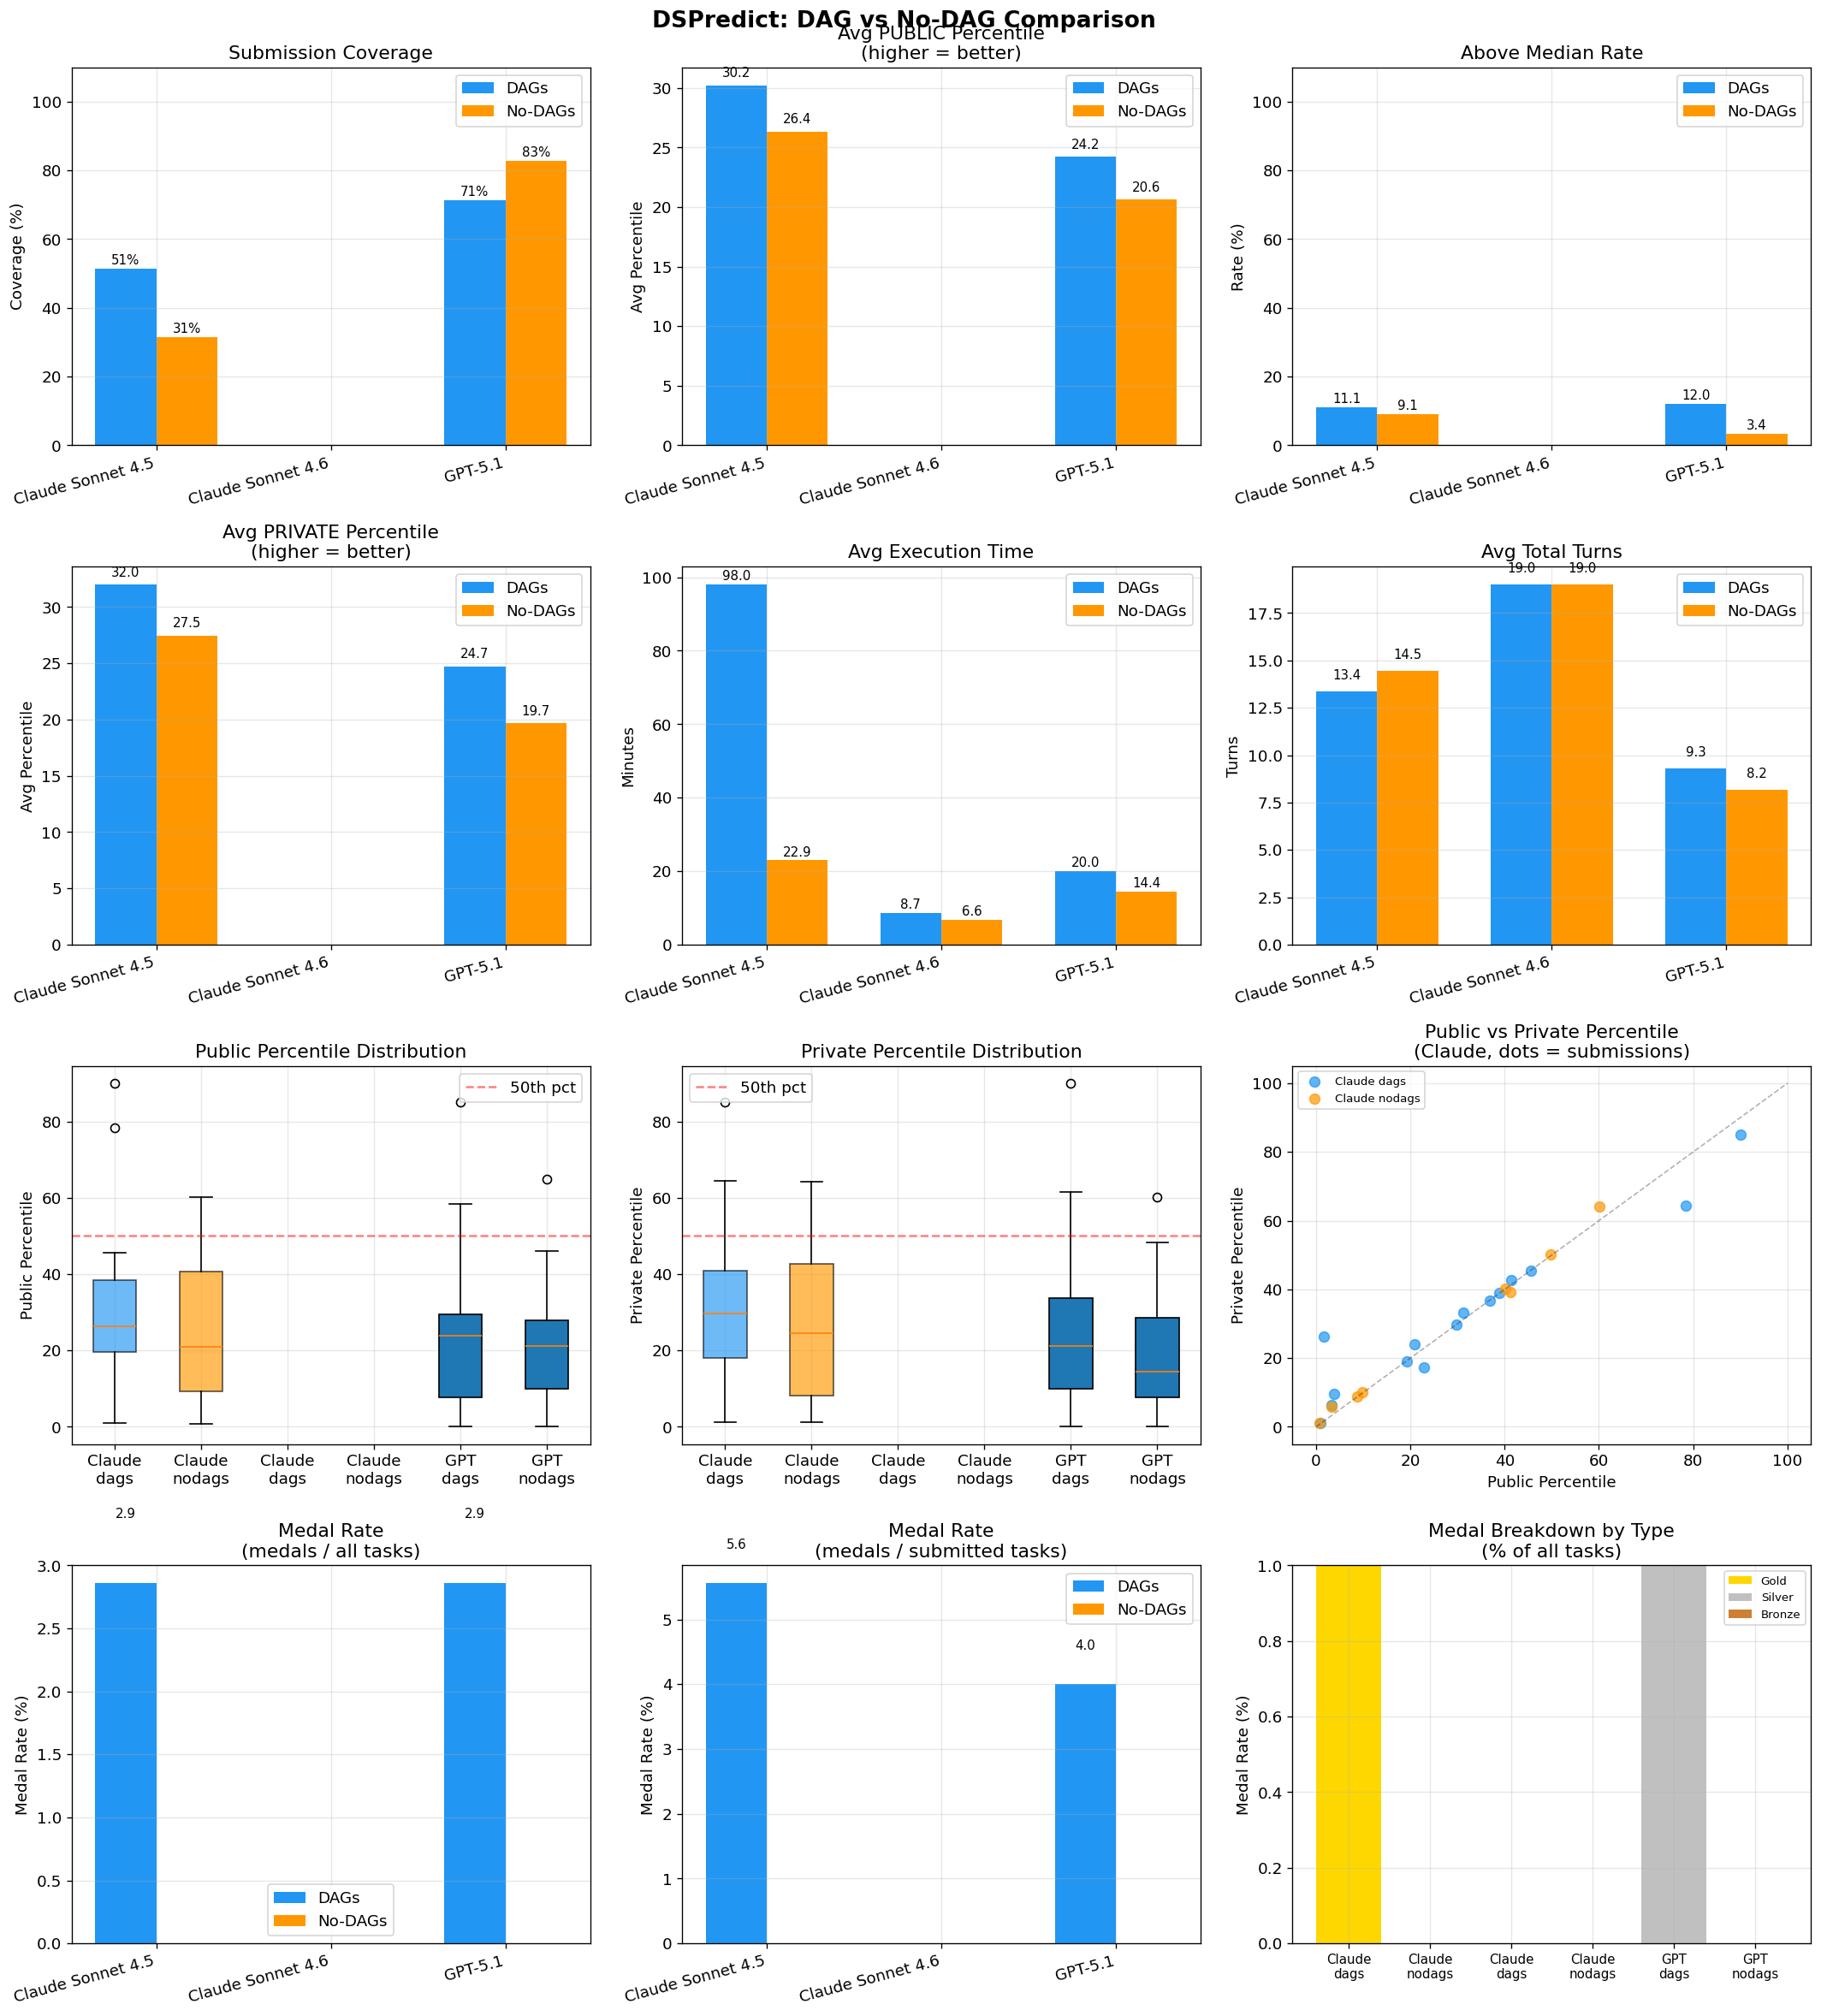

Saved dspredict_comparison.png


In [130]:
fig, axes = plt.subplots(4, 3, figsize=(18, 20))
fig.suptitle("DSPredict: DAG vs No-DAG Comparison", fontsize=16, fontweight="bold")

modes = ["dags", "nodags"]
x = np.arange(len(MODELS))
w = 0.35

def get_vals(fn):
    return {m: [fn(m, md) for md in modes] for m in MODELS}

def bar_pair(ax, vals, ylabel, title, ylim=None, fmt="{:.1f}"):
    b1 = ax.bar(x - w/2, [vals[m][0] for m in MODELS], w, label="DAGs",    color=COLORS["dags"])
    b2 = ax.bar(x + w/2, [vals[m][1] for m in MODELS], w, label="No-DAGs", color=COLORS["nodags"])
    ax.set_xticks(x)
    ax.set_xticklabels([MODEL_LABELS[m] for m in MODELS], rotation=15, ha="right")
    ax.set_ylabel(ylabel); ax.set_title(title); ax.legend()
    if ylim: ax.set_ylim(ylim)
    for bar in [*b1, *b2]:
        h = bar.get_height()
        if h > 0:
            ax.text(bar.get_x() + bar.get_width()/2, h + 0.5,
                    fmt.format(h), ha="center", va="bottom", fontsize=9)

# Row 0 ── Coverage / Public percentile / Above-median
def cov(m, md):
    data = dp_data.get((m, md), [])
    sub  = [r for r in data if "COMPLETE" in str(r.get("status",""))]
    return 100 * len(sub) / max(1, len(data))

def avg_pub_pct(m, md):
    vals = [r["pub_percentile"] for r in dp_data.get((m,md),[]) if r.get("pub_percentile") is not None]
    return np.mean(vals) if vals else 0

def avg_priv_pct(m, md):
    vals = [r["priv_percentile"] for r in dp_data.get((m,md),[]) if r.get("priv_percentile") is not None]
    return np.mean(vals) if vals else 0

def above_med(m, md):
    above = [r["pub_above_med"] for r in dp_data.get((m,md),[]) if r.get("pub_above_med") is not None]
    return 100 * sum(above) / len(above) if above else 0

bar_pair(axes[0,0], get_vals(cov),         "Coverage (%)",         "Submission Coverage", ylim=(0,110), fmt="{:.0f}%")
bar_pair(axes[0,1], get_vals(avg_pub_pct), "Avg Percentile",       "Avg PUBLIC Percentile\n(higher = better)")
bar_pair(axes[0,2], get_vals(above_med),   "Rate (%)",             "Above Median Rate", ylim=(0,110))

# Row 1 ── Private percentile / avg time / avg turns
bar_pair(axes[1,0], get_vals(avg_priv_pct), "Avg Percentile",      "Avg PRIVATE Percentile\n(higher = better)")

def avg_time(m, md):
    times = [r["execution_time"]/60 for r in dp_data.get((m,md),[]) if r.get("execution_time") is not None]
    return np.mean(times) if times else 0

def avg_turns(m, md):
    turns = [r["total_turns"] for r in dp_data.get((m,md),[]) if r.get("total_turns") is not None]
    return np.mean(turns) if turns else 0

bar_pair(axes[1,1], get_vals(avg_time),  "Minutes", "Avg Execution Time")
bar_pair(axes[1,2], get_vals(avg_turns), "Turns",   "Avg Total Turns")

# Row 2 ── Public vs Private percentile distribution boxes (side by side)
for col, (pct_key, label) in enumerate([("pub_percentile", "Public"), ("priv_percentile", "Private")]):
    ax = axes[2, col]
    pct_data, box_labels = [], []
    for m in MODELS:
        for md in modes:
            vals = [r[pct_key] for r in dp_data.get((m,md),[]) if r.get(pct_key) is not None]
            pct_data.append(vals)
            box_labels.append(f"{'Claude' if 'claude' in m else 'GPT'}\n{md}")
    bp = ax.boxplot([d for d in pct_data], labels=box_labels, patch_artist=True)
    for patch, col_c in zip(bp["boxes"], [COLORS["dags"], COLORS["nodags"]] * 2):
        patch.set_facecolor(col_c); patch.set_alpha(0.65)
    ax.axhline(50, color="red", ls="--", alpha=0.5, label="50th pct")
    ax.set_ylabel(f"{label} Percentile"); ax.set_title(f"{label} Percentile Distribution"); ax.legend()

# Public vs Private scatter per sample (Claude dags only)
ax = axes[2, 2]
for (model, mode), color in [
    (("claude-sonnet-4-5","dags"),   COLORS["dags"]),
    (("claude-sonnet-4-5","nodags"), COLORS["nodags"]),
]:
    data = dp_data.get((model, mode), [])
    pub  = [r["pub_percentile"]  for r in data if r.get("pub_percentile")  and r.get("priv_percentile")]
    priv = [r["priv_percentile"] for r in data if r.get("pub_percentile")  and r.get("priv_percentile")]
    label = f"Claude {mode}"
    ax.scatter(pub, priv, alpha=0.7, color=color, label=label, s=50)
ax.plot([0,100],[0,100], "k--", alpha=0.3, lw=1)
ax.set_xlabel("Public Percentile"); ax.set_ylabel("Private Percentile")
ax.set_title("Public vs Private Percentile\n(Claude, dots = submissions)")
ax.legend(fontsize=8)

# Row 3 ── Medal rate (% of all tasks), medal rate of submitted, medal type breakdown
MEDAL_TYPES = ["gold", "silver", "bronze"]
MEDAL_COLORS = {"gold": "#FFD700", "silver": "#C0C0C0", "bronze": "#CD7F32", "none": "#DDDDDD"}

def medal_rate_all(m, md):
    """Medals earned / total tasks (%)"""
    data = dp_data.get((m, md), [])
    sub  = [r for r in data if "COMPLETE" in str(r.get("status", ""))]
    medals = [r["public_medal"] for r in sub if r.get("public_medal") not in (None, "none")]
    return 100 * len(medals) / max(1, len(data))

def medal_rate_submitted(m, md):
    """Medals earned / submitted tasks (%)"""
    data = dp_data.get((m, md), [])
    sub  = [r for r in data if "COMPLETE" in str(r.get("status", ""))]
    medals = [r["public_medal"] for r in sub if r.get("public_medal") not in (None, "none")]
    return 100 * len(medals) / max(1, len(sub))

bar_pair(axes[3, 0], get_vals(medal_rate_all),       "Medal Rate (%)", "Medal Rate\n(medals / all tasks)")
bar_pair(axes[3, 1], get_vals(medal_rate_submitted), "Medal Rate (%)", "Medal Rate\n(medals / submitted tasks)")

# Medal type breakdown (stacked bar)
ax = axes[3, 2]
x_pos = np.arange(len(MODELS) * 2)
tick_labels = [f"{'Claude' if 'claude' in m else 'GPT'}\n{md}" for m in MODELS for md in modes]
bottoms = np.zeros(len(x_pos))
for mtype in MEDAL_TYPES:
    heights = []
    for m in MODELS:
        for md in modes:
            data = dp_data.get((m, md), [])
            sub  = [r for r in data if "COMPLETE" in str(r.get("status", ""))]
            count = sum(1 for r in sub if r.get("public_medal") == mtype)
            heights.append(count)
    ax.bar(x_pos, heights, bottom=bottoms, color=MEDAL_COLORS[mtype], label=mtype.capitalize())
    bottoms += np.array(heights)
ax.set_xticks(x_pos)
ax.set_xticklabels(tick_labels, fontsize=9)
ax.set_ylabel("Medal Rate (%)")
ax.set_title("Medal Breakdown by Type\n(% of all tasks)")
ax.legend(fontsize=8)


plt.tight_layout()
plt.savefig(RESULTS_DIR / "dspredict_comparison.png", bbox_inches="tight", dpi=150)
plt.show()
print("Saved dspredict_comparison.png")


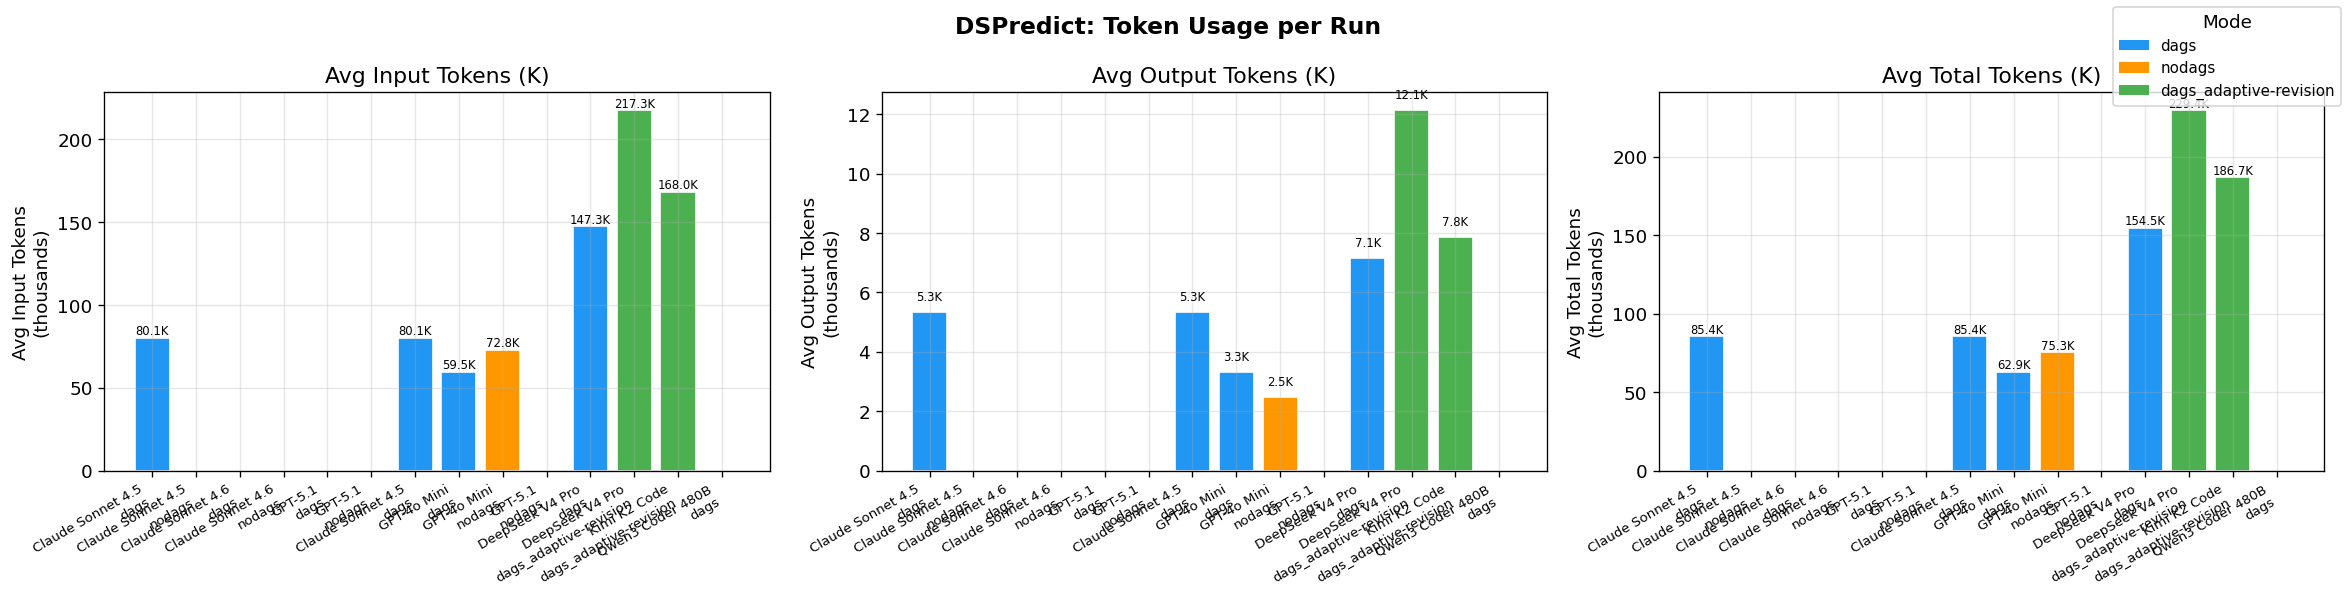

Saved dspredict_token_usage.png


In [131]:
# ── Token Usage Plot ─────────────────────────────────────────────────────────
# Token data is available for Hard runs; Sampled runs may show 0 if not captured.
all_run_keys = list(dp_data.keys()) + list(dp_hard_data.keys())
all_run_data = {**dp_data, **{(f"{m} [hard]", md): v for (m, md), v in dp_hard_data.items()}}
tok_labels   = [f"{MODEL_LABELS.get(m, m)}\n{md}" for m, md in all_run_keys]
x_tok = np.arange(len(all_run_keys))

fig, axes = plt.subplots(1, 3, figsize=(max(18, len(all_run_keys) * 1.4), 5))
fig.suptitle("DSPredict: Token Usage per Run", fontsize=14, fontweight="bold")

tok_fields = [
    ("input_tokens",  "Avg Input Tokens (K)",  "Avg Input Tokens\n(thousands)"),
    ("output_tokens", "Avg Output Tokens (K)", "Avg Output Tokens\n(thousands)"),
    ("total_tokens",  "Avg Total Tokens (K)",  "Avg Total Tokens\n(thousands)"),
]

def avg_tok(key, data_list):
    vals = [r[key] for r in data_list if r.get(key) is not None]
    return np.mean(vals) / 1_000 if vals else 0

for ax, (field, title, ylabel) in zip(axes, tok_fields):
    heights = []
    colors  = []
    for m, md in all_run_keys:
        data_list = dp_data.get((m, md)) or dp_hard_data.get((m, md), [])
        heights.append(avg_tok(field, data_list))
        colors.append(COLORS.get(md, "#9C27B0"))
    bars = ax.bar(x_tok, heights, color=colors, edgecolor="white")
    ax.set_xticks(x_tok)
    ax.set_xticklabels(tok_labels, rotation=30, ha="right", fontsize=8)
    ax.set_ylabel(ylabel); ax.set_title(title)
    for bar, v in zip(bars, heights):
        if v > 0:
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                    f"{v:.1f}K", ha="center", va="bottom", fontsize=7)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(facecolor=COLORS[m], label=m) for m in ["dags","nodags","dags_adaptive-revision"]],
           loc="upper right", fontsize=9, title="Mode")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "dspredict_token_usage.png", bbox_inches="tight", dpi=150)
plt.show()
print("Saved dspredict_token_usage.png")


In [143]:
# ── Submission Status Breakdown ───────────────────────────────────────────────
print("=== Submission Status Breakdown (DSPredict) ===\n")

status_rows = []
for (model, mode), data in dp_data.items():
    counts = {}
    for r in data:
        s = r.get("status", "SUBMISSIONSTATUS.NO_SUBMISSION")
        if not s or s == "":
            s = "SUBMISSIONSTATUS.NO_SUBMISSION"
        counts[s] = counts.get(s, 0) + 1
    total = len(data)
    label = f"{MODEL_LABELS[model]} / {mode}"
    print(f"{label}:")
    for status, cnt in sorted(counts.items()):
        print(f"  - {status}: {cnt}")
    print()
    for status, cnt in counts.items():
        status_rows.append({
            "Model": model, "Mode": mode, "Label": label,
            "Status": status, "Count": cnt, "Total": total,
            "Rate (%)": round(100 * cnt / total, 1),
        })

status_df = pd.DataFrame(status_rows)
pivot_status = status_df.pivot_table(
    index="Status", columns=["Model", "Mode"], values="Count", aggfunc="sum"
).fillna(0).astype(int)

print("=== Status Counts Pivot ===")
display(pivot_status)


=== Submission Status Breakdown (DSPredict) ===

Claude Sonnet 4.5 / dags:
  - SUBMISSIONSTATUS.COMPLETE: 18
  - SUBMISSIONSTATUS.ERROR: 8
  - SUBMISSIONSTATUS.NO_SUBMISSION: 9

Claude Sonnet 4.5 / nodags:
  - SUBMISSIONSTATUS.COMPLETE: 11
  - SUBMISSIONSTATUS.ERROR: 4
  - SUBMISSIONSTATUS.NO_SUBMISSION: 20

Claude Sonnet 4.6 / dags:
  - SUBMISSIONSTATUS.ERROR: 10

Claude Sonnet 4.6 / nodags:
  - SUBMISSIONSTATUS.ERROR: 10

GPT-5.1 / dags:
  - SUBMISSIONSTATUS.COMPLETE: 25
  - SUBMISSIONSTATUS.ERROR: 3
  - SUBMISSIONSTATUS.NO_SUBMISSION: 7

GPT-5.1 / nodags:
  - SUBMISSIONSTATUS.COMPLETE: 29
  - SUBMISSIONSTATUS.ERROR: 3
  - SUBMISSIONSTATUS.NO_SUBMISSION: 3

=== Status Counts Pivot ===


Model                          claude-sonnet-4-5        claude-sonnet-4-6  \
Mode                                        dags nodags              dags   
Status                                                                      
SUBMISSIONSTATUS.COMPLETE                     18     11                 0   
SUBMISSIONSTATUS.ERROR                         8      4                10   
SUBMISSIONSTATUS.NO_SUBMISSION                 9     20                 0   

Model                                 gpt-5.1         
Mode                           nodags    dags nodags  
Status                                                
SUBMISSIONSTATUS.COMPLETE           0      25     29  
SUBMISSIONSTATUS.ERROR             10       3      3  
SUBMISSIONSTATUS.NO_SUBMISSION      0       7      3

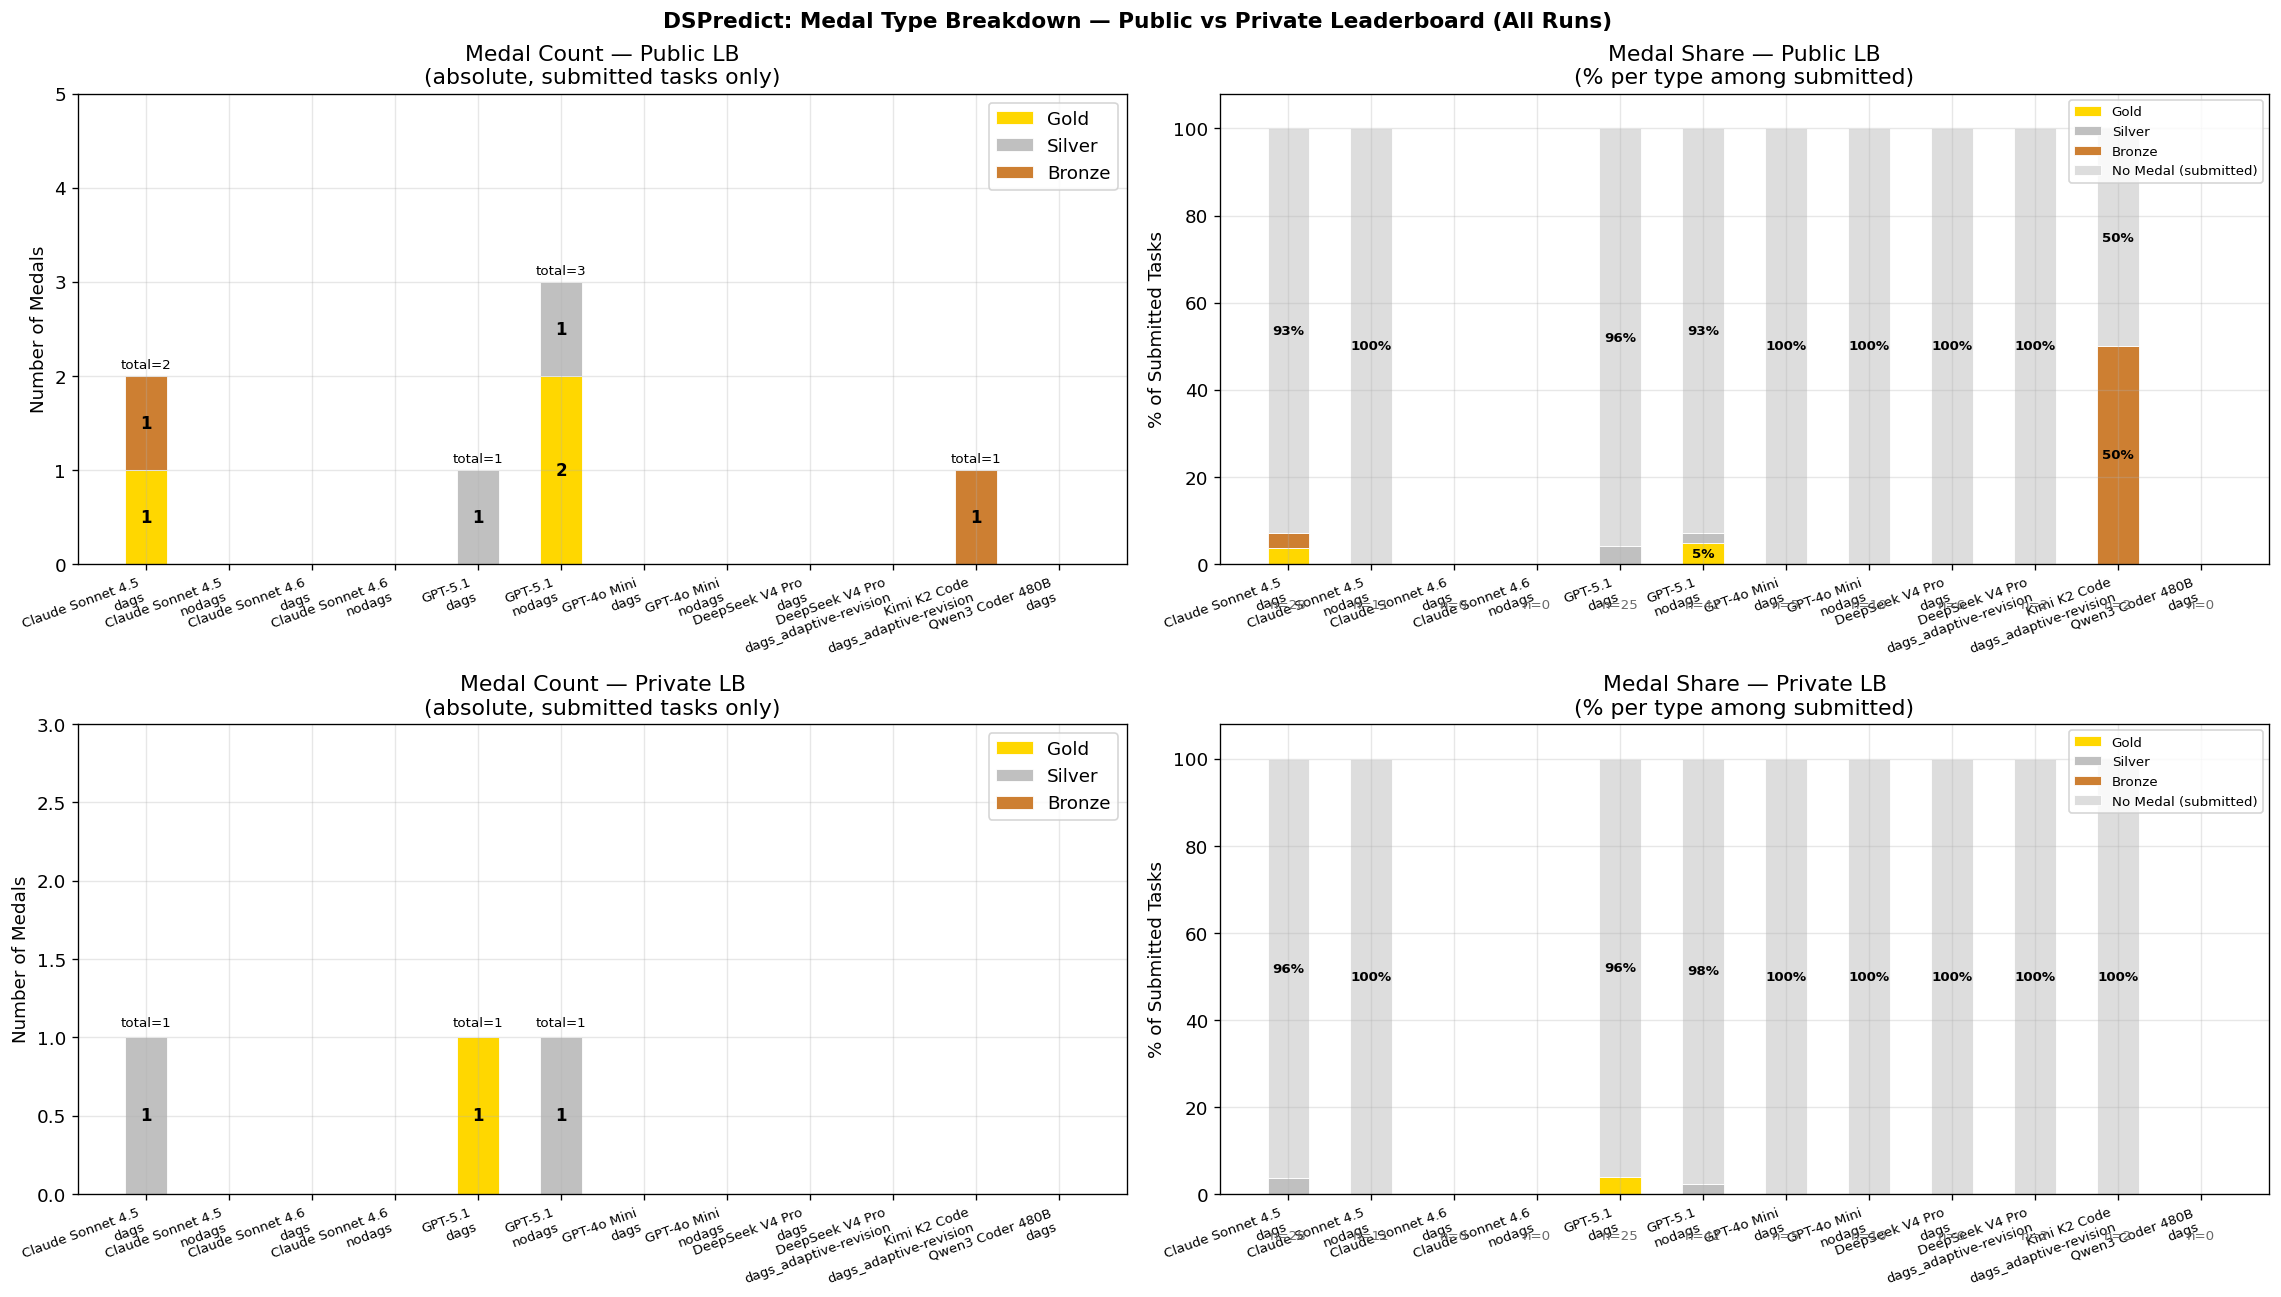

Saved dspredict_medal_breakdown.png

=== Medal Counts (Public | Private) ===
  Claude Sonnet 4.5 dags                    pub: {'gold': 1, 'silver': 0, 'bronze': 1}  priv: {'gold': 0, 'silver': 1, 'bronze': 0}
  Claude Sonnet 4.5 nodags                  pub: {'gold': 0, 'silver': 0, 'bronze': 0}  priv: {'gold': 0, 'silver': 0, 'bronze': 0}
  Claude Sonnet 4.6 dags                    pub: {'gold': 0, 'silver': 0, 'bronze': 0}  priv: {'gold': 0, 'silver': 0, 'bronze': 0}
  Claude Sonnet 4.6 nodags                  pub: {'gold': 0, 'silver': 0, 'bronze': 0}  priv: {'gold': 0, 'silver': 0, 'bronze': 0}
  GPT-5.1 dags                              pub: {'gold': 0, 'silver': 1, 'bronze': 0}  priv: {'gold': 1, 'silver': 0, 'bronze': 0}
  GPT-5.1 nodags                            pub: {'gold': 2, 'silver': 1, 'bronze': 0}  priv: {'gold': 0, 'silver': 1, 'bronze': 0}
  GPT-4o Mini dags                          pub: {'gold': 0, 'silver': 0, 'bronze': 0}  priv: {'gold': 0, 'silver': 0, 'bronze': 0}

In [133]:
# ── Medal Type Breakdown — all runs (sampled + hard) ─────────────────────────
MEDAL_TYPES       = ["gold", "silver", "bronze"]
MEDAL_COLORS      = {"gold": "#FFD700", "silver": "#C0C0C0", "bronze": "#CD7F32"}
MEDAL_TYPES_FULL  = ["gold", "silver", "bronze", "none"]
MEDAL_COLORS_FULL = {**MEDAL_COLORS, "none": "#DDDDDD"}
MEDAL_LABELS_FULL = {"gold": "Gold", "silver": "Silver", "bronze": "Bronze", "none": "No Medal (submitted)"}

# Build ordered list: sampled first, then hard
all_run_keys   = list(dp_data.keys()) + [k for k in dp_hard_data.keys() if k not in dp_data]
all_run_data   = {**dp_data, **dp_hard_data}
all_run_labels = [f"{MODEL_LABELS.get(m, m)}\n{md}" for m, md in all_run_keys]
x_pos          = np.arange(len(all_run_keys))
n_runs         = len(all_run_keys)
bar_w          = max(0.5, min(0.8, 6 / n_runs))  # auto-width

fig, axes = plt.subplots(2, 2, figsize=(max(16, n_runs * 1.6), 11))
fig.suptitle("DSPredict: Medal Type Breakdown — Public vs Private Leaderboard (All Runs)", fontsize=13, fontweight="bold")

for row_i, (lb_key, lb_label) in enumerate([("public_medal", "Public LB"), ("private_medal", "Private LB")]):

    # Left: absolute medal counts
    ax = axes[row_i, 0]
    bottoms = np.zeros(n_runs)
    for mtype in MEDAL_TYPES:
        heights = []
        for key in all_run_keys:
            data  = all_run_data.get(key, [])
            sub   = [r for r in data if "COMPLETE" in str(r.get("status", ""))]
            heights.append(sum(1 for r in sub if r.get(lb_key) == mtype))
        bars = ax.bar(x_pos, heights, bottom=bottoms, width=bar_w,
                      color=MEDAL_COLORS[mtype], label=mtype.capitalize(),
                      edgecolor="white", linewidth=0.5)
        for bar, h in zip(bars, heights):
            if h > 0:
                ax.text(bar.get_x() + bar.get_width()/2, bar.get_y() + h/2,
                        str(int(h)), ha="center", va="center", fontsize=10, fontweight="bold")
        bottoms += np.array(heights)
    for xi, total in enumerate(bottoms):
        if total > 0:
            ax.text(xi, total + 0.05, f"total={int(total)}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x_pos); ax.set_xticklabels(all_run_labels, fontsize=8, rotation=20, ha="right")
    ax.set_ylabel("Number of Medals")
    ax.set_title(f"Medal Count — {lb_label}\n(absolute, submitted tasks only)")
    ax.legend(loc="upper right"); ax.set_ylim(0, max(bottoms) + 2 if max(bottoms) > 0 else 5)

    # Right: 100% stacked among submitted
    ax = axes[row_i, 1]
    bottoms_pct = np.zeros(n_runs)
    for mtype in MEDAL_TYPES_FULL:
        heights_pct = []
        for key in all_run_keys:
            data  = all_run_data.get(key, [])
            sub   = [r for r in data if "COMPLETE" in str(r.get("status", ""))]
            n_sub = max(1, len(sub))
            heights_pct.append(100 * sum(1 for r in sub if (r.get(lb_key) or "none") == mtype) / n_sub)
        bars = ax.bar(x_pos, heights_pct, bottom=bottoms_pct, width=bar_w,
                      color=MEDAL_COLORS_FULL[mtype], label=MEDAL_LABELS_FULL[mtype],
                      edgecolor="white", linewidth=0.5)
        for bar, h in zip(bars, heights_pct):
            if h > 4:
                ax.text(bar.get_x() + bar.get_width()/2, bar.get_y() + h/2,
                        f"{h:.0f}%", ha="center", va="center", fontsize=8, fontweight="bold")
        bottoms_pct += np.array(heights_pct)
    ax.set_xticks(x_pos); ax.set_xticklabels(all_run_labels, fontsize=8, rotation=20, ha="right")
    ax.set_ylabel("% of Submitted Tasks")
    ax.set_title(f"Medal Share — {lb_label}\n(% per type among submitted)")
    ax.legend(loc="upper right", fontsize=8); ax.set_ylim(0, 108)
    for xi, key in enumerate(all_run_keys):
        sub = [r for r in all_run_data.get(key, []) if "COMPLETE" in str(r.get("status", ""))]
        ax.text(xi, -8, f"n={len(sub)}", ha="center", va="top", fontsize=8, color="dimgray")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "dspredict_medal_breakdown.png", bbox_inches="tight", dpi=150)
plt.show()
print("Saved dspredict_medal_breakdown.png")

print("\n=== Medal Counts (Public | Private) ===")
for key in all_run_keys:
    m, md = key
    label = f"{MODEL_LABELS.get(m, m)} {md}"
    sub   = [r for r in all_run_data.get(key, []) if "COMPLETE" in str(r.get("status", ""))]
    pub   = {t: sum(1 for r in sub if r.get("public_medal")  == t) for t in MEDAL_TYPES}
    priv  = {t: sum(1 for r in sub if r.get("private_medal") == t) for t in MEDAL_TYPES}
    print(f"  {label:<40}  pub: {pub}  priv: {priv}")


## 2 · DSBio Results

In [134]:
def load_dsbio(path):
    with open(path) as f:
        data = json.load(f)
    rows = []
    for item in data:
        em = item.get("metrics", {}).get("exact_match", {})
        rows.append({
            "sample_id":      item.get("sample_id"),
            "exact_match":    em.get("score"),
            "execution_time": item.get("execution_time"),
            "total_turns":    item.get("total_turns"),
            "success":        item.get("success"),
            "query_id":       item.get("extra_info", {}).get("query_id"),
            "trajectory":     item.get("trajectory", []),
        })
    return rows

bio_data = {}
for key, path in BIO_RUNS.items():
    if path.exists():
        bio_data[key] = load_dsbio(path)
        print(f"  {key[0]}/{key[1]}: {len(bio_data[key])} samples")
    else:
        print(f"  MISSING: {path}")

# Summary
bio_rows = []
for (model, mode), data in bio_data.items():
    em    = [r["exact_match"]    for r in data if r["exact_match"]    is not None]
    times = [r["execution_time"] for r in data if r["execution_time"] is not None]
    turns = [r["total_turns"]    for r in data if r["total_turns"]    is not None]
    succ  = [r["success"]        for r in data if r["success"]        is not None]
    bio_rows.append({
        "Model":               model,
        "Mode":                mode,
        "N":                   len(data),
        "Exact Match (%)":     round(100 * np.mean(em), 1) if em else None,
        "Success Rate (%)":    round(100 * sum(succ) / len(succ), 1) if succ else None,
        "Avg Time (s)":        round(np.mean(times), 1) if times else None,
        "Avg Turns":           round(np.mean(turns), 1) if turns else None,
    })
bio_sum = pd.DataFrame(bio_rows)
print("\n=== DSBio Run Summary ===")
display(bio_sum.set_index(["Model", "Mode"]))


  claude-sonnet-4-5/dags: 35 samples
  claude-sonnet-4-5/nodags: 35 samples
  claude-sonnet-4-6/dags: 10 samples
  claude-sonnet-4-6/nodags: 10 samples
  gpt-5.1/dags: 35 samples
  gpt-5.1/nodags: 35 samples
  gpt-4o/nodags: 10 samples

=== DSBio Run Summary ===


N  Exact Match (%)  Success Rate (%)  Avg Time (s)  \
Model             Mode                                                          
claude-sonnet-4-5 dags    35             45.7              97.1         341.7   
                  nodags  35             40.0              51.4         273.0   
claude-sonnet-4-6 dags    10             20.0              30.0         287.1   
                  nodags  10             10.0              20.0         297.4   
gpt-5.1           dags    35             17.1             100.0         434.9   
                  nodags  35             37.1              97.1         144.0   
gpt-4o            nodags  10             10.0              70.0         311.5   

                          Avg Turns  
Model             Mode               
claude-sonnet-4-5 dags          9.3  
                  nodags       12.7  
claude-sonnet-4-6 dags         14.2  
                  nodags       13.6  
gpt-5.1           dags          4.0  
                  nodags        5.6  
gpt-4o            nodags        9.9

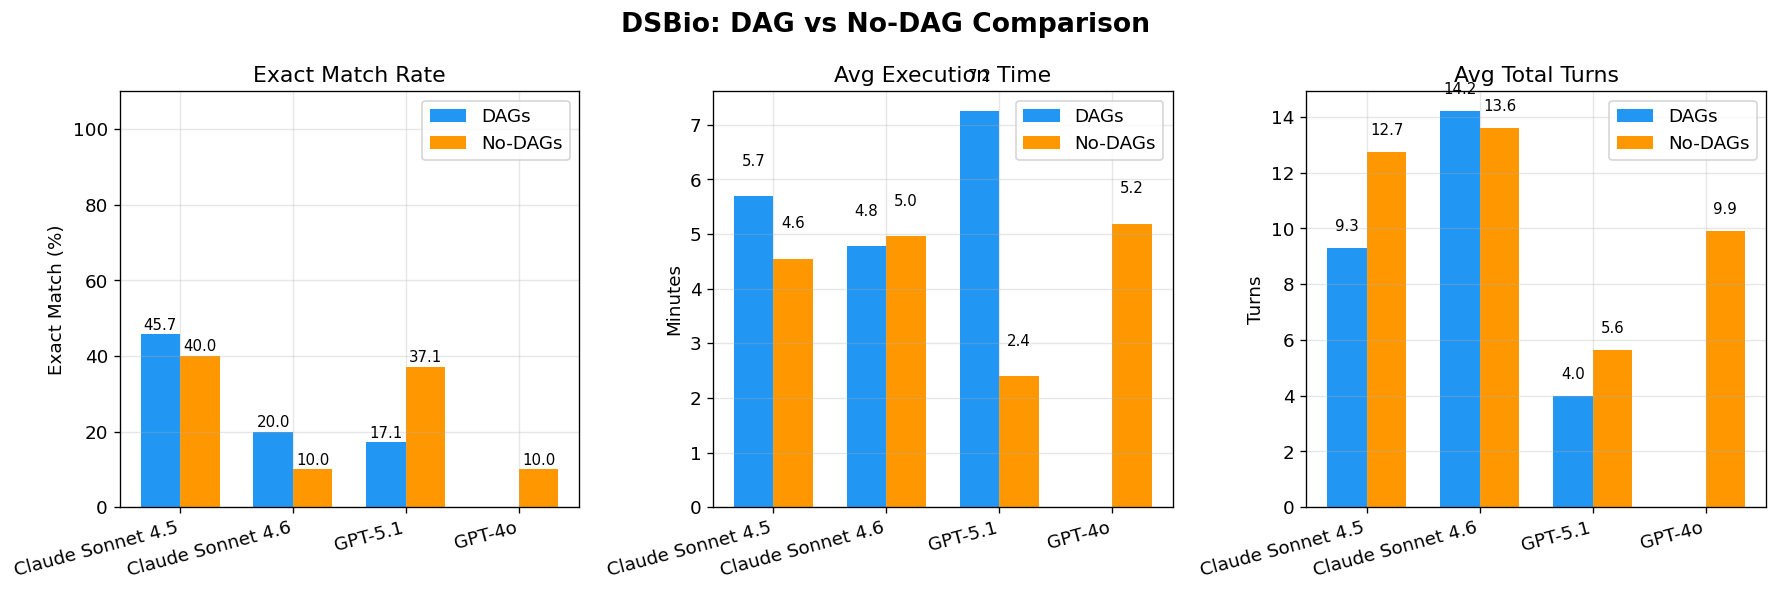

Saved dsbio_comparison.png


In [135]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("DSBio: DAG vs No-DAG Comparison", fontsize=16, fontweight="bold")
x = np.arange(len(BIO_MODELS)); w = 0.35

def bio_mean(m, md, key, scale=1.0):
    data = bio_data.get((m, md), [])
    vals = [r[key] for r in data if r.get(key) is not None]
    return scale * np.mean(vals) if vals else 0

for ax, (key, scale, ylabel, title) in zip(axes, [
    ("exact_match",    100,  "Exact Match (%)",  "Exact Match Rate"),
    ("execution_time", 1/60, "Minutes",           "Avg Execution Time"),
    ("total_turns",    1,    "Turns",             "Avg Total Turns"),
]):
    v_dags   = [bio_mean(m, "dags",   key, scale) for m in BIO_MODELS]
    v_nodags = [bio_mean(m, "nodags", key, scale) for m in BIO_MODELS]
    b1 = ax.bar(x - w/2, v_dags,   w, label="DAGs",    color=COLORS["dags"])
    b2 = ax.bar(x + w/2, v_nodags, w, label="No-DAGs", color=COLORS["nodags"])
    ax.set_xticks(x)
    ax.set_xticklabels([MODEL_LABELS.get(m, m) for m in BIO_MODELS], rotation=15, ha="right")
    ax.set_ylabel(ylabel); ax.set_title(title); ax.legend()
    if key == "exact_match":
        ax.set_ylim(0, 110)
    for bar in [*b1, *b2]:
        h = bar.get_height()
        if h > 0:
            ax.text(bar.get_x() + bar.get_width()/2, h + 0.5,
                    f"{h:.1f}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "dsbio_comparison.png", bbox_inches="tight", dpi=150)
plt.show()
print("Saved dsbio_comparison.png")


## 3 · DAG Structure Analysis

In [136]:
def extract_dags_from_trajectory(trajectory):
    """Parse JSON DAG blocks embedded in assistant turn content."""
    dags = []
    for turn in trajectory:
        if turn.get("role") != "assistant":
            continue
        for block in re.findall(r"```json\s*(.*?)\s*```", turn.get("content", ""), re.DOTALL):
            try:
                obj = json.loads(block)
                if isinstance(obj, dict) and "dag_type" in obj and "nodes" in obj:
                    dags.append({
                        "turn":     turn.get("turn"),
                        "dag_type": obj["dag_type"],
                        "nodes":    obj.get("nodes", []),
                        "edges":    obj.get("edges", []),
                        "graph_id": obj.get("graph_id", ""),
                    })
            except json.JSONDecodeError:
                pass
    return dags


def load_dag_dir(dag_dir):
    """Load pre-parsed DAG JSON files from dags/ subdirectory."""
    result = {}
    for fp in dag_dir.glob("*.json"):
        with open(fp) as f:
            d = json.load(f)
        result[(d.get("model",""), d.get("question_id",""))] = d
    return result


parsed_dags = load_dag_dir(DAG_DIR)
print(f"Pre-parsed DAG files: {len(parsed_dags)}")
for (model, qid), d in parsed_dags.items():
    print(f"  {model} / {qid}  —  {len(d.get('dags',[]))} dags, {d.get('n_revisions')} revisions")

# Collect trajectory-embedded DAGs from DSPredict dags runs
traj_dags = {}
for (model, mode), data in dp_data.items():
    if mode != "dags":
        continue
    for row in data:
        dags = extract_dags_from_trajectory(row.get("trajectory", []))
        if dags:
            traj_dags[(model, row["challenge"])] = dags

print(f"\nChallenges with embedded trajectory DAGs: {len(traj_dags)}")


Pre-parsed DAG files: 16
  gpt-5.1 / statoil-iceberg-classifier-challenge  —  2 dags, 0 revisions
  gpt-5.1 / ashrae-energy-prediction  —  2 dags, 0 revisions
  gpt-5.1 / 2  —  1 dags, 1 revisions
  gpt-5.1 / siim-acr-pneumothorax-segmentation  —  2 dags, 0 revisions
  gpt-5.1 / mens-machine-learning-competition-2018  —  2 dags, 0 revisions
  gpt-5.1 / 9  —  1 dags, 1 revisions
  claude-sonnet-4-5 / geolifeclef-2024  —  2 dags, 0 revisions
  gpt-5.1 / santander-value-prediction-challenge  —  3 dags, 0 revisions
  gpt-5.1 / 4  —  1 dags, 1 revisions
  gpt-4o-mini / rsna-pneumonia-detection-challenge  —  2 dags, 0 revisions
  gpt-5.1 / mens-march-mania-2022  —  3 dags, 0 revisions
  gpt-4o-mini / womens-machine-learning-competition-2019  —  2 dags, 0 revisions
  gpt-5.1 / career-con-2019  —  2 dags, 0 revisions
  gpt-5.1 / sp-society-camera-model-identification  —  1 dags, 1 revisions
  gpt-5.1 / imaterialist-challenge-fashion-2018  —  2 dags, 0 revisions
  claude-sonnet-4-5 / stanford-c

In [137]:
dag_stats = []
for (model, challenge), dags in traj_dags.items():
    reasoning = [d for d in dags if d["dag_type"] == "reasoning"]
    impl      = [d for d in dags if "implementation" in d["dag_type"]]
    revisions = [d for d in dags if "revision" in d["dag_type"]]
    dag_stats.append({
        "Model":           model,
        "Challenge":       challenge,
        "Total DAGs":      len(dags),
        "Reasoning":       len(reasoning),
        "Implementations": len(impl),
        "Revisions":       len(revisions),
        "Avg nodes (R)":   round(np.mean([len(d["nodes"]) for d in reasoning]), 1) if reasoning else 0,
        "Avg nodes (I)":   round(np.mean([len(d["nodes"]) for d in impl]),      1) if impl      else 0,
    })

dag_df = pd.DataFrame(dag_stats).sort_values(["Model", "Challenge"])
print("=== DAG Structure Statistics ===")
display(dag_df.set_index(["Model", "Challenge"]))


=== DAG Structure Statistics ===


Total DAGs  \
Model             Challenge                                               
claude-sonnet-4-5 LANL-Earthquake-Prediction                          2   
                  career-con-2019                                     2   
                  digit-recognizer                                    2   
                  gendered-pronoun-resolution                         2   
                  home-credit-default-risk                            2   
                  humpback-whale-identification                       2   
                  ieee-fraud-detection                                2   
                  imaterialist-challenge-fashion-2018                 2   
                  imaterialist-challenge-furniture-2018               2   
                  liverpool-ion-switching                             2   
                  m5-forecasting-accuracy                             2   
                  mens-machine-learning-competition-2018              2   
                  mens-march-mania-2022                               2   
                  nlp-getting-started                                 2   
                  predict-ai-model-runtime                            2   
                  rsna-pneumonia-detection-challenge                  2   
                  santander-customer-transaction-prediction           2   
                  santander-value-prediction-challenge                2   
                  siim-acr-pneumothorax-segmentation                  2   
                  statoil-iceberg-classifier-challenge                2   
                  store-sales-time-series-forecasting                 2   
                  talkingdata-adtracking-fraud-detection              2   
                  trec-covid-information-retrieval                    2   
                  web-traffic-time-series-forecasting                 2   
                  youtube8m-2018                                      2   
                  youtube8m-2019                                      2   
                  nan                                                 2   
claude-sonnet-4-6 ashrae-energy-prediction                            2   
                  elo-merchant-category-recommendation                2   
                  gendered-pronoun-resolution                         2   
                  geolifeclef-2024                                    2   
                  imaterialist-challenge-fashion-2018                 2   
                  imaterialist-challenge-furniture-2018               2   
                  liverpool-ion-switching                             2   
                  stanford-covid-vaccine                              2   
                  talkingdata-adtracking-fraud-detection              2   
                  understanding_cloud_organization                    2   

                                                             Reasoning  \
Model             Challenge                                              
claude-sonnet-4-5 LANL-Earthquake-Prediction                         1   
                  career-con-2019                                    1   
                  digit-recognizer                                   1   
                  gendered-pronoun-resolution                        1   
                  home-credit-default-risk                           1   
                  humpback-whale-identification                      1   
                  ieee-fraud-detection                               1   
                  imaterialist-challenge-fashion-2018                1   
                  imaterialist-challenge-furniture-2018              1   
                  liverpool-ion-switching                            1   
                  m5-forecasting-accuracy                            1   
                  mens-machine-learning-competition-2018             1   
                  mens-march-mania-2022                              1   
                  nlp-get

In [138]:
dag_df["Challenge"]

20                   LANL-Earthquake-Prediction
9                               career-con-2019
7                              digit-recognizer
1                   gendered-pronoun-resolution
25                     home-credit-default-risk
14                humpback-whale-identification
11                         ieee-fraud-detection
4           imaterialist-challenge-fashion-2018
3         imaterialist-challenge-furniture-2018
2                       liverpool-ion-switching
18                      m5-forecasting-accuracy
23       mens-machine-learning-competition-2018
21                        mens-march-mania-2022
15                          nlp-getting-started
13                     predict-ai-model-runtime
6            rsna-pneumonia-detection-challenge
17    santander-customer-transaction-prediction
24         santander-value-prediction-challenge
8            siim-acr-pneumothorax-segmentation
22         statoil-iceberg-classifier-challenge
10          store-sales-time-series-fore

In [139]:
import textwrap

def draw_dag(dag, ax, title=""):
    G = nx.DiGraph()
    node_labels = {}
    for n in dag.get("nodes", []):
        nid   = n["id"]
        label = n.get("label", nid)
        if len(label) > 70:
            label = label[:67] + "..."
        G.add_node(nid)
        node_labels[nid] = label

    for e in dag.get("edges", []):
        G.add_edge(e["source"], e["target"])

    if not G.nodes:
        ax.text(0.5, 0.5, "(empty)", ha="center", va="center", transform=ax.transAxes)
        ax.set_title(title); ax.axis("off"); return

    try:
        pos = nx.nx_agraph.graphviz_layout(G, prog="dot")
    except Exception:
        pos = nx.spring_layout(G, seed=42)

    dtype = dag.get("dag_type", "")
    nc = "#90CAF9" if dtype == "reasoning" else ("#A5D6A7" if dtype == "implementation" else "#FFCC80")

    nx.draw_networkx_edges(G, pos, ax=ax, arrows=True, arrowstyle="->",
                           arrowsize=15, edge_color="#555", width=1.5,
                           connectionstyle="arc3,rad=0.05")
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=nc, node_size=700, alpha=0.9)
    wrapped = {n: "\n".join(textwrap.wrap(lbl, 22)) for n, lbl in node_labels.items() if n in G.nodes}
    nx.draw_networkx_labels(G, pos, labels=wrapped, ax=ax, font_size=6)
    ax.set_title(title, fontsize=9, fontweight="bold"); ax.axis("off")


### 3.1 · DSPredict trajectory DAGs (reasoning → implementation revisions)

challenge:  None


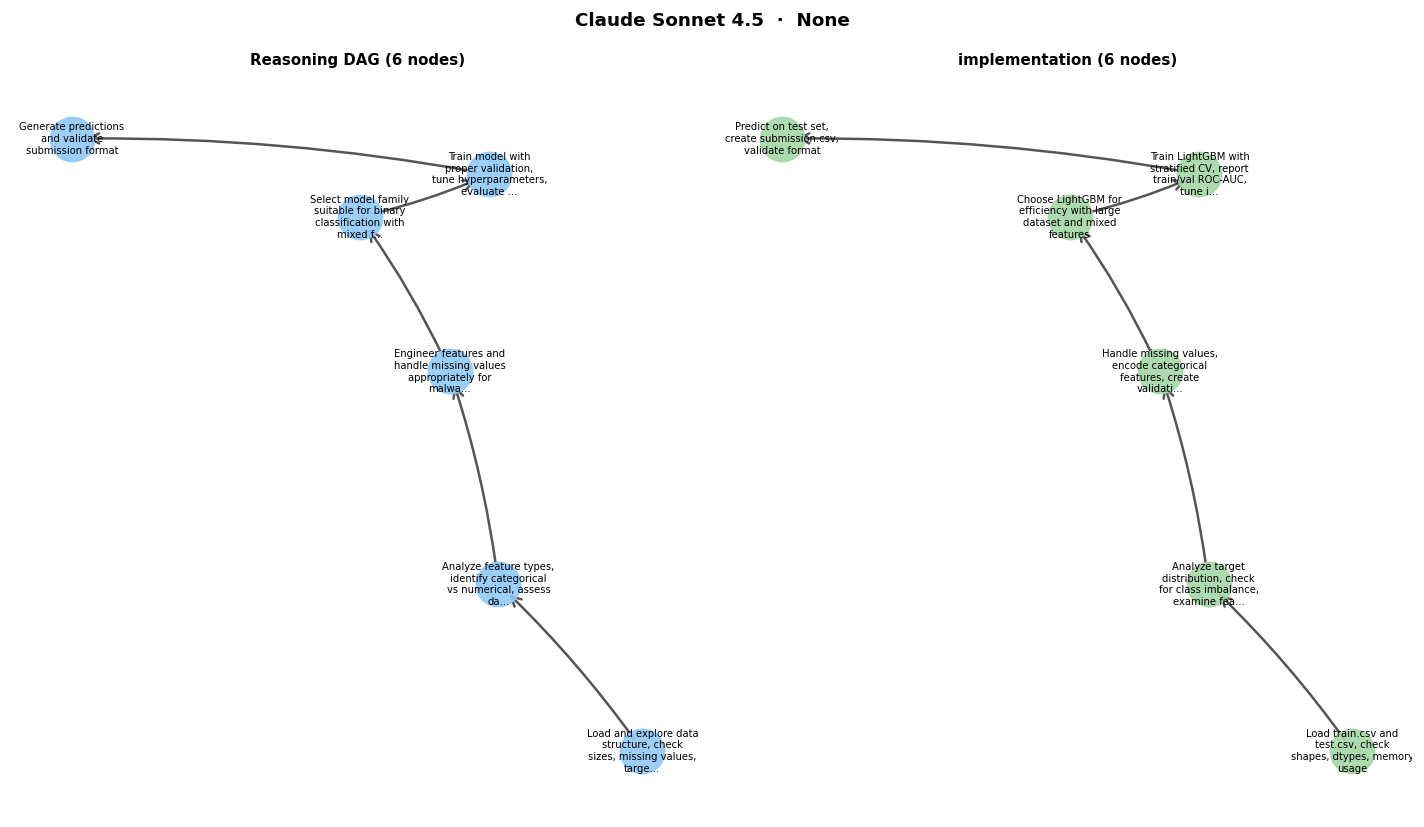

challenge:  gendered-pronoun-resolution


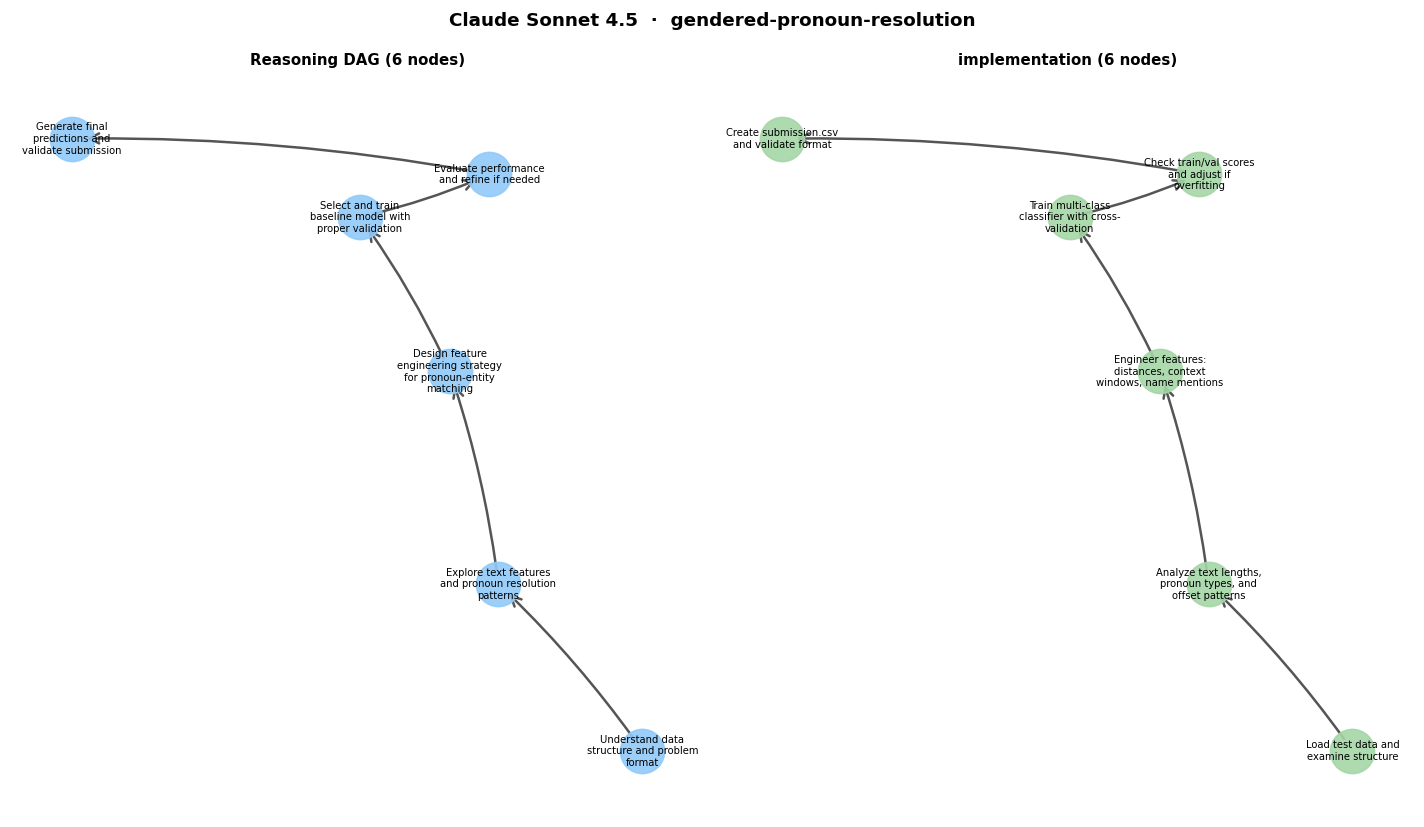

challenge:  liverpool-ion-switching


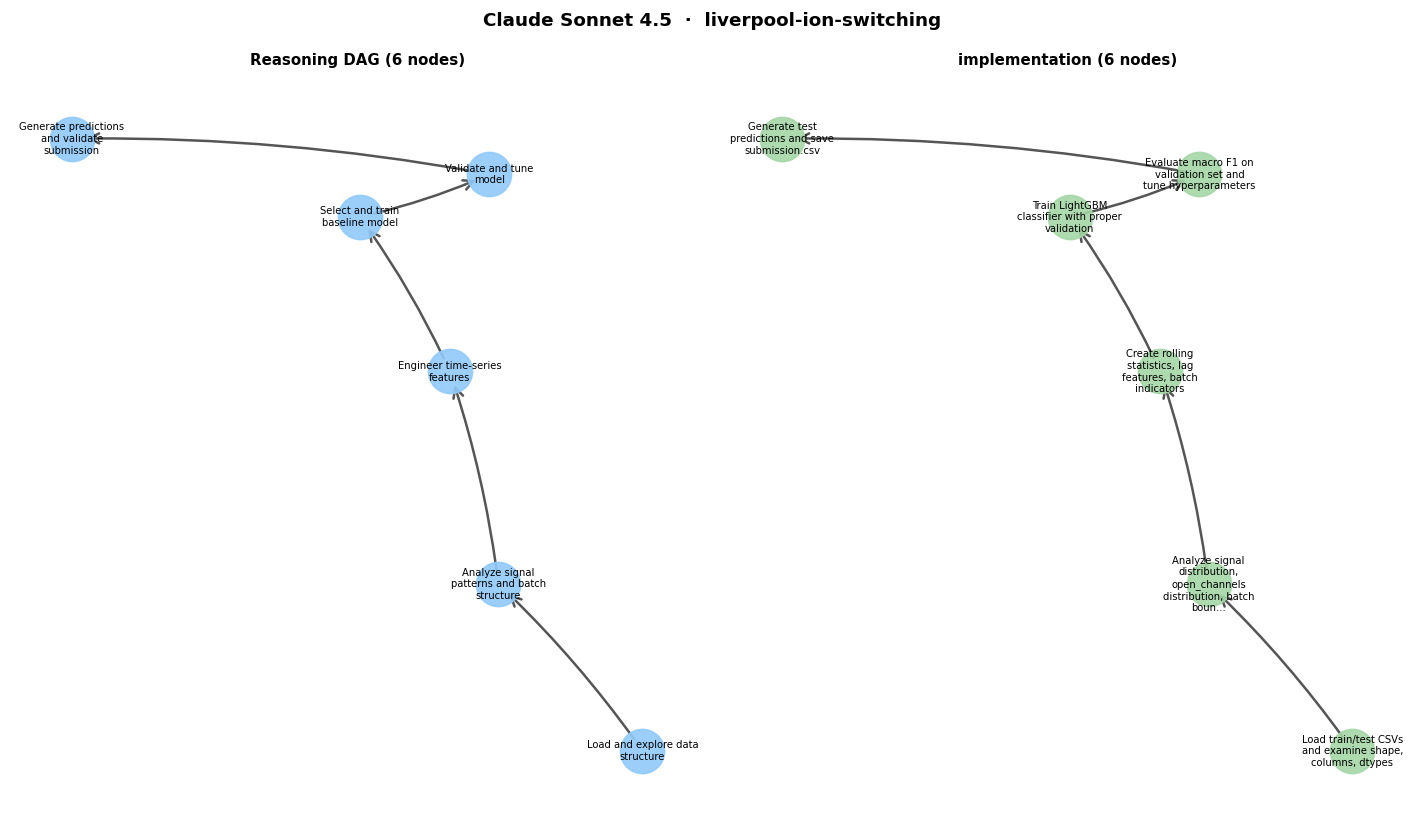

challenge:  imaterialist-challenge-furniture-2018


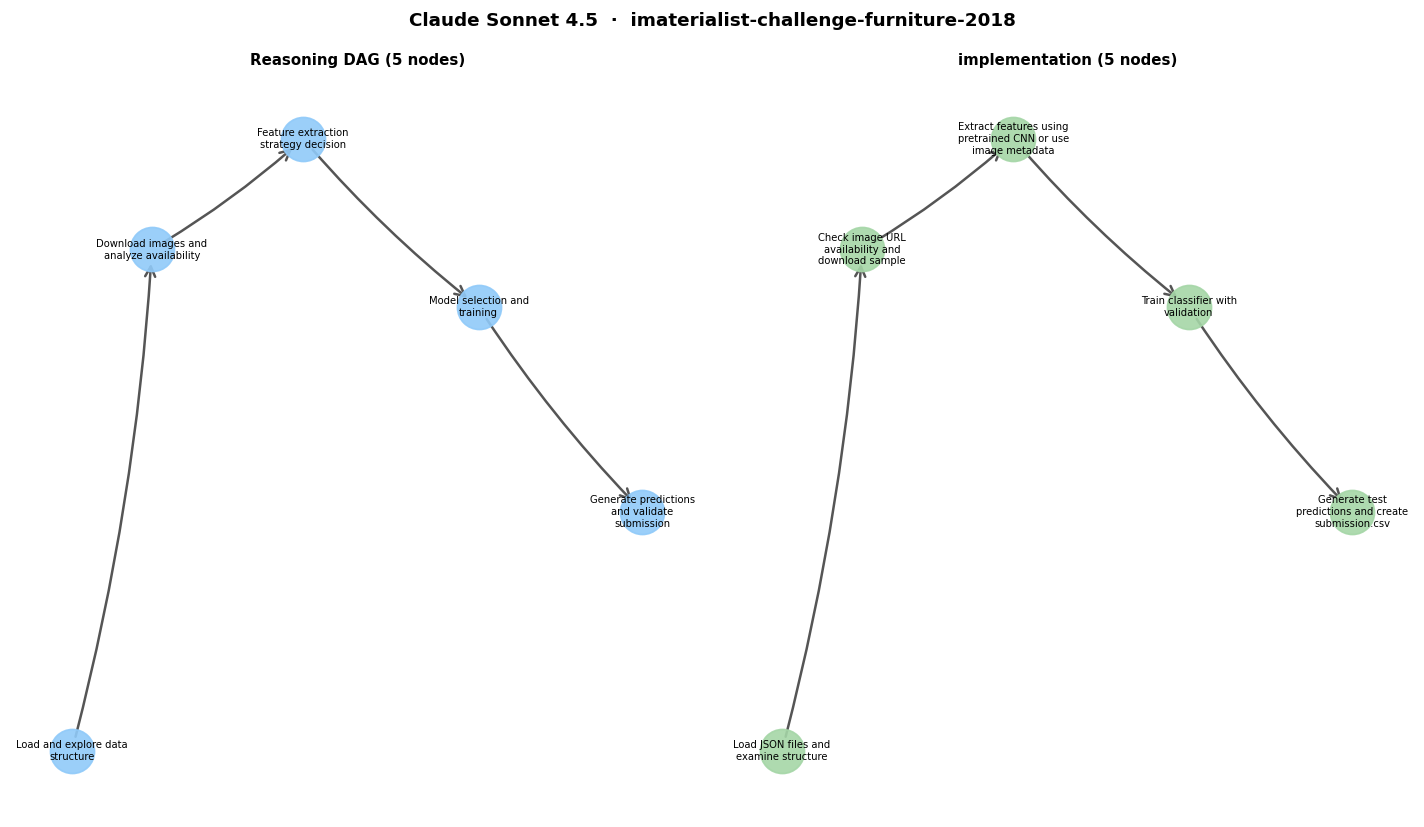

challenge:  imaterialist-challenge-fashion-2018


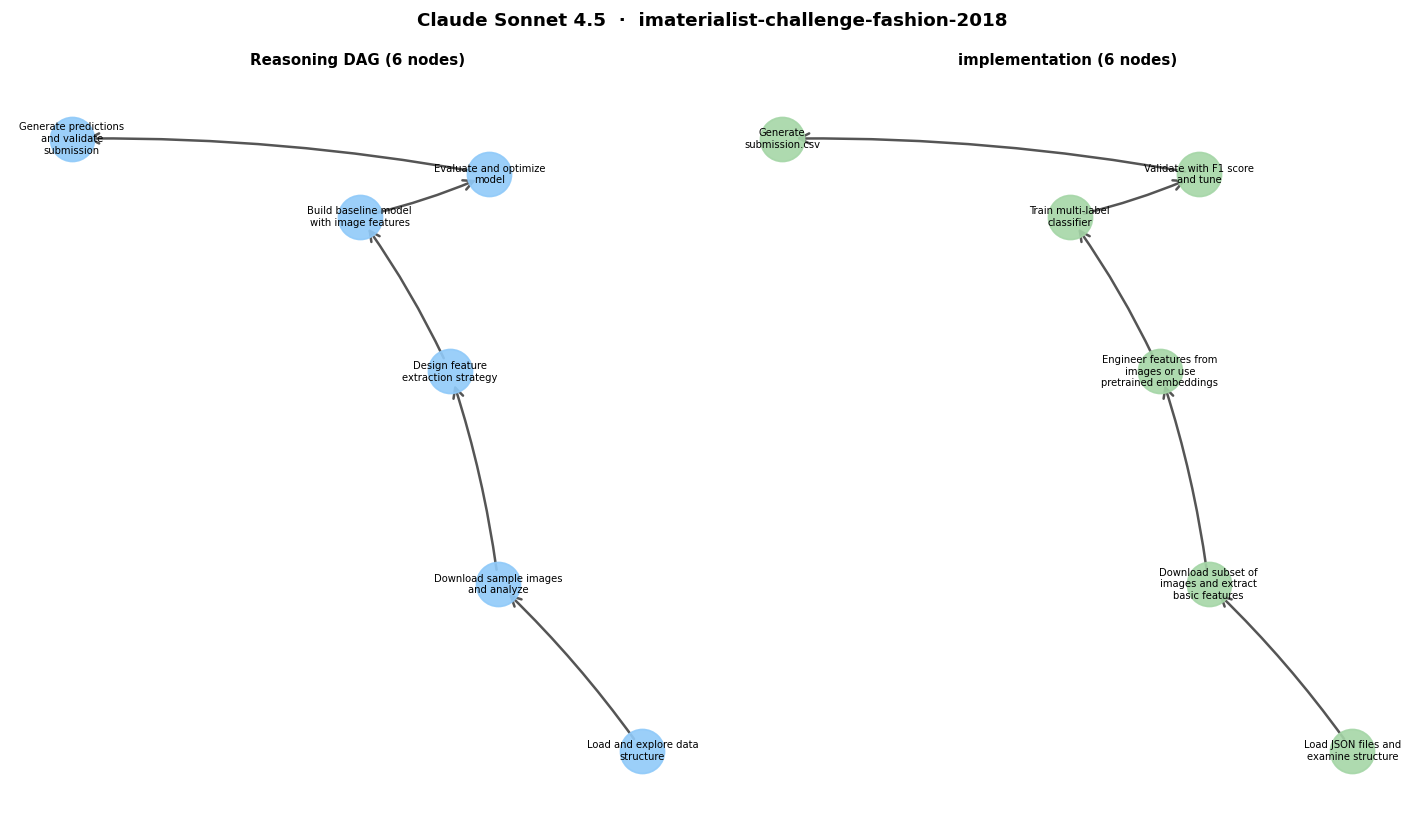

challenge:  talkingdata-adtracking-fraud-detection


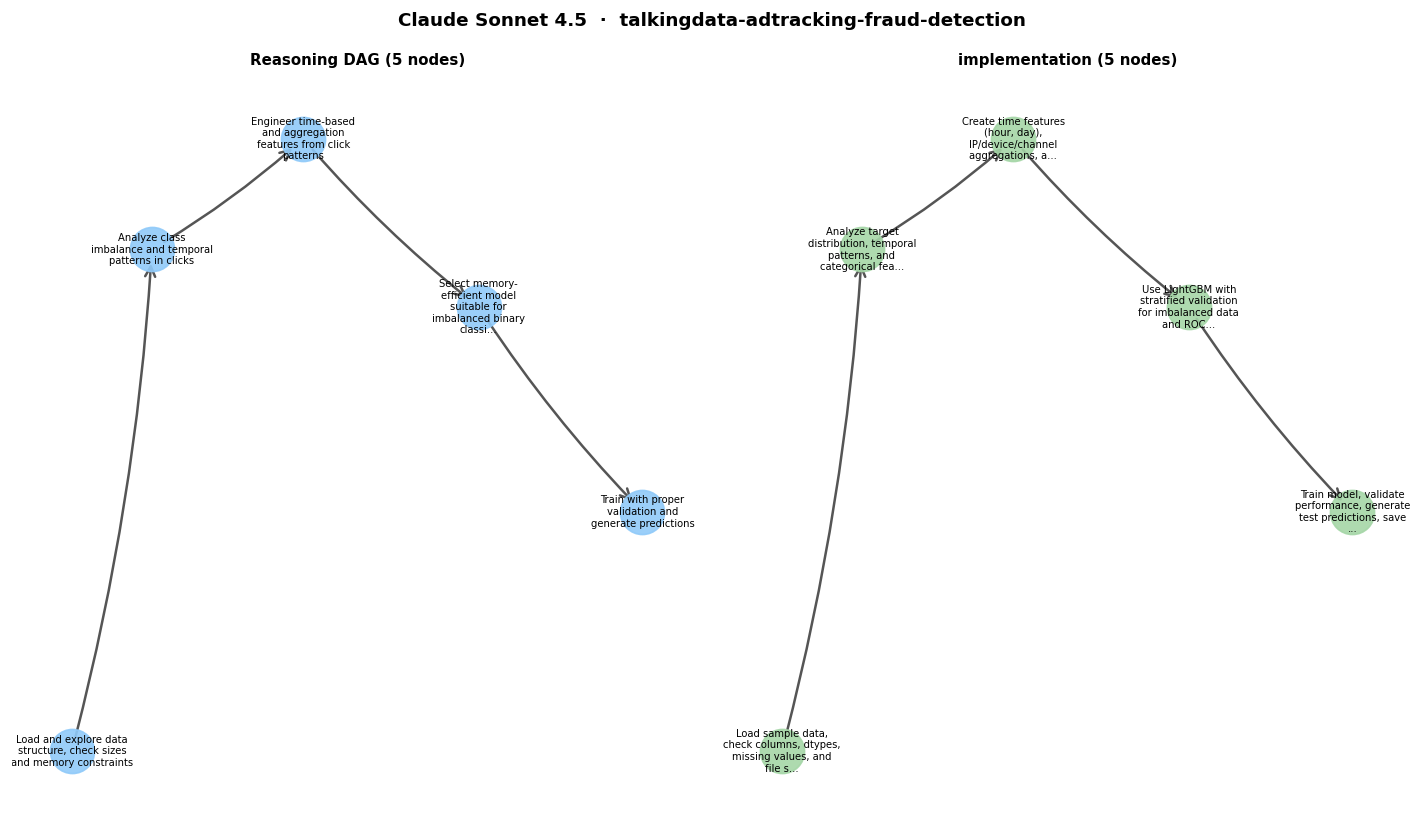

challenge:  rsna-pneumonia-detection-challenge


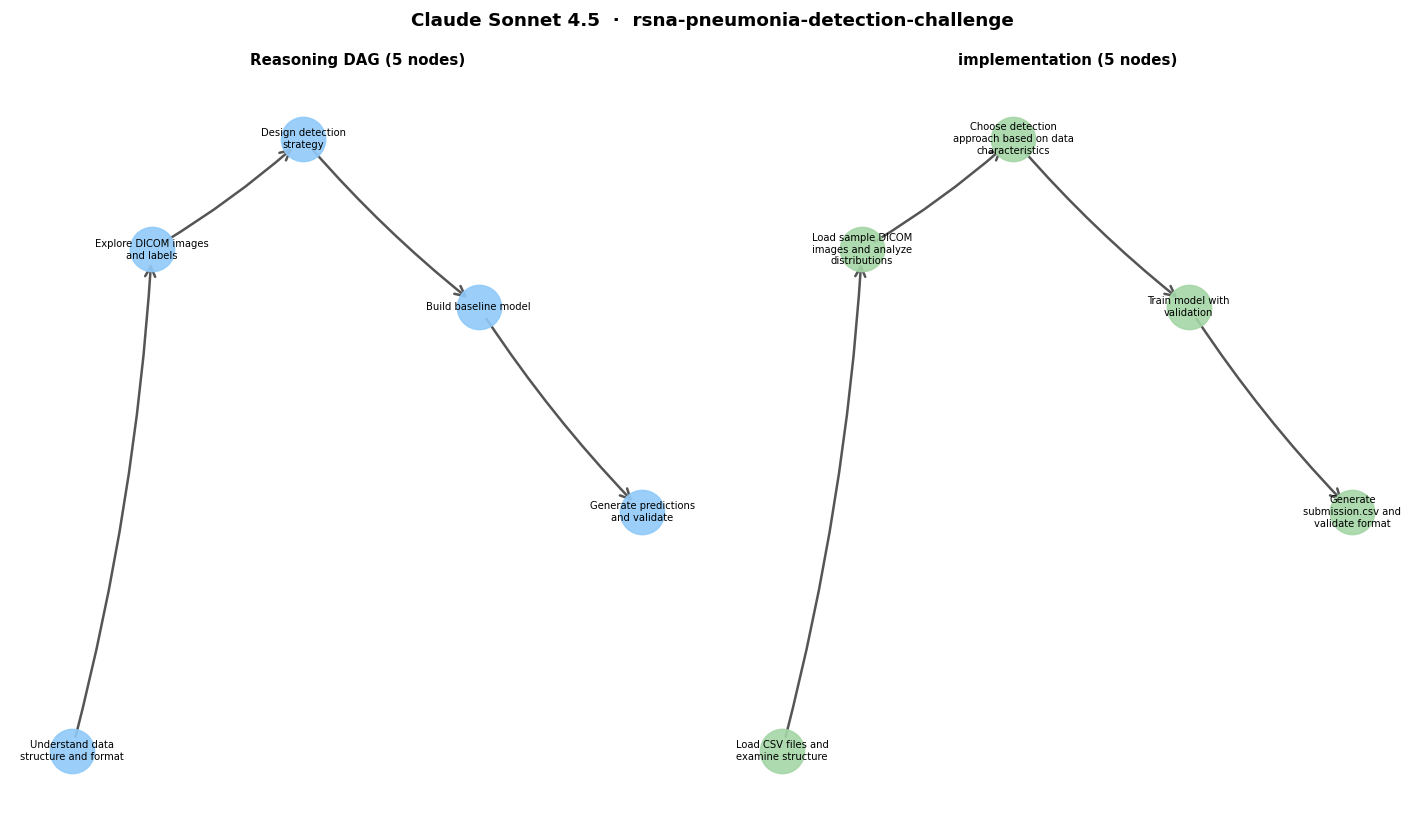

challenge:  digit-recognizer


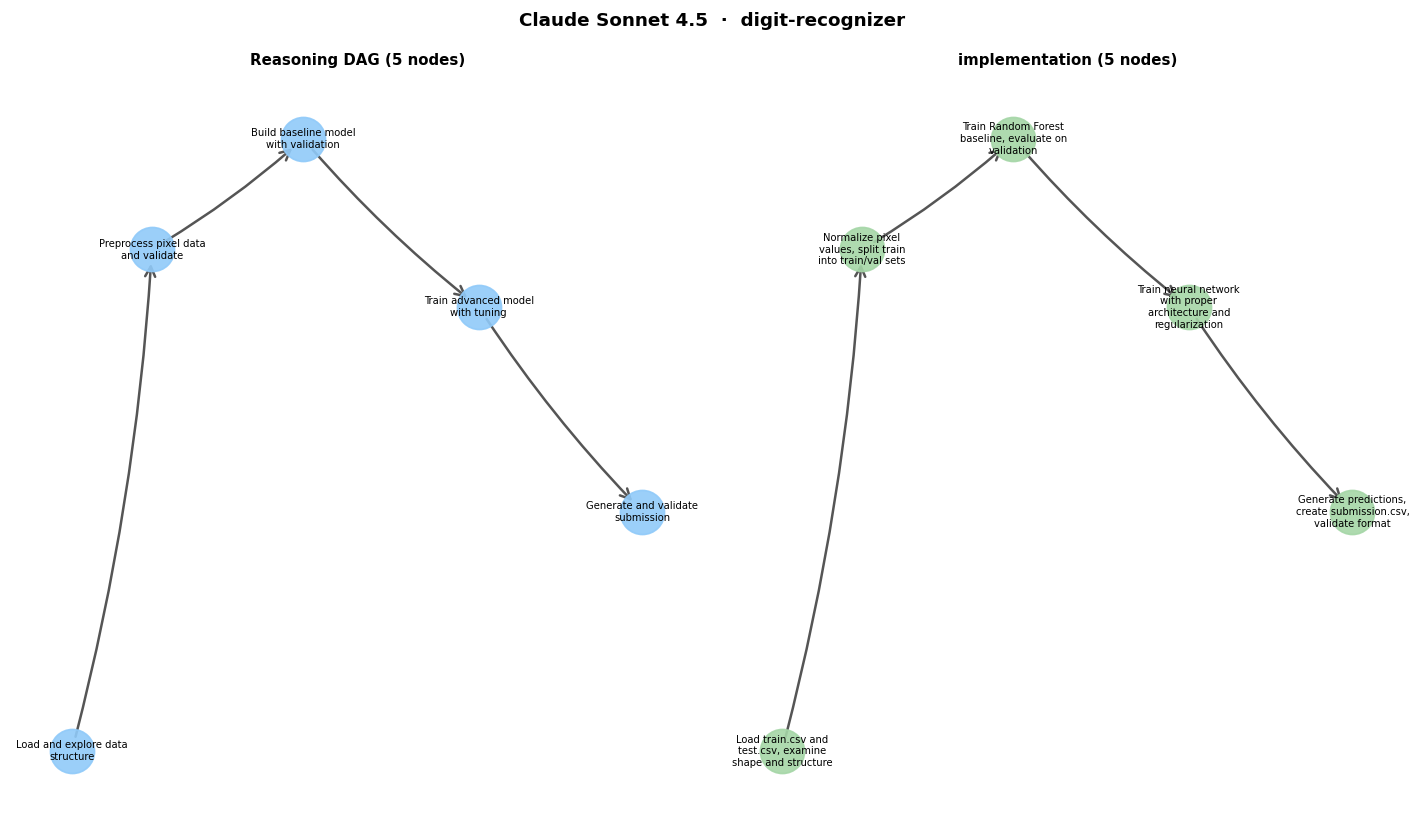

challenge:  siim-acr-pneumothorax-segmentation


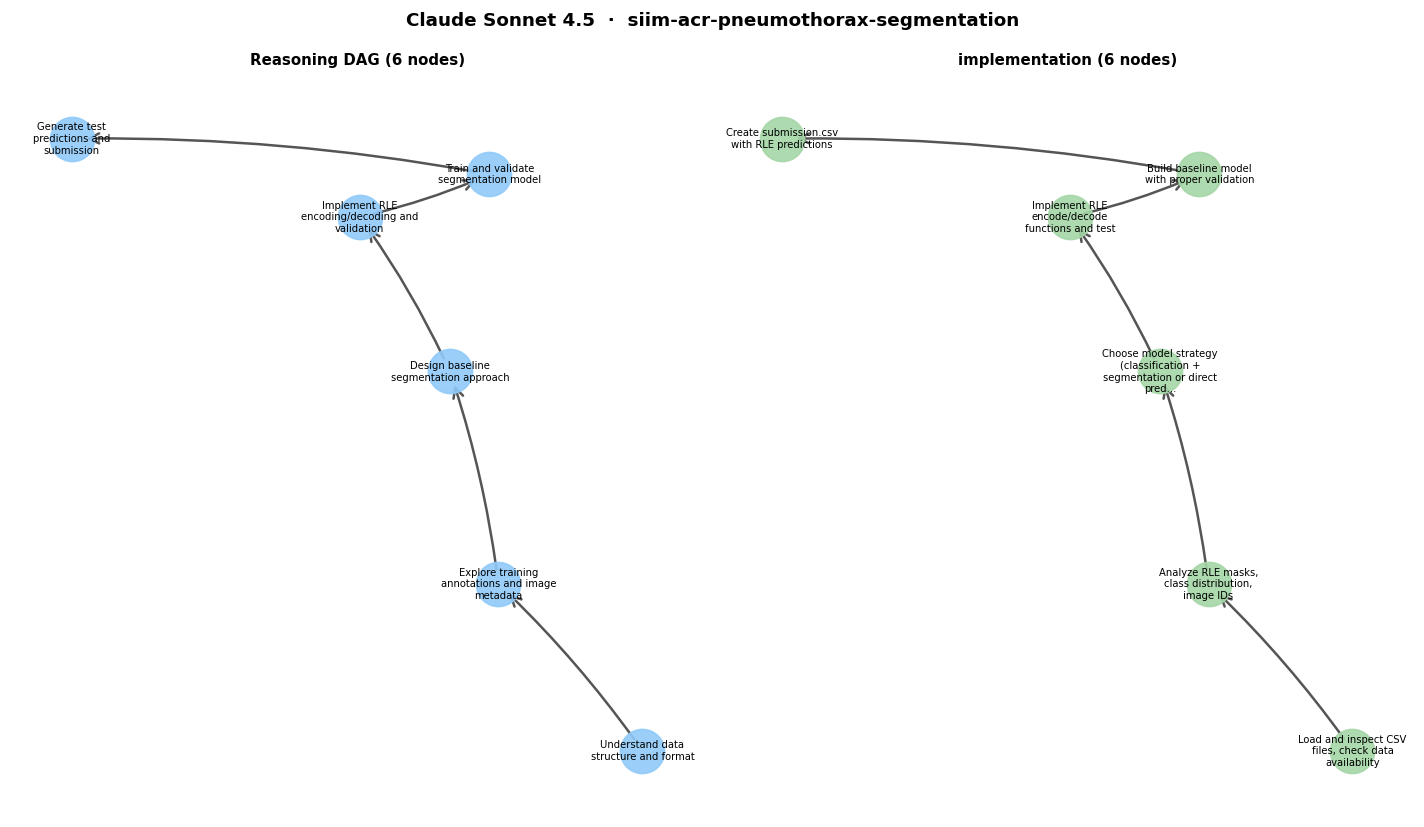

challenge:  career-con-2019


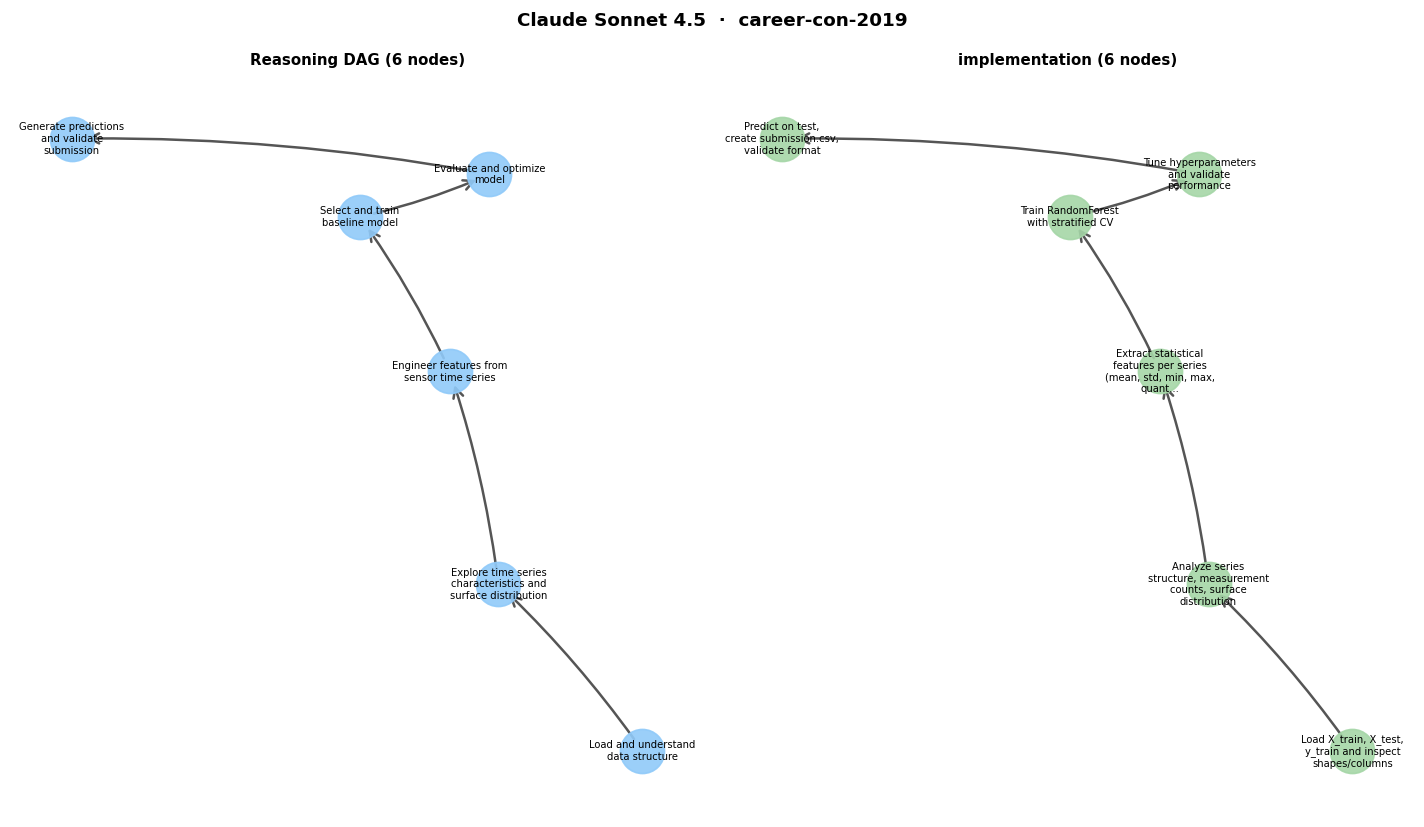

challenge:  store-sales-time-series-forecasting


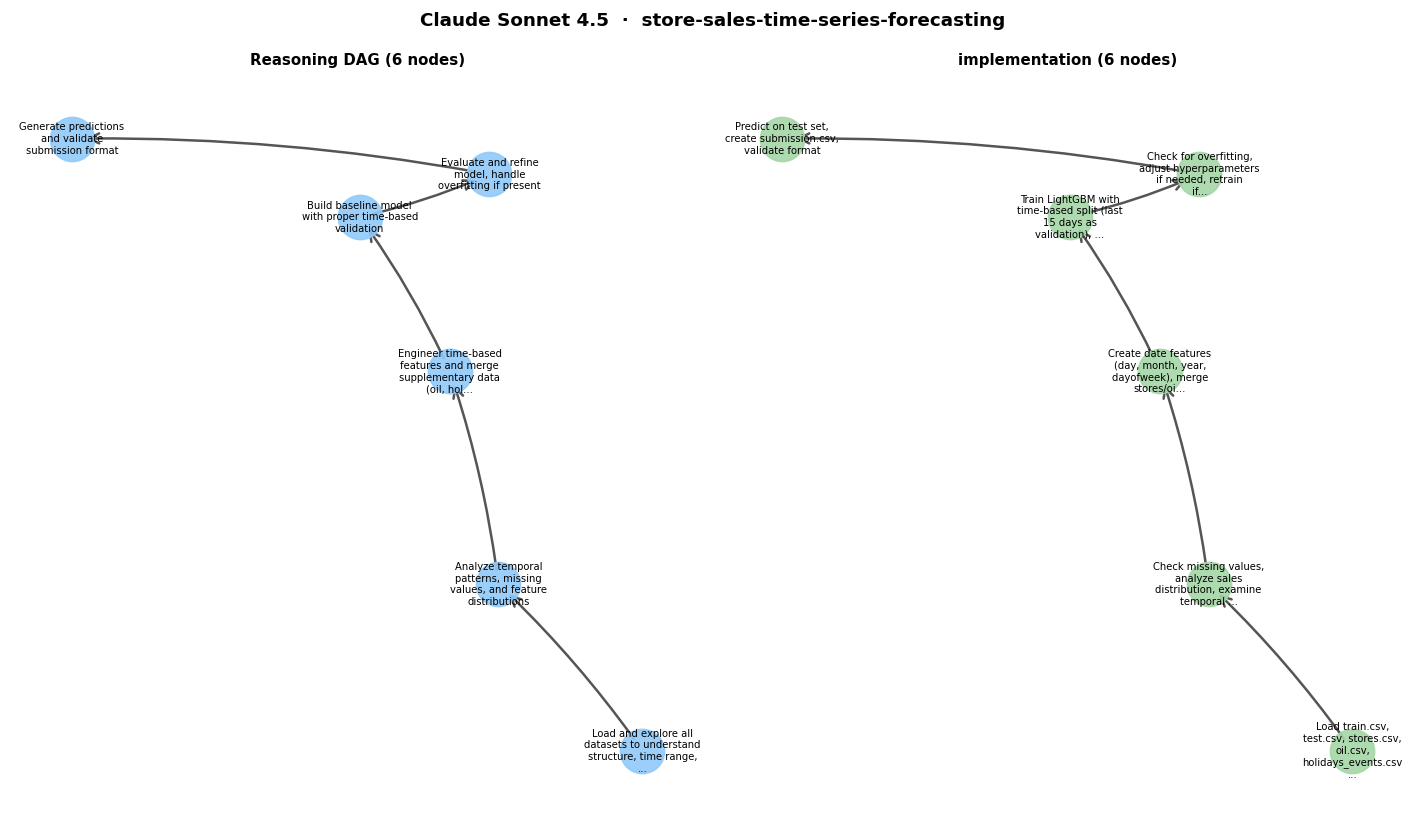

challenge:  ieee-fraud-detection


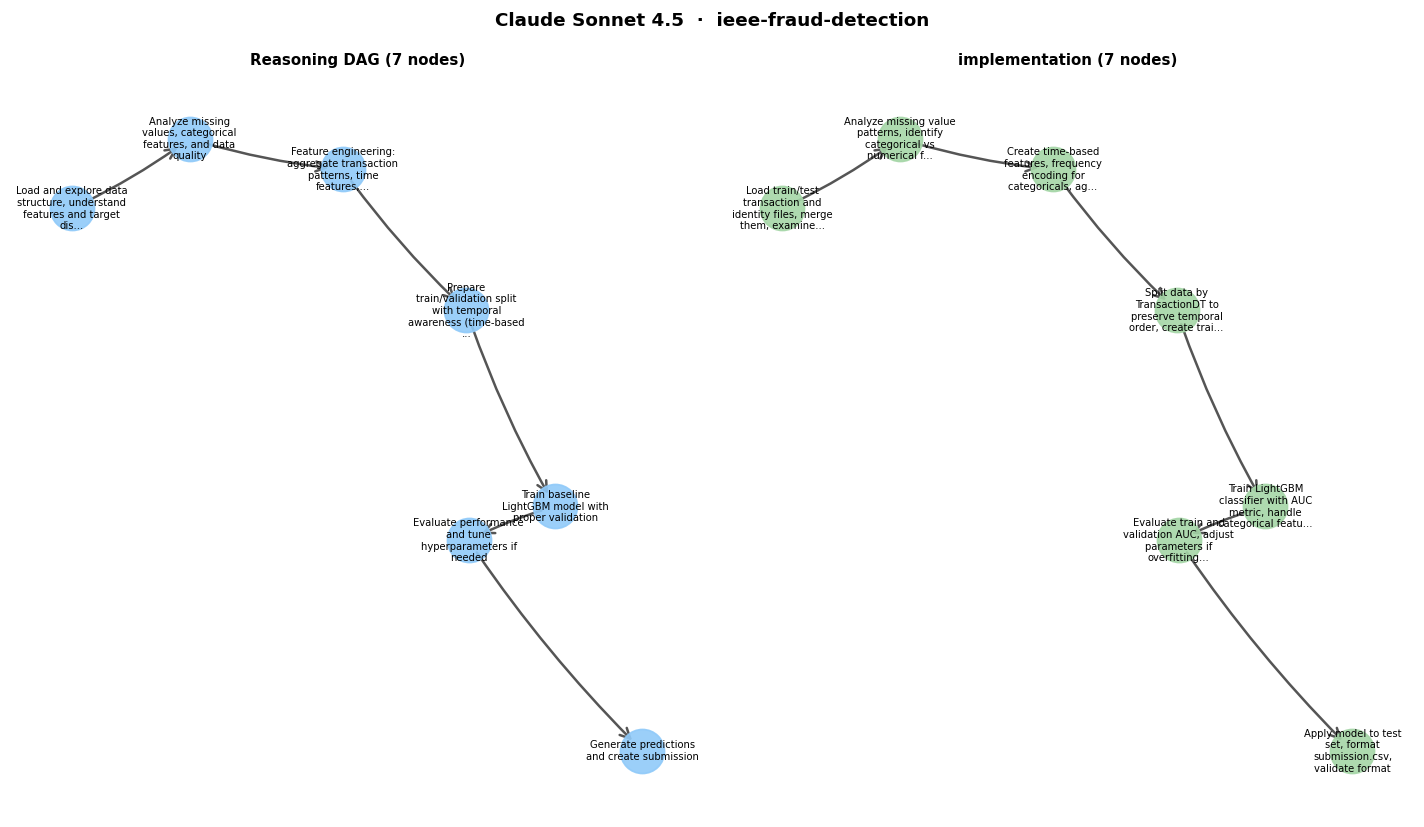

challenge:  web-traffic-time-series-forecasting


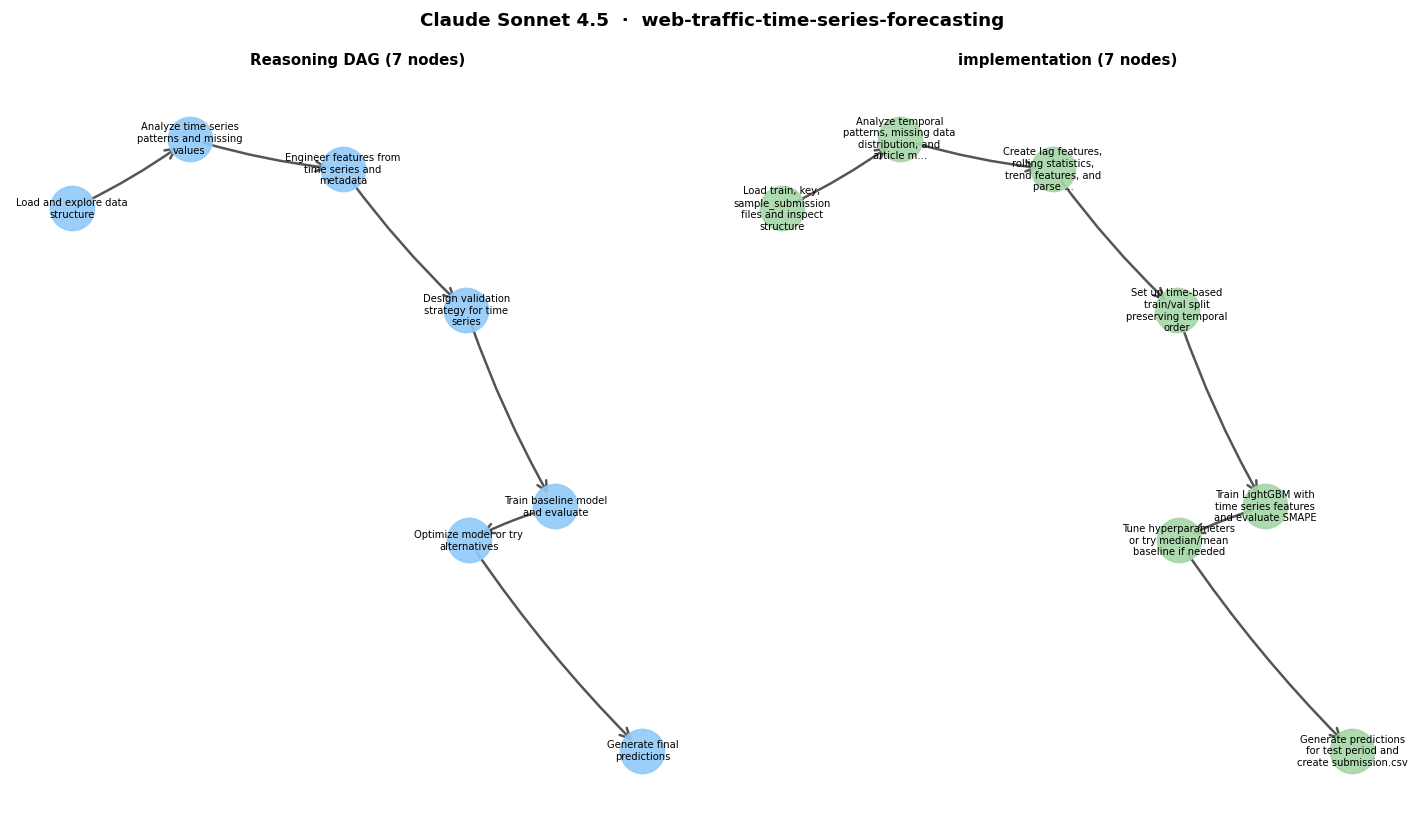

challenge:  predict-ai-model-runtime


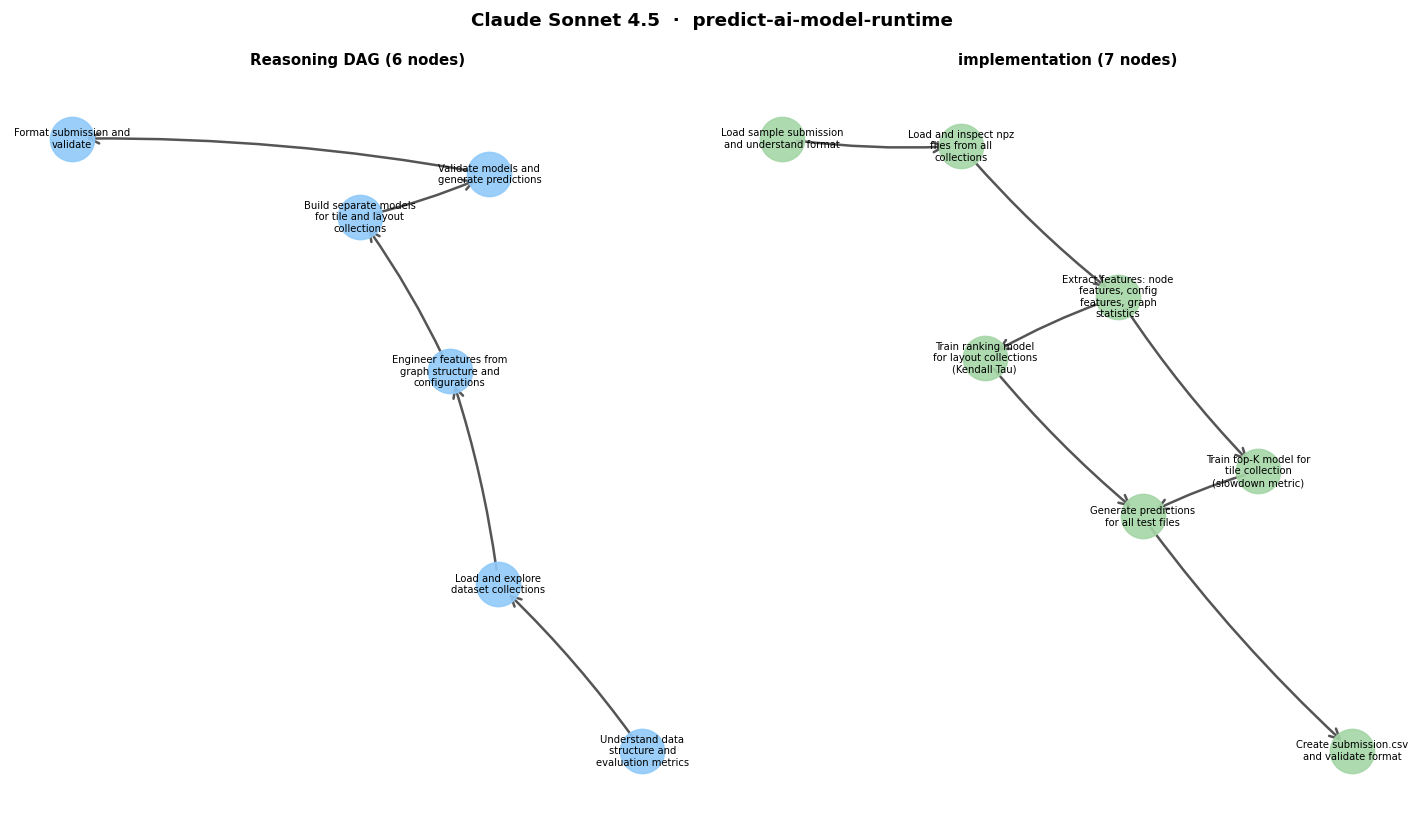

challenge:  humpback-whale-identification


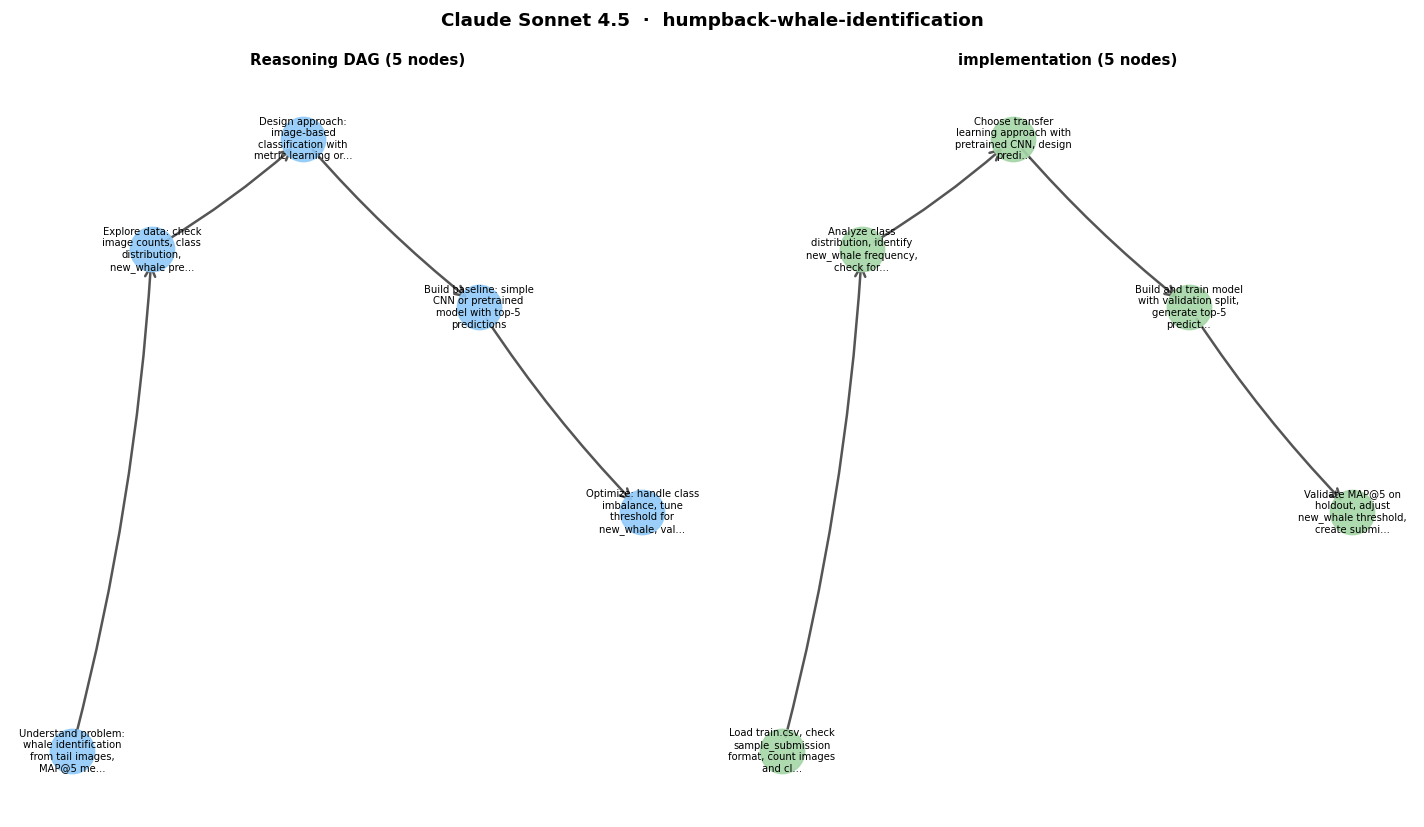

challenge:  nlp-getting-started


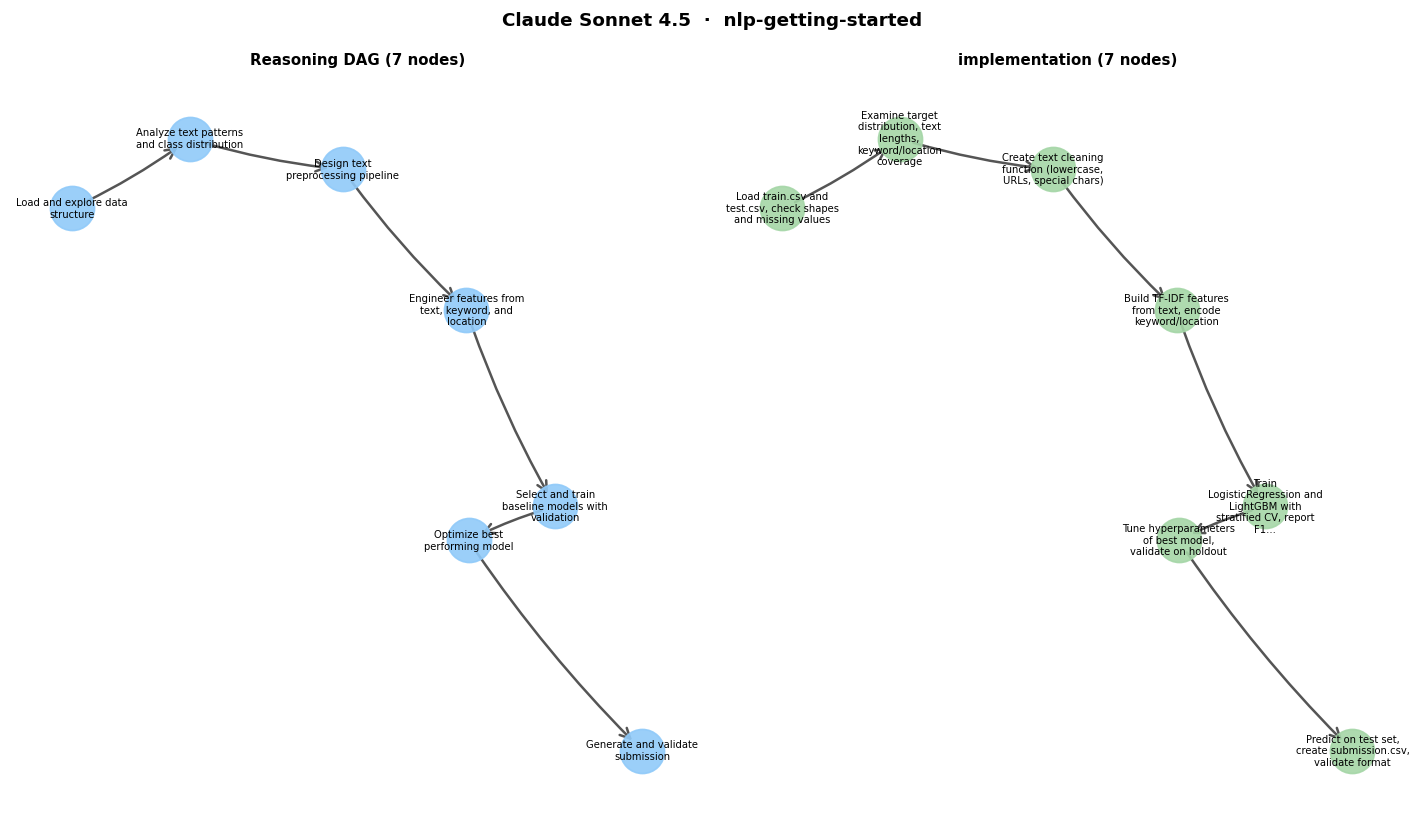

challenge:  youtube8m-2018


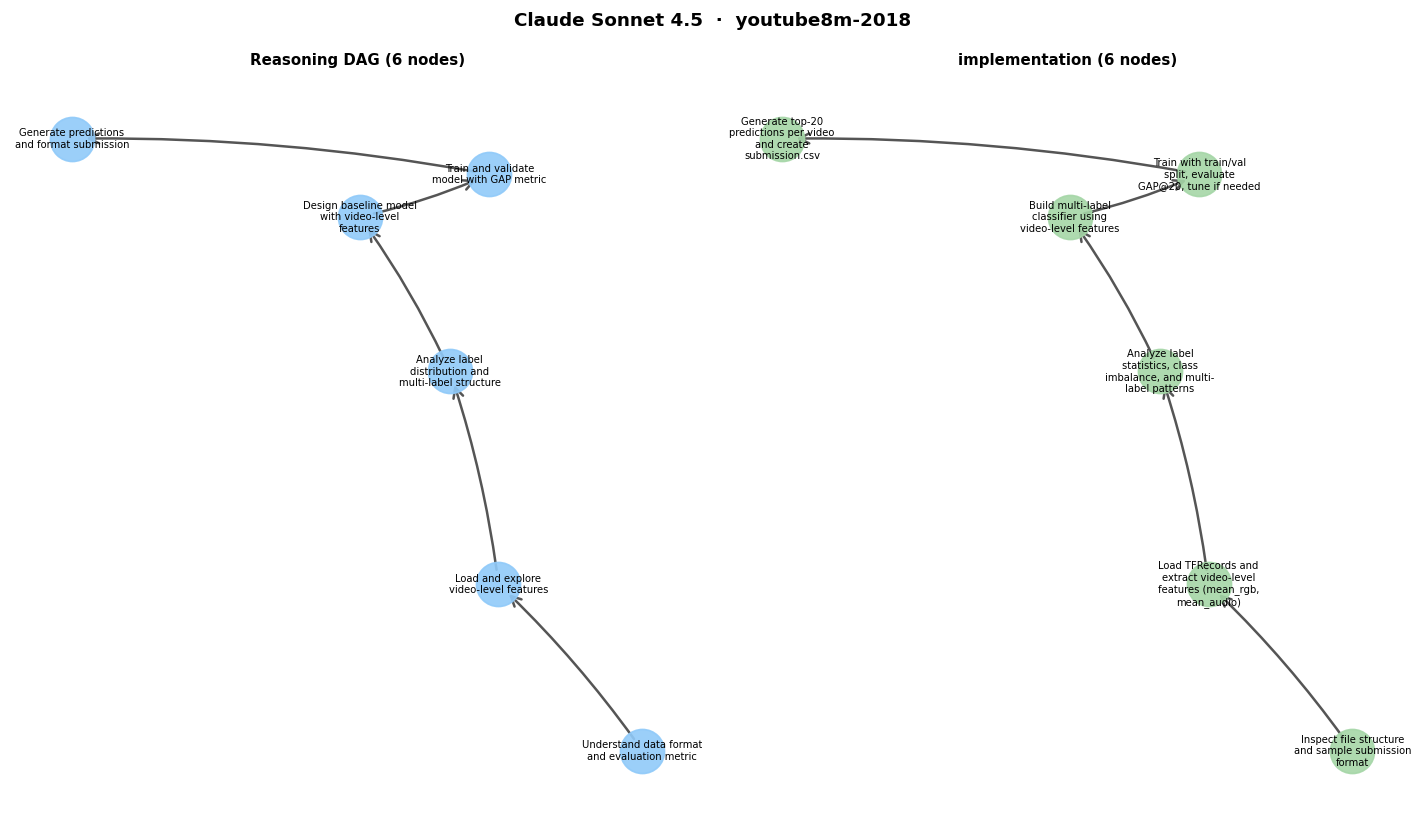

challenge:  santander-customer-transaction-prediction


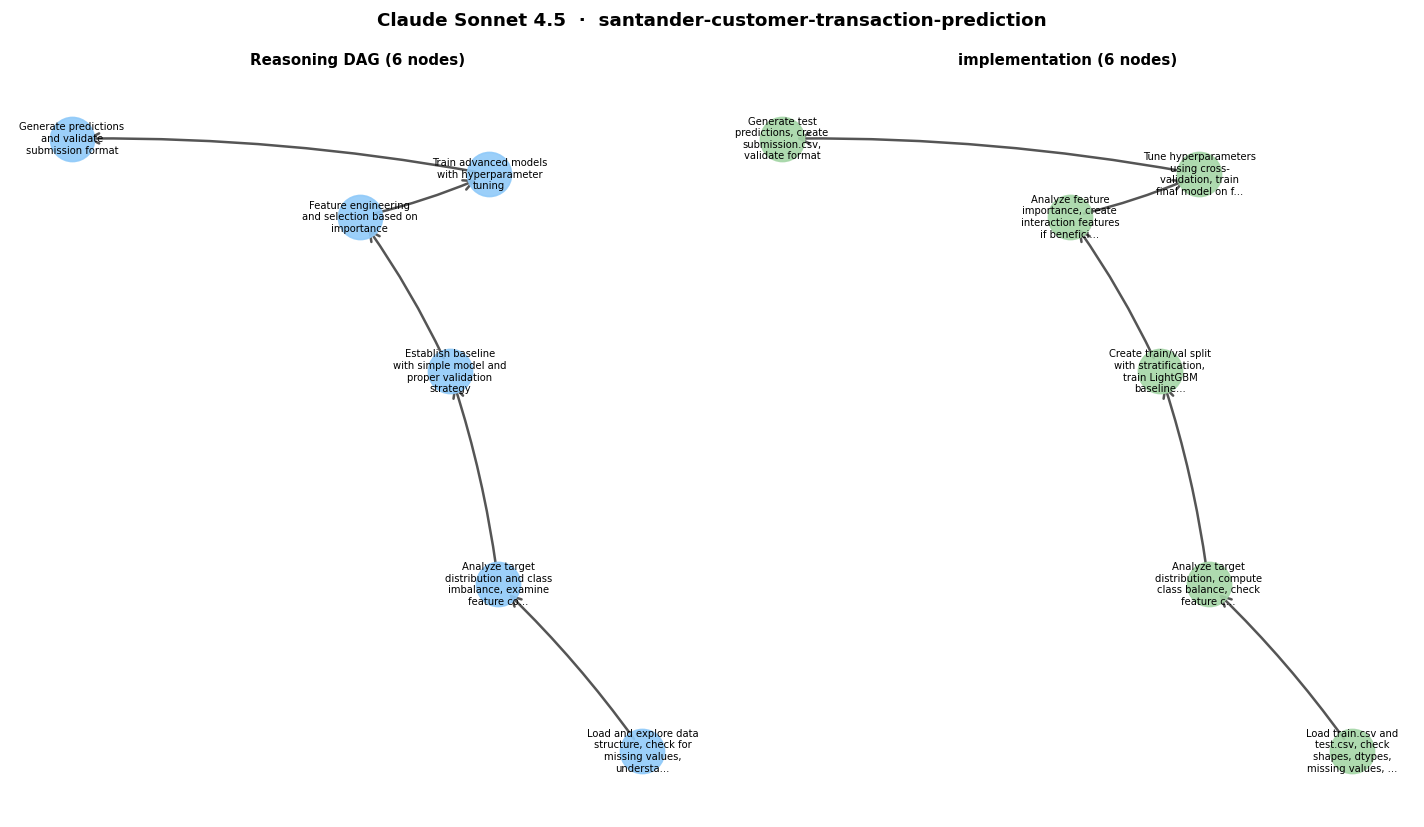

challenge:  m5-forecasting-accuracy


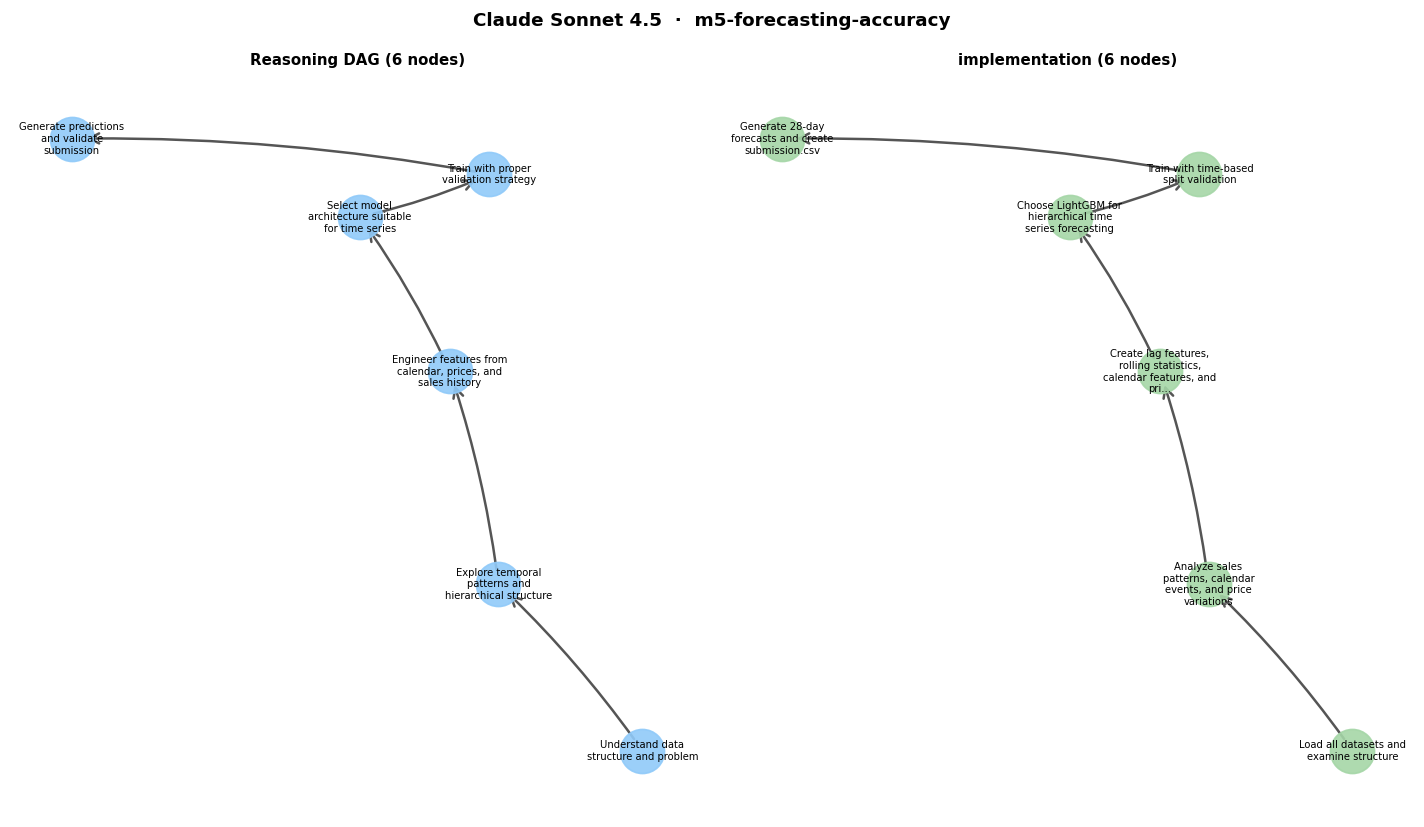

challenge:  trec-covid-information-retrieval


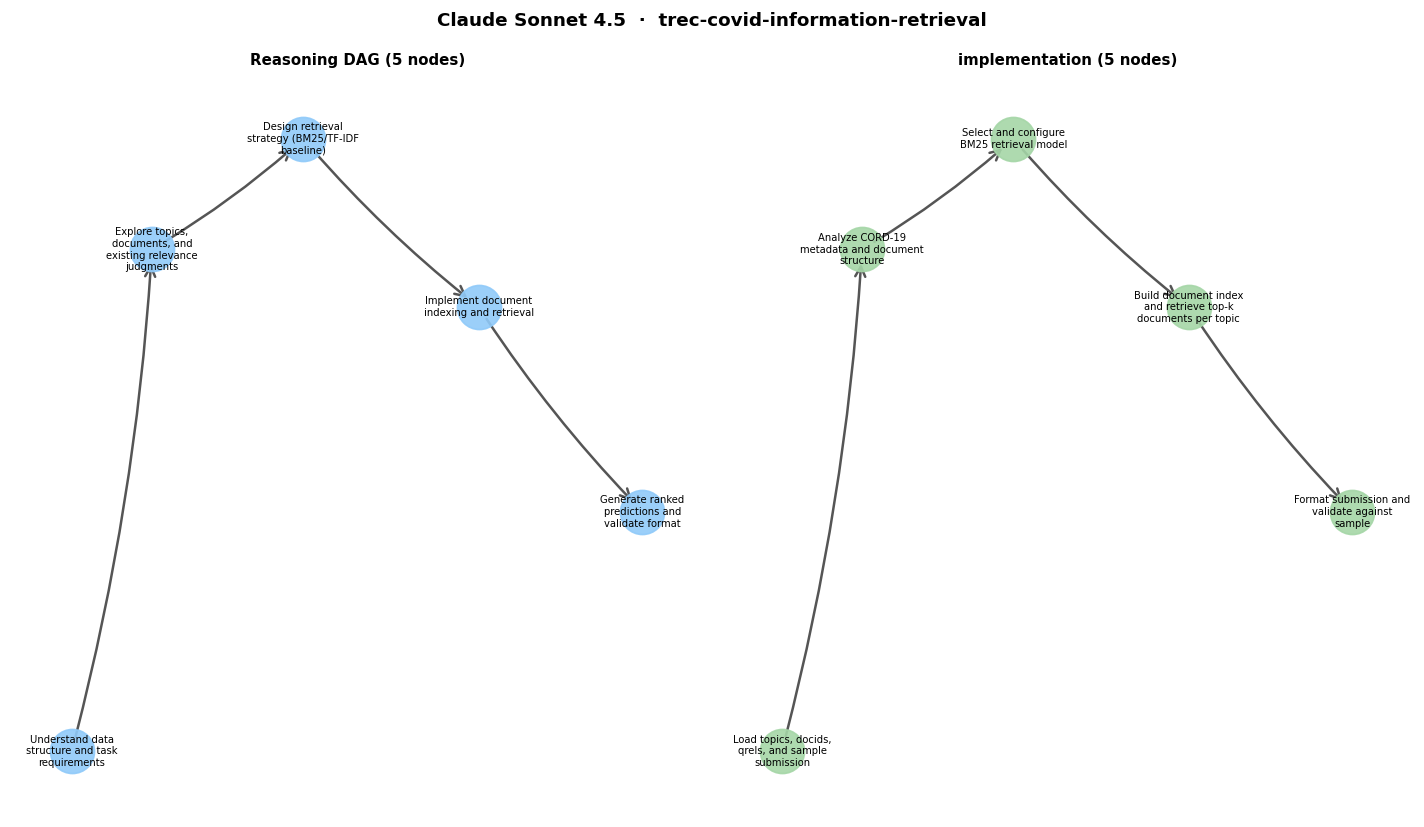

challenge:  LANL-Earthquake-Prediction


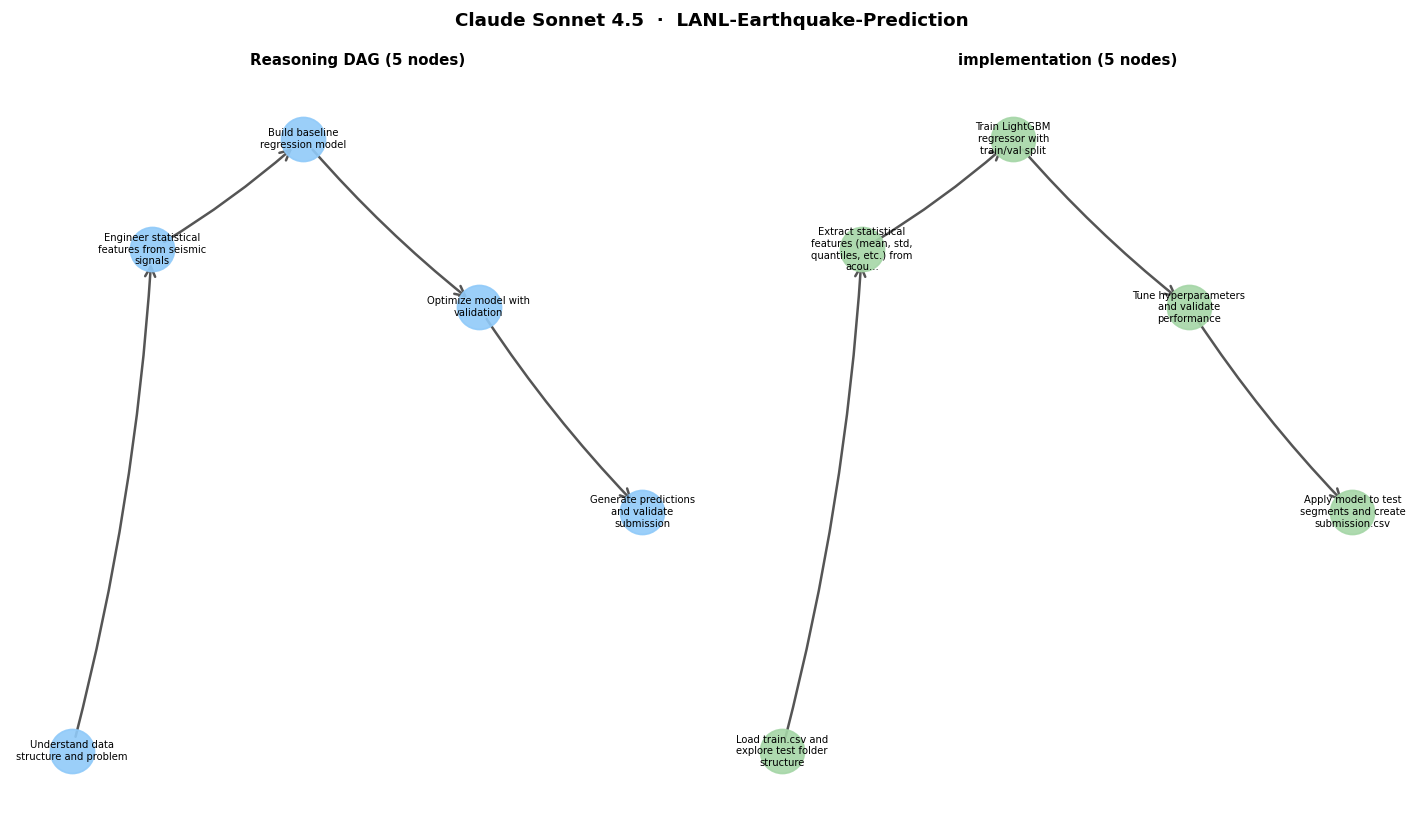

challenge:  mens-march-mania-2022


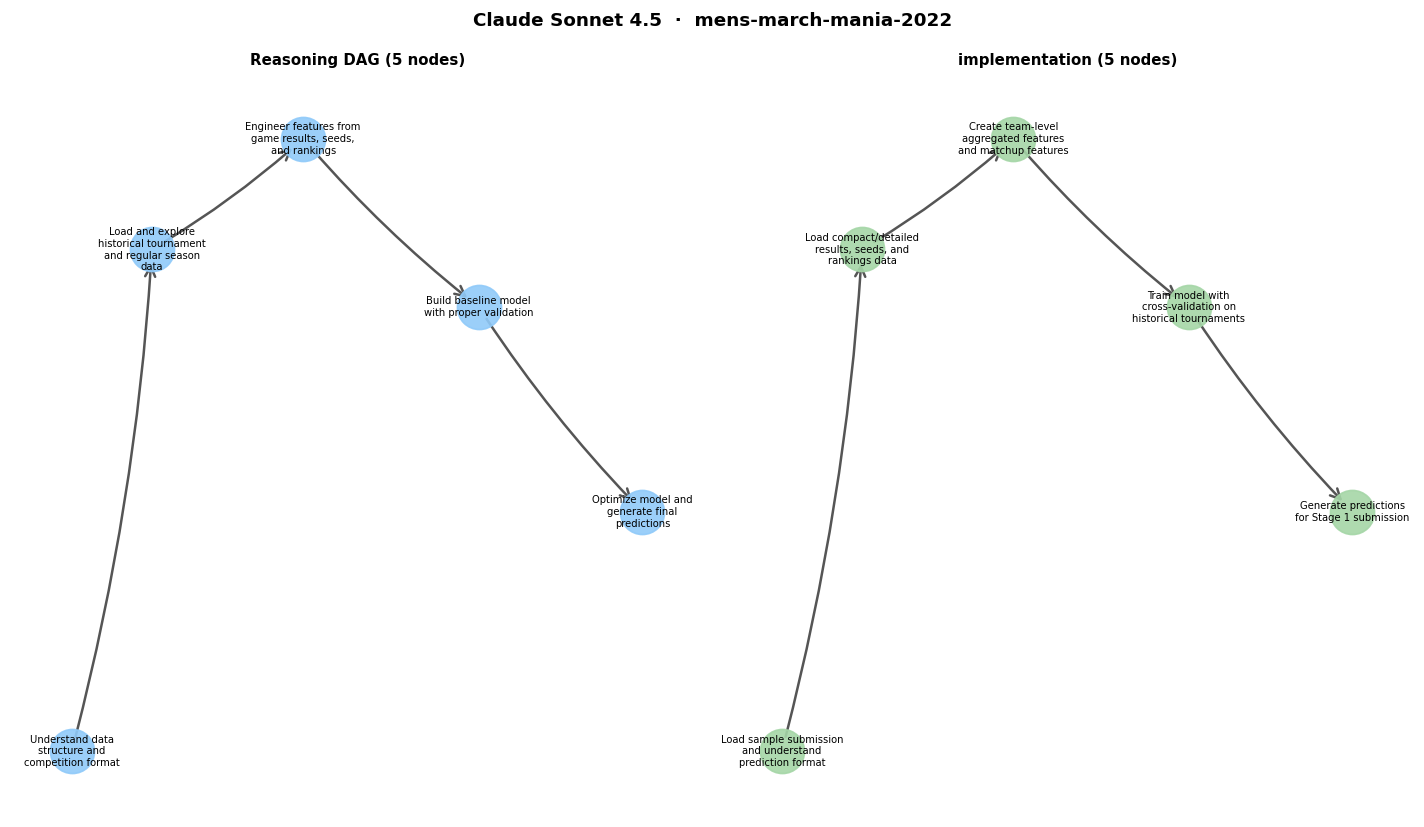

challenge:  statoil-iceberg-classifier-challenge


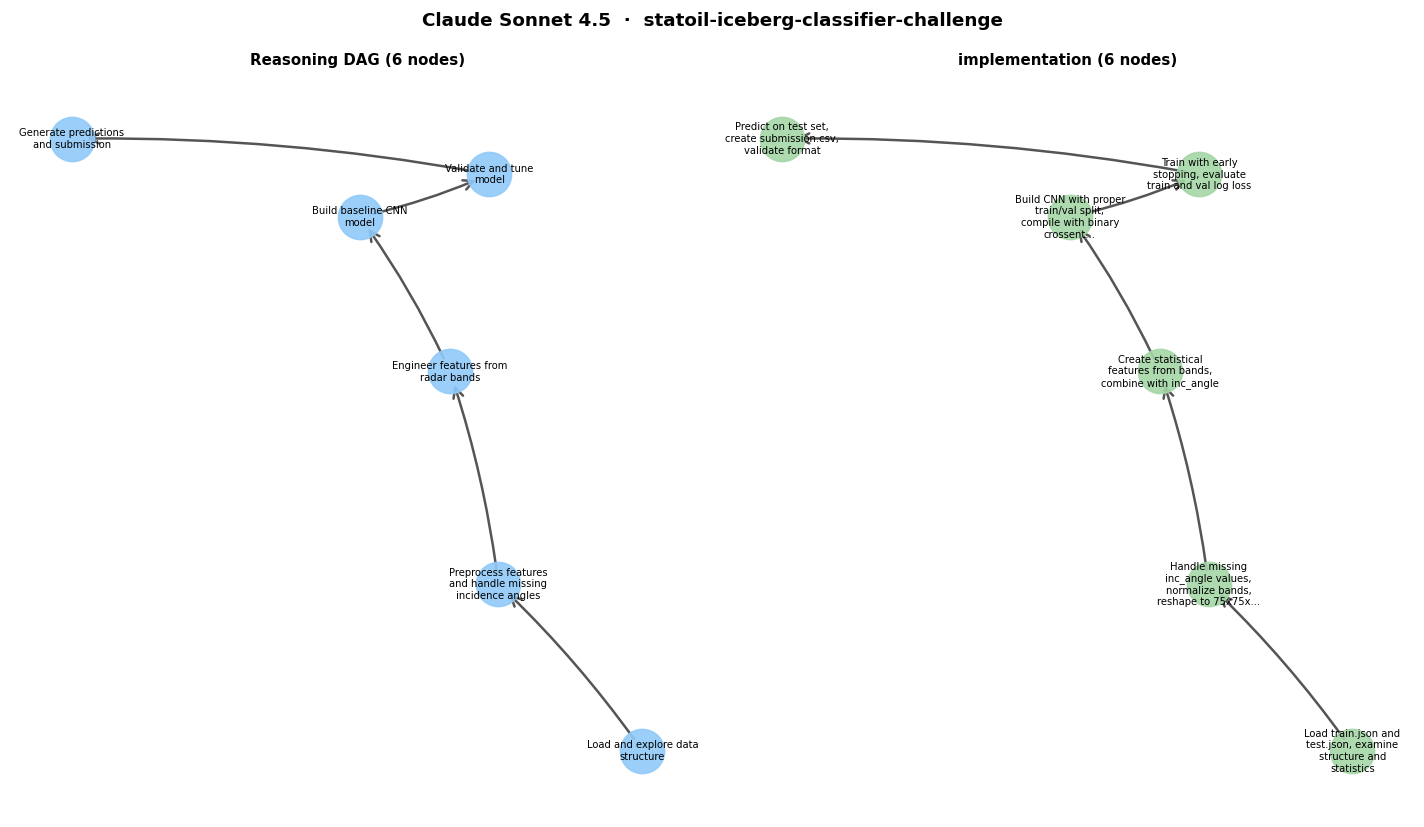

challenge:  mens-machine-learning-competition-2018


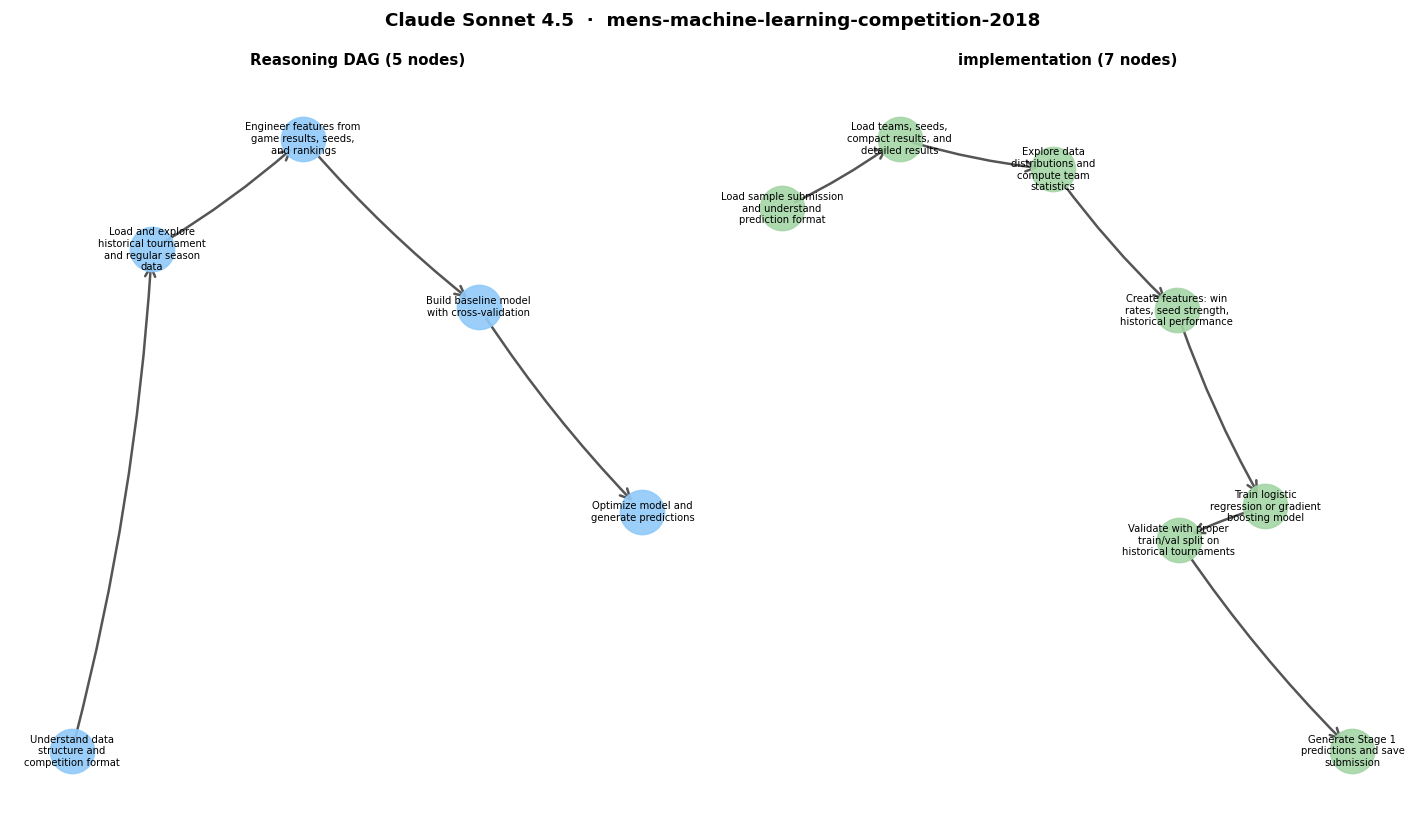

challenge:  santander-value-prediction-challenge


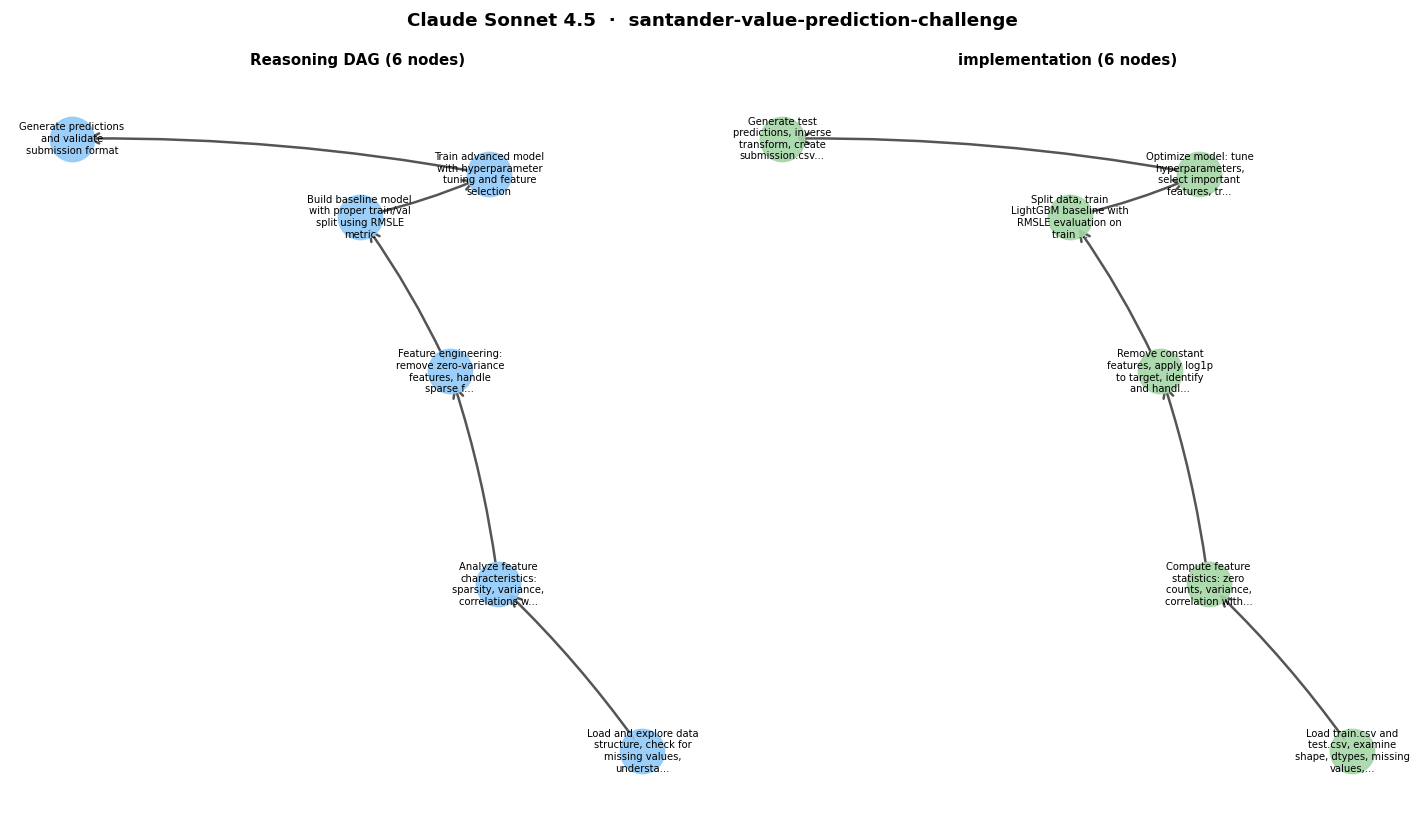

challenge:  home-credit-default-risk


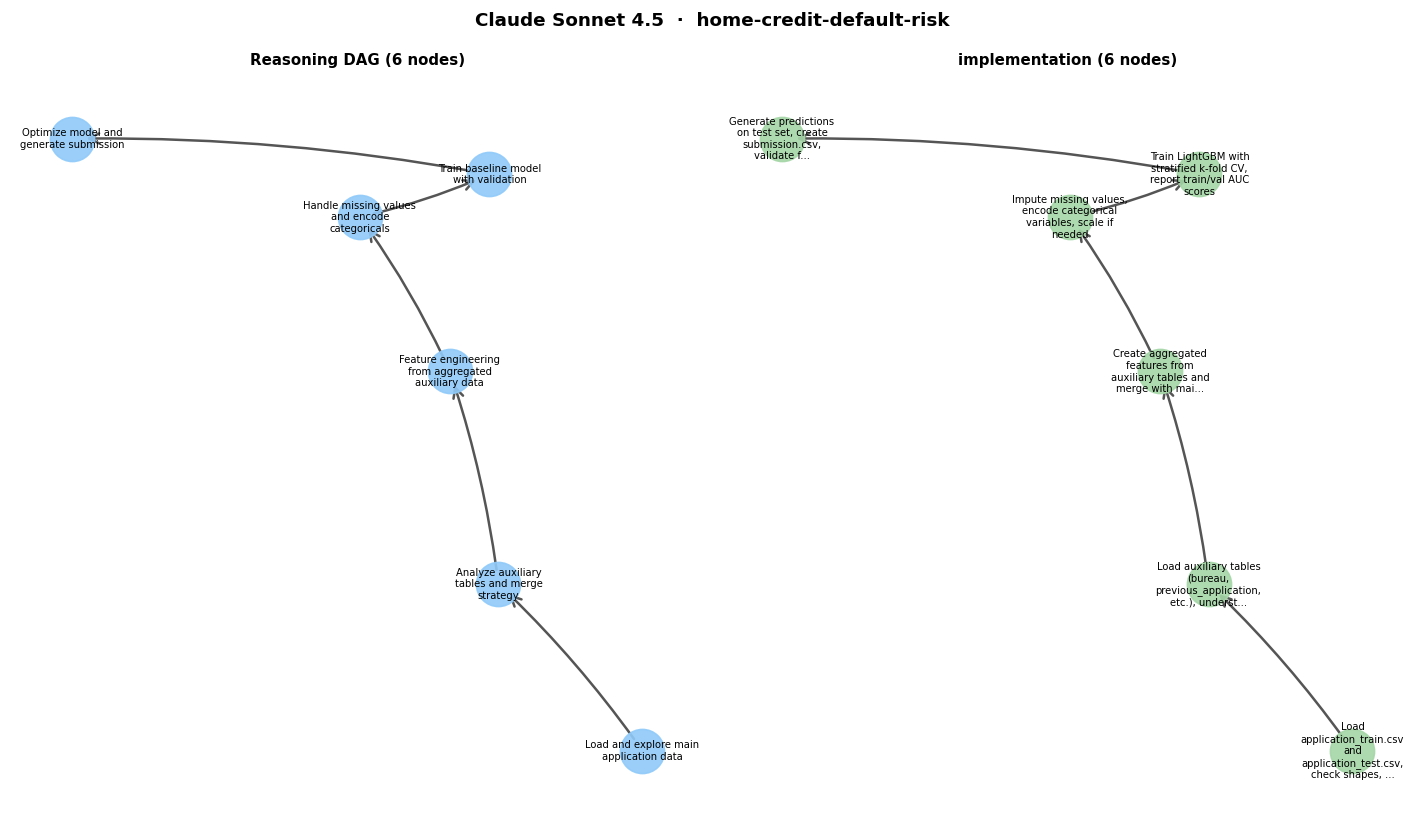

challenge:  youtube8m-2019


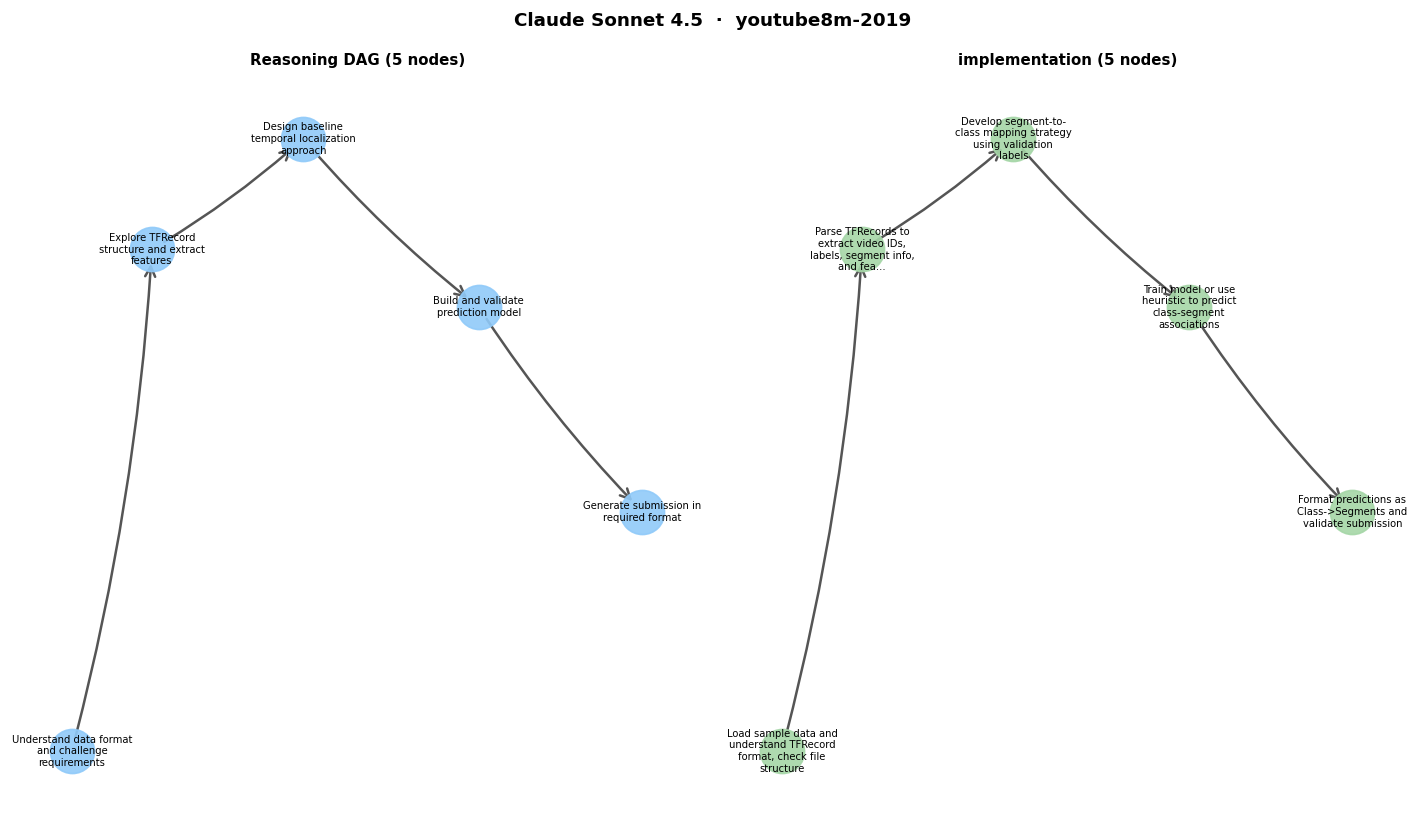

challenge:  stanford-covid-vaccine


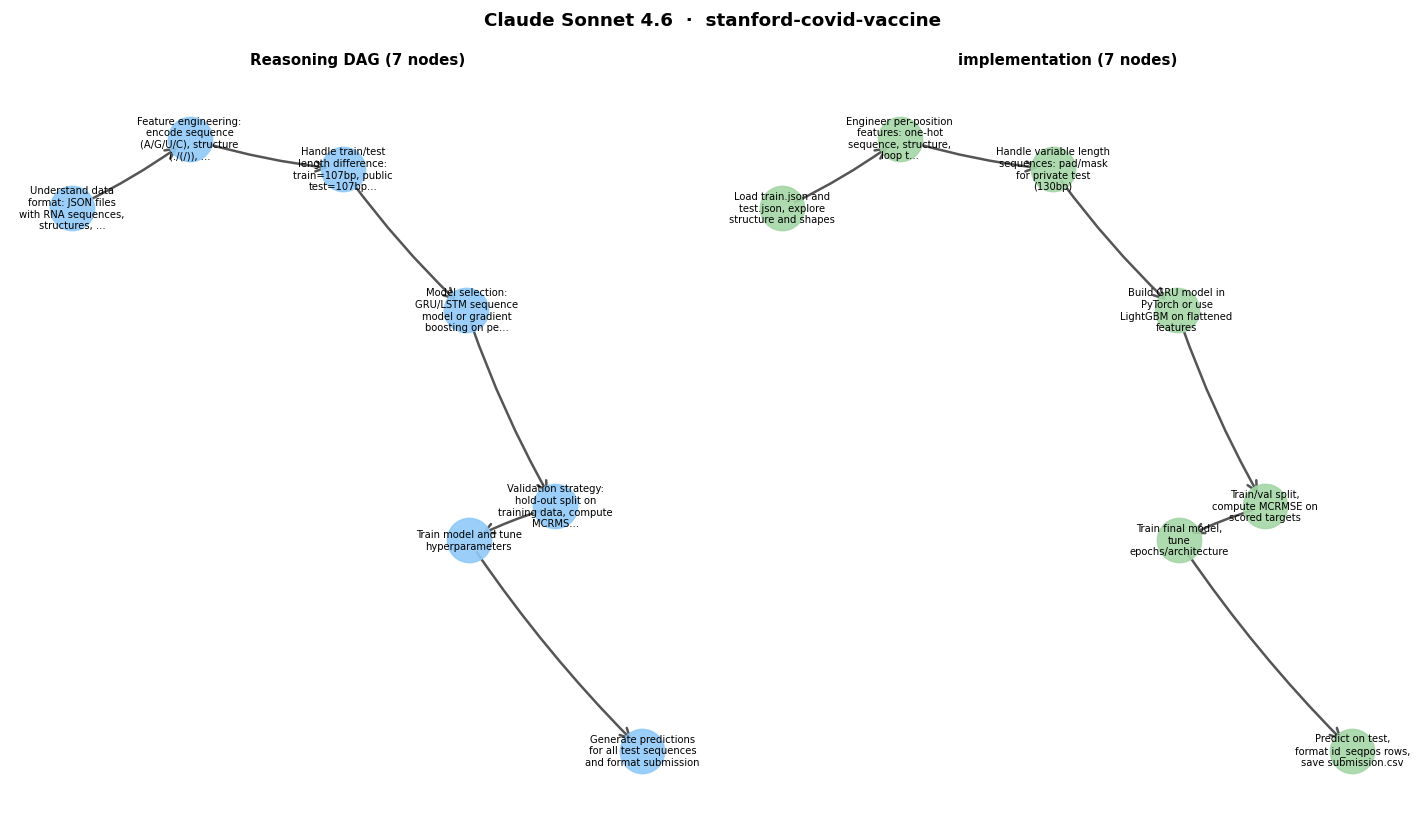

challenge:  gendered-pronoun-resolution


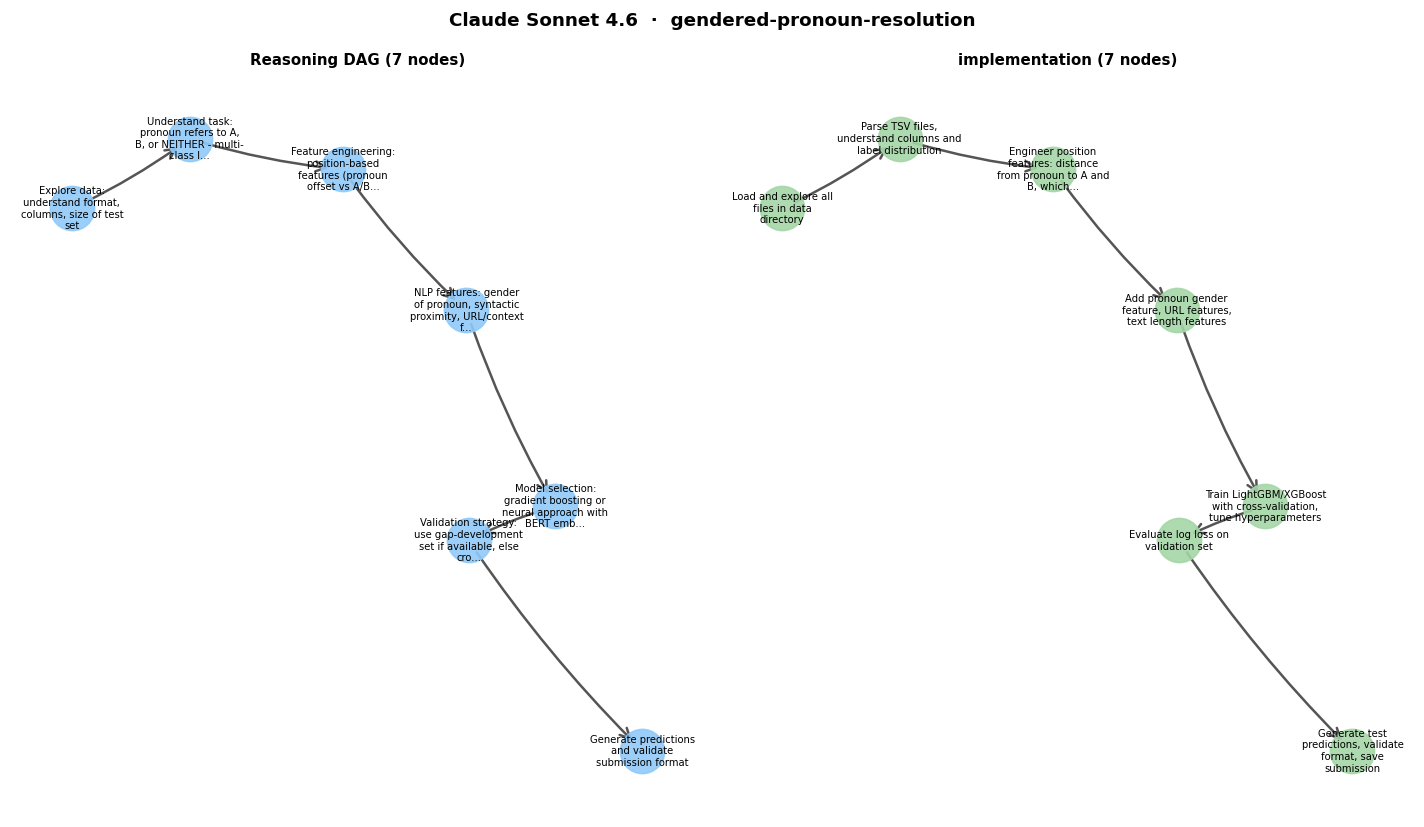

challenge:  ashrae-energy-prediction


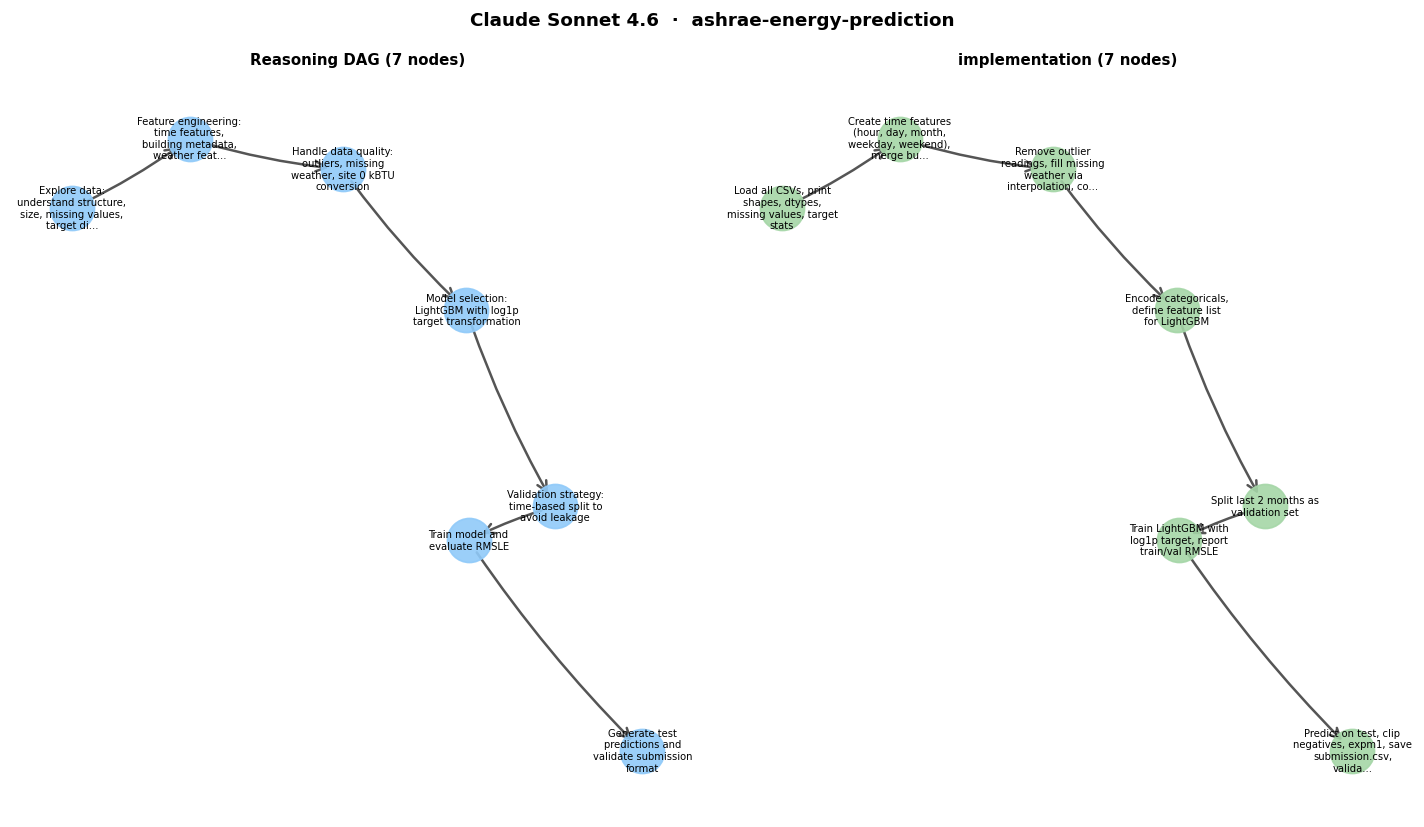

challenge:  understanding_cloud_organization


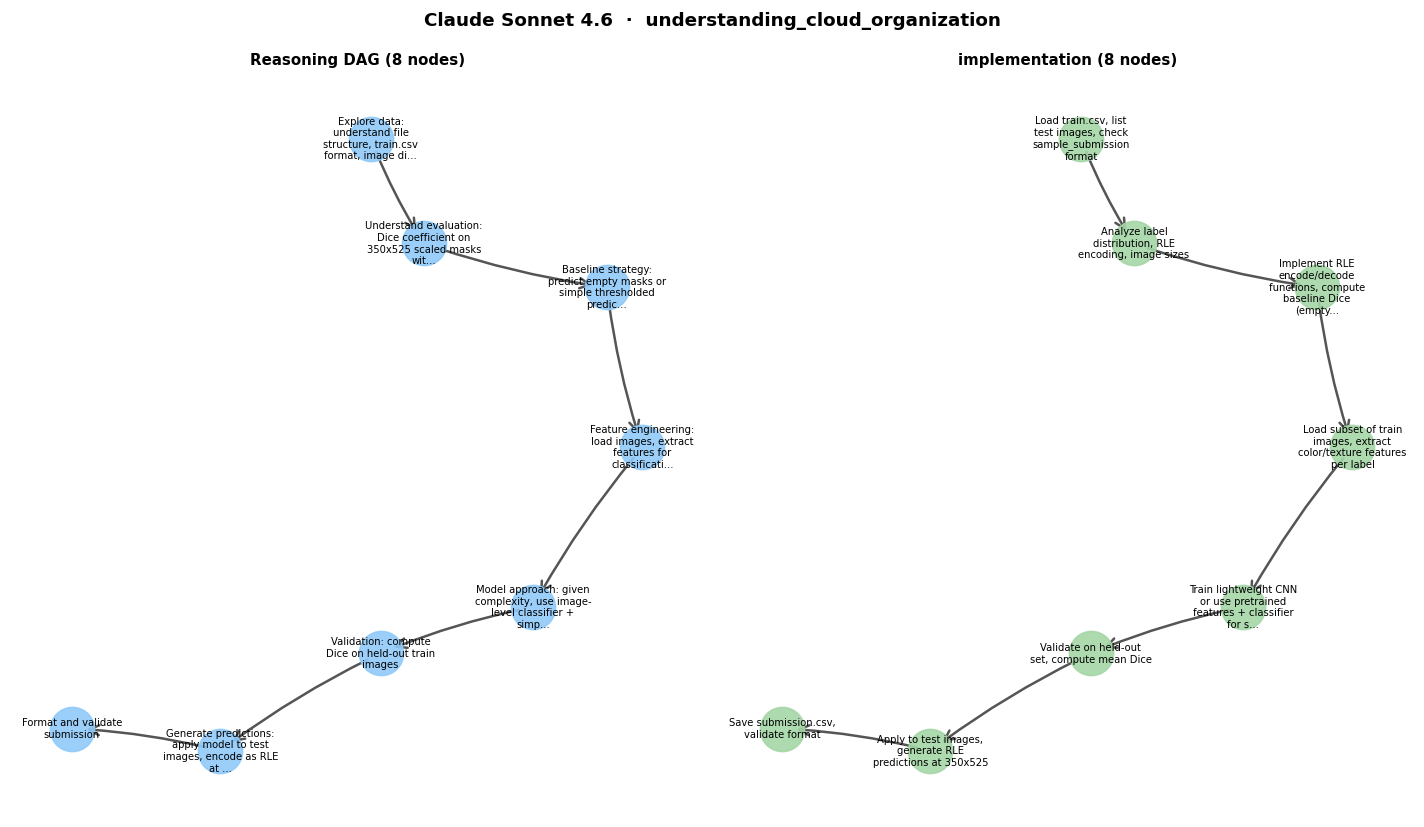

challenge:  liverpool-ion-switching


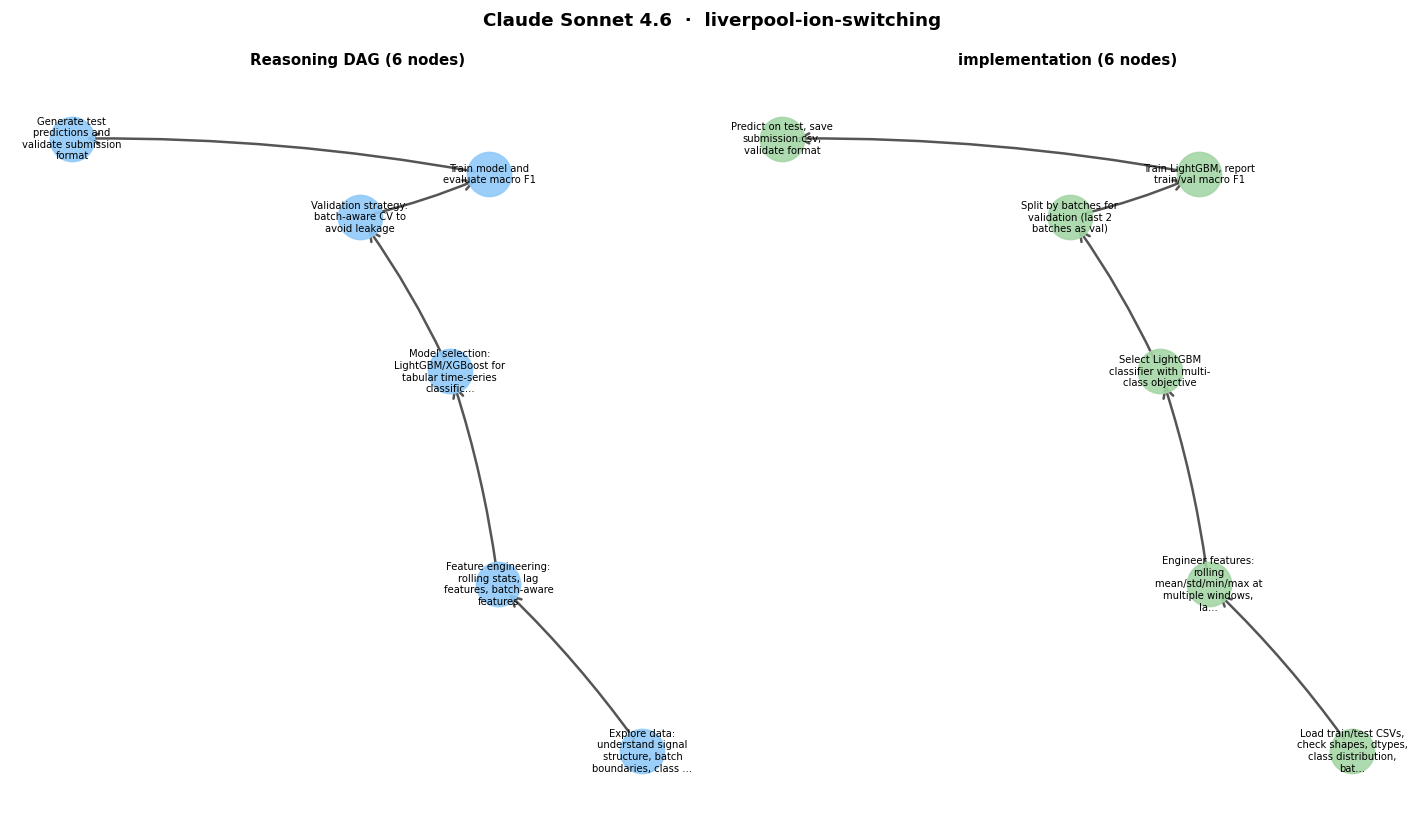

challenge:  imaterialist-challenge-furniture-2018


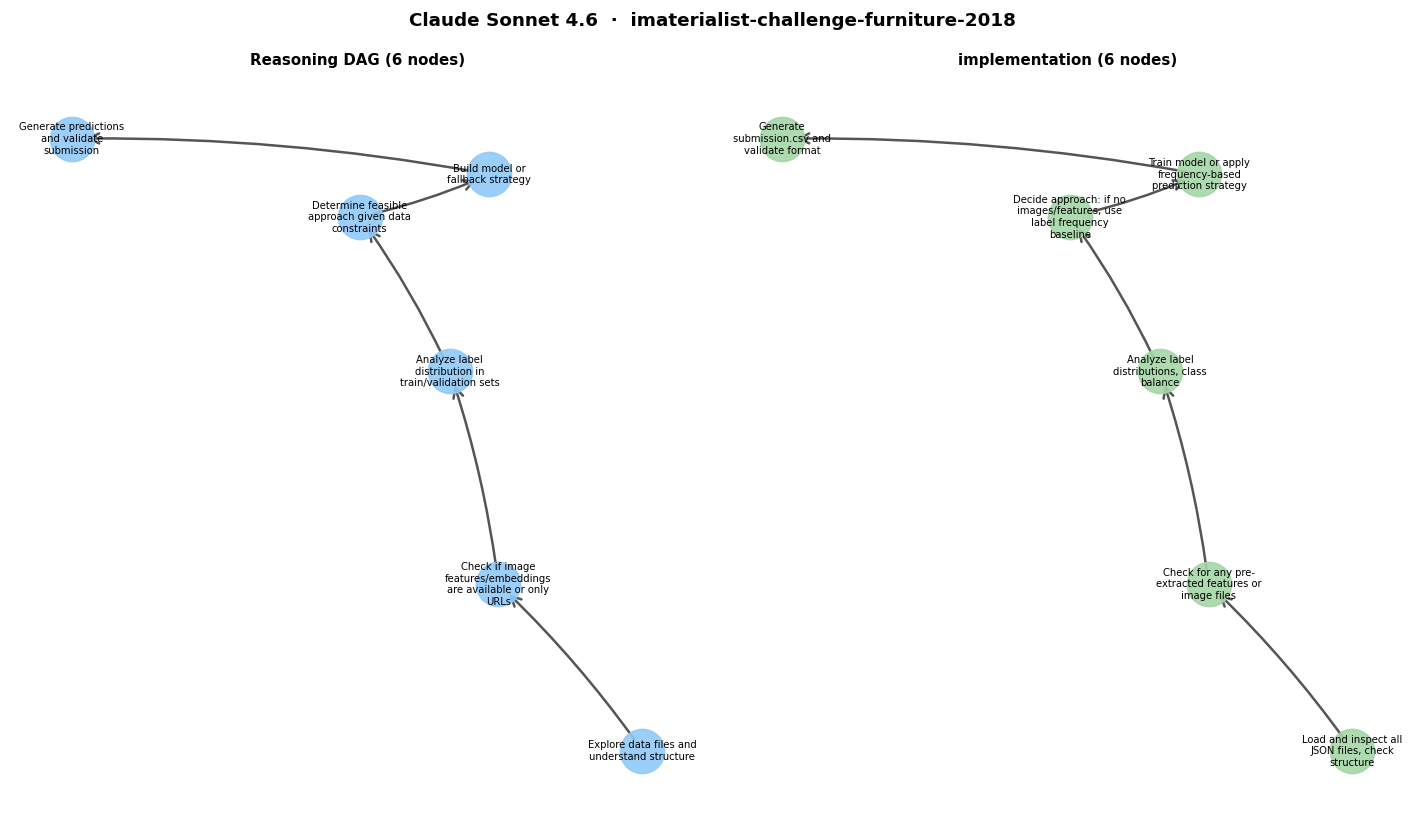

challenge:  imaterialist-challenge-fashion-2018


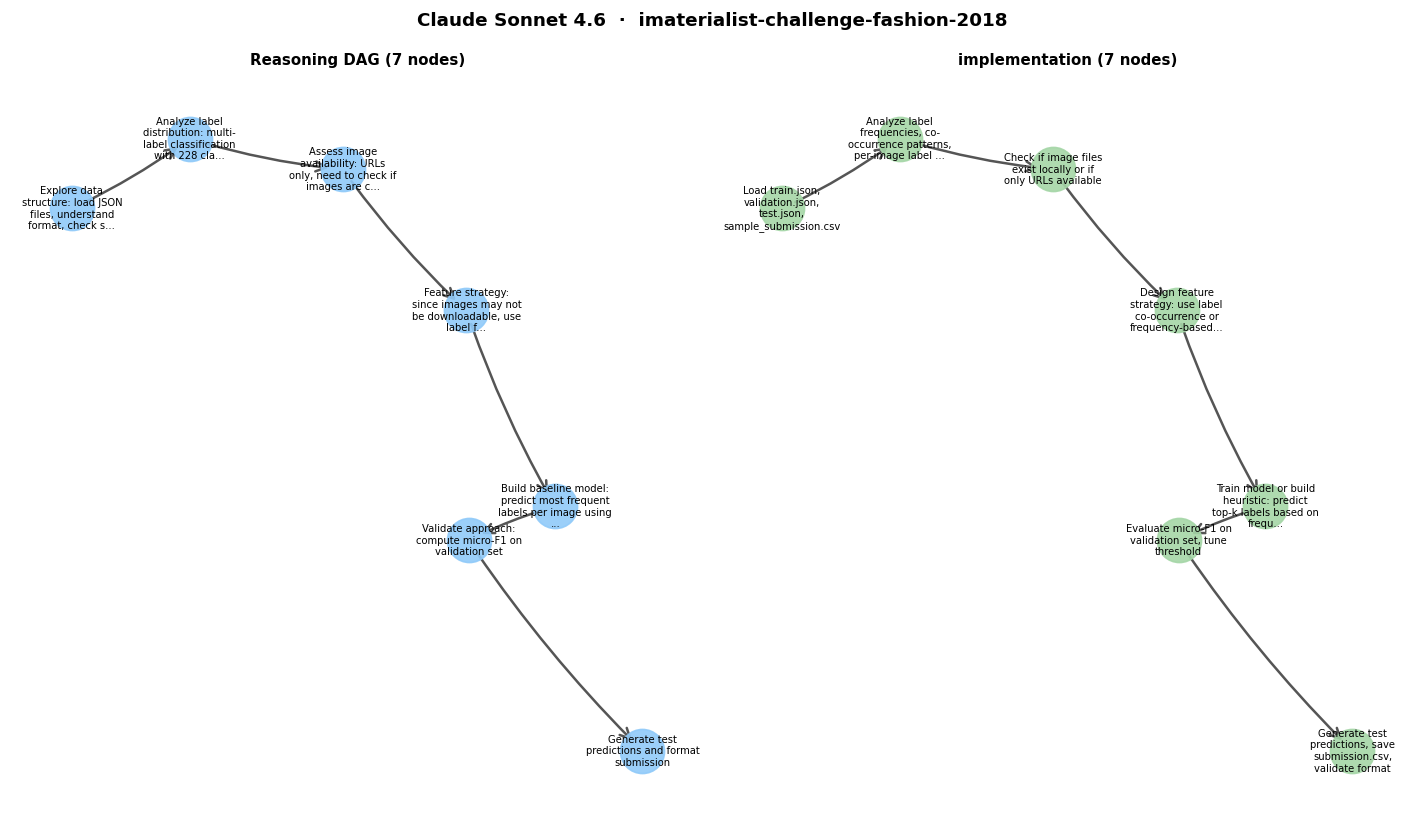

challenge:  geolifeclef-2024


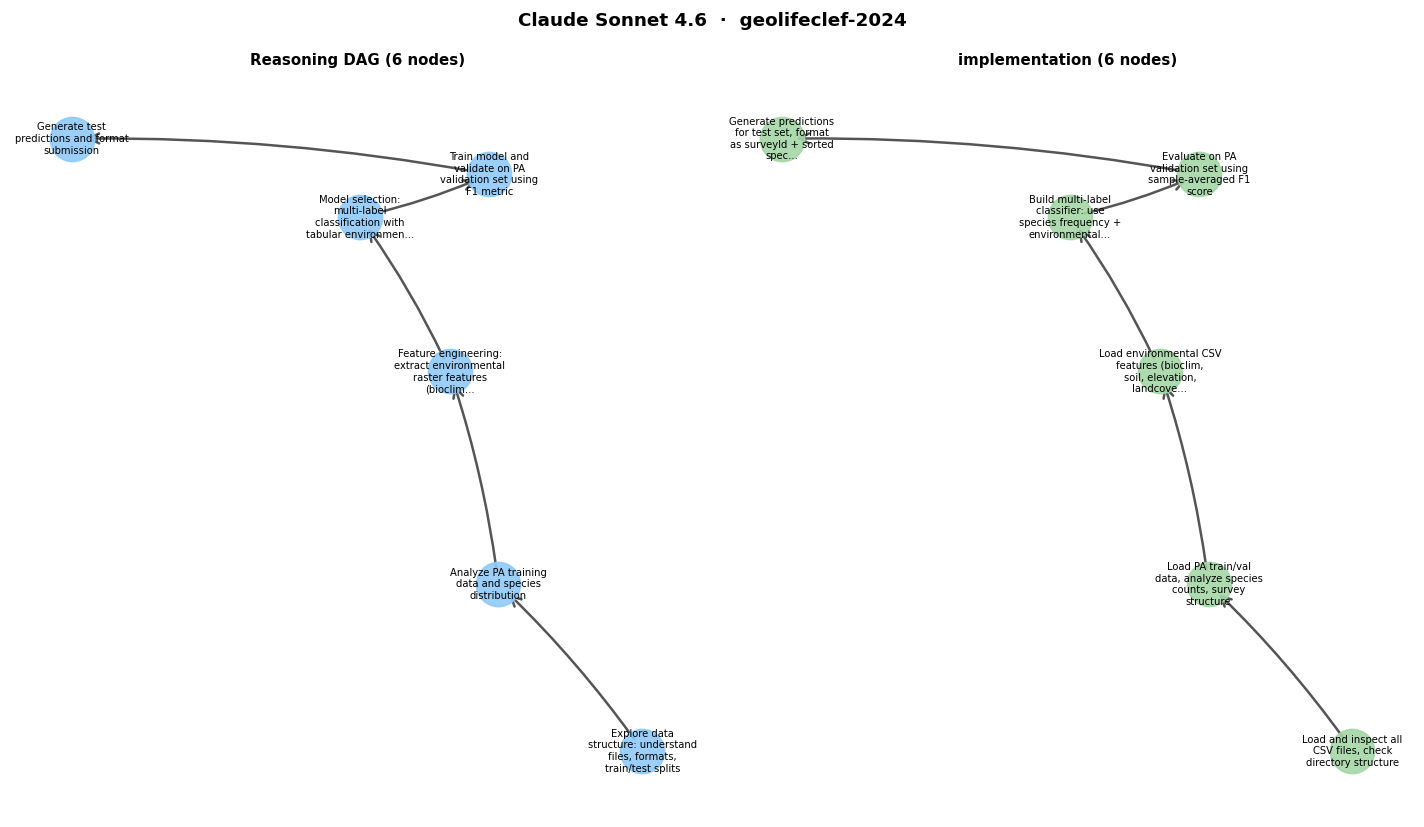

challenge:  elo-merchant-category-recommendation


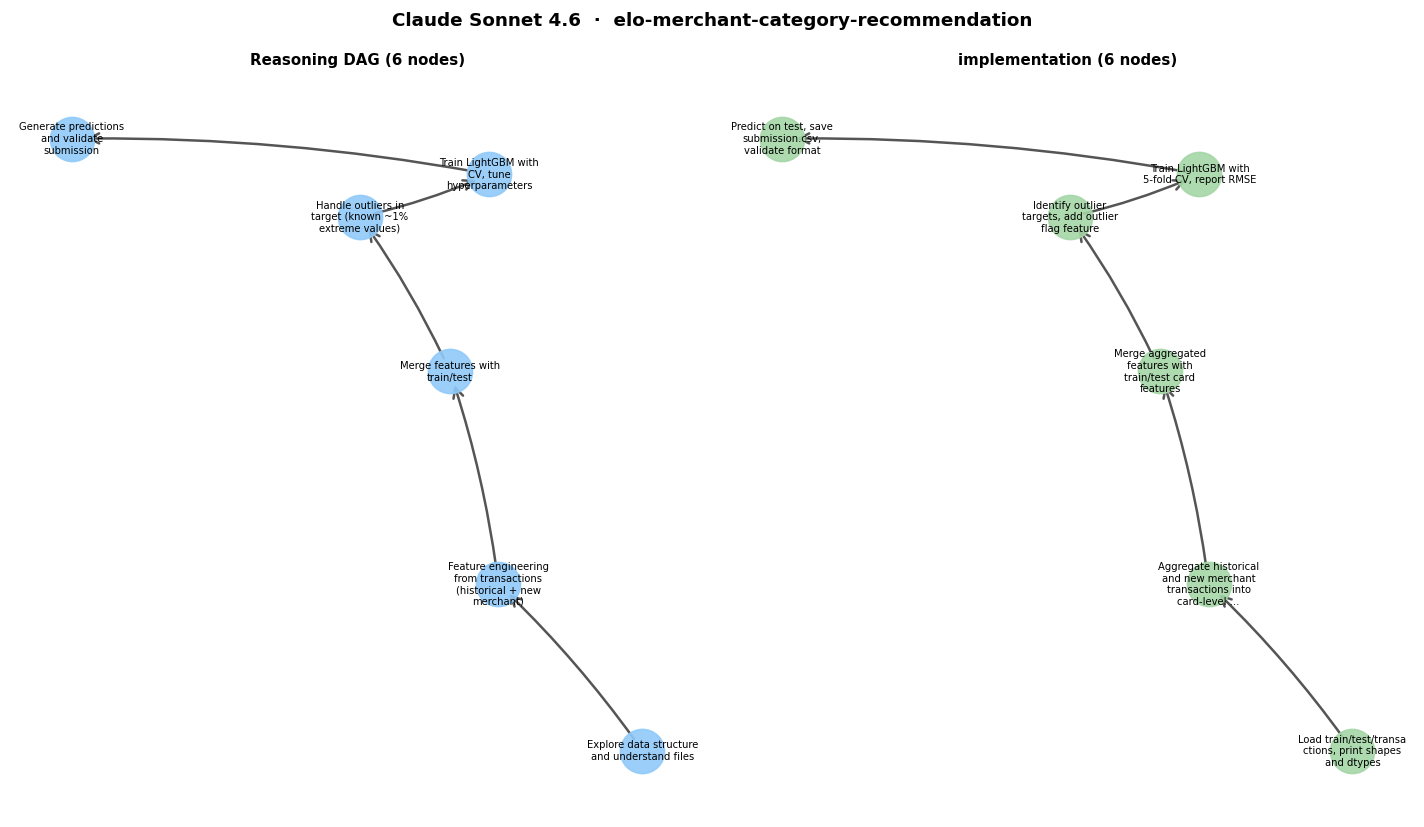

challenge:  talkingdata-adtracking-fraud-detection


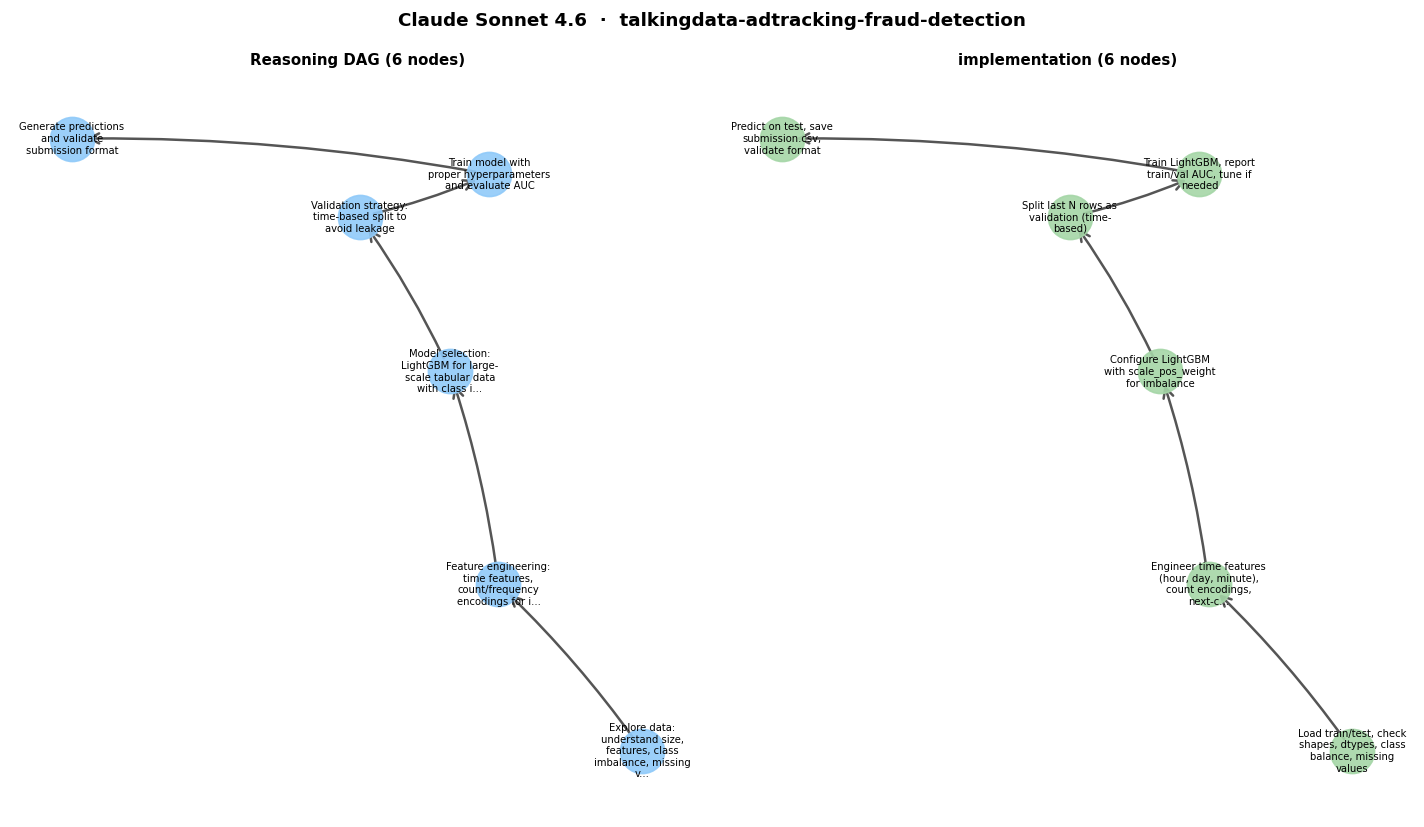

In [140]:
sample_keys = list(traj_dags.keys())

for (model, challenge) in sample_keys:
    print("challenge: ", challenge)
    dags      = traj_dags[(model, challenge)]
    reasoning = [d for d in dags if d["dag_type"] == "reasoning"]
    impl      = [d for d in dags if "implementation" in d["dag_type"]]

    n_cols = max(1, len(reasoning)) + len(impl)
    fig, axes = plt.subplots(1, n_cols, figsize=(min(6 * n_cols, 24), 7))
    if n_cols == 1:
        axes = [axes]

    fig.suptitle(f"{MODEL_LABELS.get(model, model)}  ·  {challenge}", fontsize=11, fontweight="bold")

    col = 0
    for d in reasoning:
        draw_dag(d, axes[col], f"Reasoning DAG ({len(d['nodes'])} nodes)")
        col += 1
    for d in impl:
        draw_dag(d, axes[col], f"{d['dag_type']} ({len(d['nodes'])} nodes)")
        col += 1
    while col < n_cols:
        axes[col].axis("off"); col += 1

    plt.tight_layout()
    safe = (challenge or "unknown").replace("/", "_")
    plt.savefig(RESULTS_DIR / f"dag_{model[:5]}_{safe}.png", bbox_inches="tight", dpi=120)
    plt.show()


## 4 · Cross-Benchmark Summary

Cross-benchmark models: ['Claude Sonnet 4.5', 'Claude Sonnet 4.6', 'GPT-4o Mini', 'GPT-5.1']


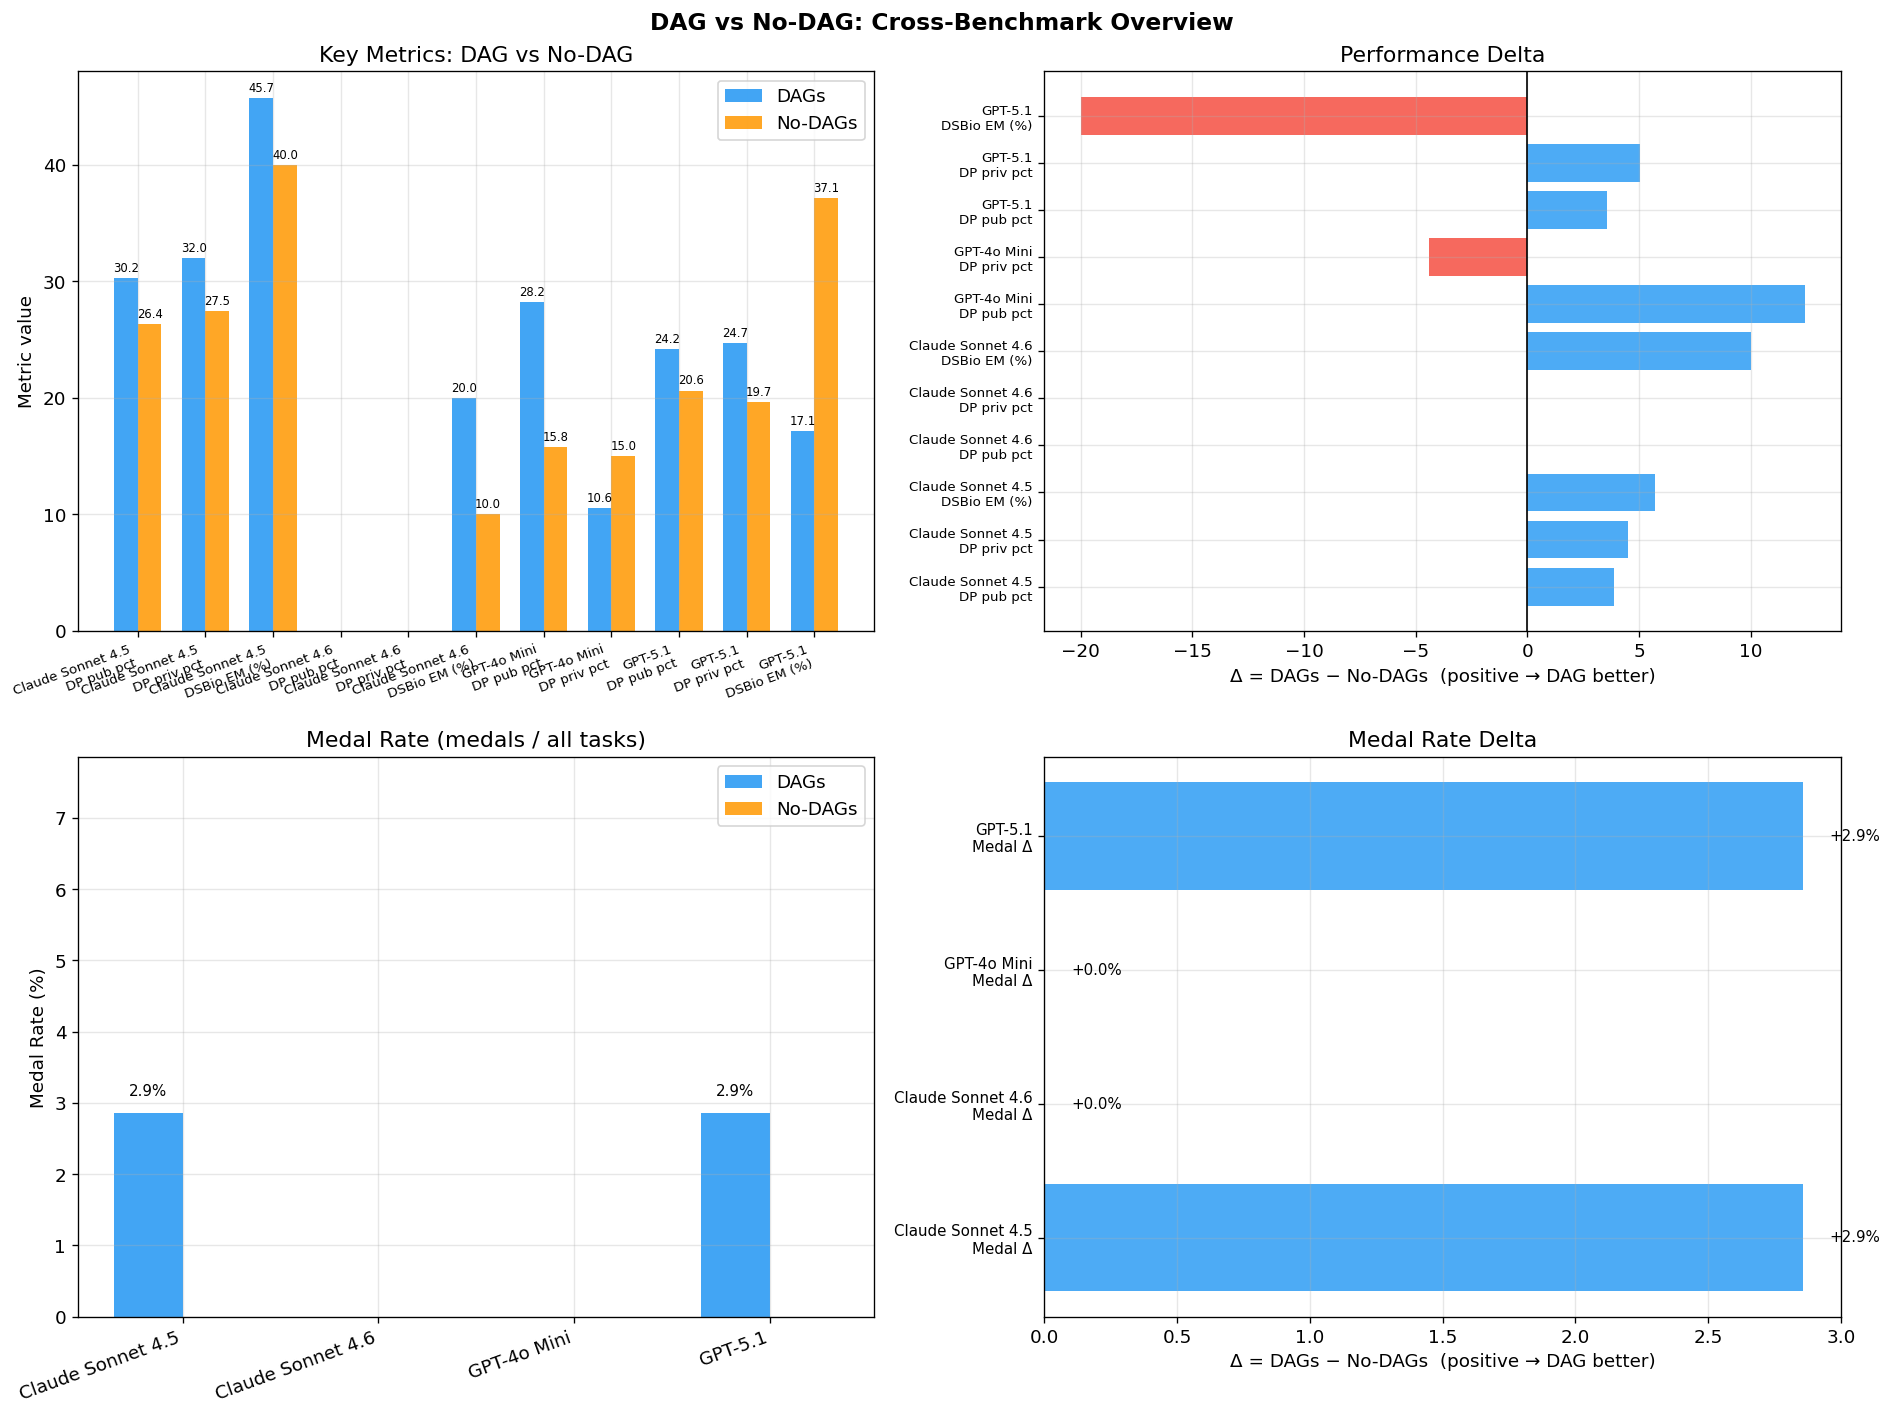


✓ All plots saved to evaluation_results/


In [141]:
# Collect all models that have both a "dags" run and a "nodags" run (in either dataset)
def _dp_vals(model, mode, key):
    data = dp_data.get((model, mode)) or dp_hard_data.get((model, mode), [])
    return [r[key] for r in data if r.get(key) is not None]

CROSS_MODELS = sorted(
    {m for (m, md) in list(dp_data.keys()) + list(dp_hard_data.keys())
     if ((m, "dags") in dp_data or (m, "dags") in dp_hard_data)
     and ((m, "nodags") in dp_data or (m, "nodags") in dp_hard_data)},
    key=lambda m: MODEL_LABELS.get(m, m)
)
print("Cross-benchmark models:", [MODEL_LABELS.get(m, m) for m in CROSS_MODELS])

metric_labels, dags_vals, nodags_vals = [], [], []
for model in CROSS_MODELS:
    short = MODEL_LABELS.get(model, model)

    dp_dag_pub    = _dp_vals(model, "dags",   "pub_percentile")
    dp_dag_priv   = _dp_vals(model, "dags",   "priv_percentile")
    dp_nodag_pub  = _dp_vals(model, "nodags", "pub_percentile")
    dp_nodag_priv = _dp_vals(model, "nodags", "priv_percentile")

    metric_labels.append(f"{short}\nDP pub pct")
    dags_vals.append(np.mean(dp_dag_pub)   if dp_dag_pub   else 0)
    nodags_vals.append(np.mean(dp_nodag_pub) if dp_nodag_pub else 0)

    metric_labels.append(f"{short}\nDP priv pct")
    dags_vals.append(np.mean(dp_dag_priv)   if dp_dag_priv   else 0)
    nodags_vals.append(np.mean(dp_nodag_priv) if dp_nodag_priv else 0)

    bio_dag   = [r["exact_match"] for r in bio_data.get((model,"dags"),   []) if r.get("exact_match") is not None]
    bio_nodag = [r["exact_match"] for r in bio_data.get((model,"nodags"), []) if r.get("exact_match") is not None]
    if bio_dag or bio_nodag:
        metric_labels.append(f"{short}\nDSBio EM (%)")
        dags_vals.append(100 * np.mean(bio_dag)   if bio_dag   else 0)
        nodags_vals.append(100 * np.mean(bio_nodag) if bio_nodag else 0)

x = np.arange(len(metric_labels)); w = 0.35
fig, axes = plt.subplots(2, 2, figsize=(max(16, len(metric_labels) * 1.1), 12))
fig.suptitle("DAG vs No-DAG: Cross-Benchmark Overview", fontsize=14, fontweight="bold")

# Top-left: grouped bar
ax = axes[0, 0]
b1 = ax.bar(x - w/2, dags_vals,   w, label="DAGs",    color=COLORS["dags"],   alpha=0.85)
b2 = ax.bar(x + w/2, nodags_vals, w, label="No-DAGs", color=COLORS["nodags"], alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels(metric_labels, fontsize=8, rotation=20, ha="right")
ax.set_ylabel("Metric value"); ax.set_title("Key Metrics: DAG vs No-DAG"); ax.legend()
for bar in [*b1, *b2]:
    h = bar.get_height()
    if h > 0:
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.3, f"{h:.1f}", ha="center", va="bottom", fontsize=7)

# Top-right: delta
ax = axes[0, 1]
deltas = [d - n for d, n in zip(dags_vals, nodags_vals)]
bar_colors_delta = ["#2196F3" if d >= 0 else "#F44336" for d in deltas]
ax.barh(range(len(metric_labels)), deltas, color=bar_colors_delta, alpha=0.8)
ax.set_yticks(range(len(metric_labels))); ax.set_yticklabels(metric_labels, fontsize=8)
ax.set_xlabel("Δ = DAGs − No-DAGs  (positive → DAG better)")
ax.set_title("Performance Delta"); ax.axvline(0, color="black", lw=1)

# Bottom-left: medal rate per model
ax = axes[1, 0]
medal_dags, medal_nodags = [], []
for model in CROSS_MODELS:
    for mode, lst in [("dags", medal_dags), ("nodags", medal_nodags)]:
        data = dp_data.get((model, mode)) or dp_hard_data.get((model, mode), [])
        sub  = [r for r in data if "COMPLETE" in str(r.get("status", ""))]
        medals = [r for r in sub if r.get("public_medal") not in (None, "none")]
        lst.append(100 * len(medals) / max(1, len(data)))
x2 = np.arange(len(CROSS_MODELS)); w2 = 0.35
b1 = ax.bar(x2 - w2/2, medal_dags,   w2, label="DAGs",    color=COLORS["dags"],   alpha=0.85)
b2 = ax.bar(x2 + w2/2, medal_nodags, w2, label="No-DAGs", color=COLORS["nodags"], alpha=0.85)
ax.set_xticks(x2)
ax.set_xticklabels([MODEL_LABELS.get(m, m) for m in CROSS_MODELS], rotation=20, ha="right")
ax.set_ylabel("Medal Rate (%)"); ax.set_title("Medal Rate (medals / all tasks)"); ax.legend()
ax.set_ylim(0, max(max(medal_dags or [0]), max(medal_nodags or [0])) + 5)
for bar in [*b1, *b2]:
    h = bar.get_height()
    if h > 0:
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.2, f"{h:.1f}%", ha="center", va="bottom", fontsize=9)

# Bottom-right: medal rate delta
ax = axes[1, 1]
medal_deltas = [d - n for d, n in zip(medal_dags, medal_nodags)]
medal_bar_colors = ["#2196F3" if d >= 0 else "#F44336" for d in medal_deltas]
ax.barh(range(len(CROSS_MODELS)), medal_deltas, color=medal_bar_colors, alpha=0.8)
ax.set_yticks(range(len(CROSS_MODELS)))
ax.set_yticklabels([f"{MODEL_LABELS.get(m, m)}\nMedal Δ" for m in CROSS_MODELS], fontsize=9)
ax.set_xlabel("Δ = DAGs − No-DAGs  (positive → DAG better)")
ax.set_title("Medal Rate Delta"); ax.axvline(0, color="black", lw=1)
for i, d in enumerate(medal_deltas):
    ax.text(d + (0.1 if d >= 0 else -0.1), i, f"{d:+.1f}%",
            ha="left" if d >= 0 else "right", va="center", fontsize=9)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "cross_benchmark_comparison.png", bbox_inches="tight", dpi=150)
plt.show()
print("\n✓ All plots saved to evaluation_results/")


## 5 · Per-Task File Loader (sanity-check helper)

Loads per-task intermediate files (e.g. `_gpt_5_1_dags.json`) the same way the Streamlit app does: one record per competition, lowest index wins.

In [77]:
import json, re
from pathlib import Path
from collections import defaultdict

RESULTS_DIR = Path(".")  # notebook lives in evaluation_results/

SKIP_LB = {"public_scores", "private_scores", "scores"}

def load_per_task_files(slug_suffix: str) -> list:
    """
    Load all per-task files matching a slug suffix, e.g. '_gpt_5_1_dags.json'.
    Returns one record per competition (deduped by comp, lowest index wins).
    """
    slug_re = re.compile(r"^(.+?)_(\d+)_(.+)$")
    seen_comp = set()
    records = []

    for fpath in sorted(RESULTS_DIR.iterdir()):   # sorted → lowest index first
        if not fpath.name.endswith(slug_suffix): continue
        m = slug_re.match(fpath.stem)
        if not m: continue
        comp = m.group(1)
        if comp in seen_comp: continue             # keep first (lowest index)
        seen_comp.add(comp)

        try:
            item = json.load(open(fpath))
        except Exception as e:
            print(f"  skip {fpath.name}: {e}"); continue

        ks      = item.get("metrics", {}).get("kaggle_submission", {})
        details = ks.get("details") or {}
        lb      = dict(details.get("leaderboard_stats", {}) or {})
        for k in SKIP_LB: lb.pop(k, None)
        tok     = item.get("token_usage") or {}

        records.append({
            "comp":            comp,
            "fname":           fpath.name,
            "sample_id":       item.get("sample_id"),
            "status":          details.get("status", ""),
            "score":           ks.get("score"),
            "pub_percentile":  details.get("public_percentile"),
            "priv_percentile": details.get("private_percentile"),
            "pub_above_med":   details.get("public_above_median"),
            "public_medal":    details.get("public_medal", "none"),
            "private_medal":   details.get("private_medal", "none"),
            "execution_time":  item.get("execution_time"),
            "total_turns":     item.get("total_turns"),
            "input_tokens":    tok.get("input_tokens"),
            "output_tokens":   tok.get("output_tokens"),
            "total_tokens":    tok.get("total_tokens"),
        })

    return records


# ── Discover all available slugs ───────────────────────────────────────────────
slug_re = re.compile(r"^.+?_\d+_(.+)$")
available_slugs = sorted({
    m.group(1)
    for f in RESULTS_DIR.iterdir()
    if f.suffix == ".json" and (m := slug_re.match(f.stem))
    and any(f.stem.endswith(s) for s in ["_dags", "_nodags", "_dags_adaptive-revision", "vanilla-no-implementation"])
})
print("Available slugs:")
for s in available_slugs:
    print(f"  _{s}.json")


Available slugs:
  _Qwen3_Coder_480B_A35B_Instruct_FP8_dags.json
  _Qwen3_Coder_480B_A35B_Instruct_dags.json
  _claude_sonnet_4_5_dags.json
  _claude_sonnet_4_5_nodags.json
  _claude_sonnet_4_6_dags.json
  _claude_sonnet_4_6_nodags.json
  _deepseek_v4_pro_dags.json
  _deepseek_v4_pro_dags_adaptive-revision.json
  _gpt_4o_mini_dags.json
  _gpt_4o_mini_dags_vanilla-no-implementation.json
  _gpt_4o_mini_nodags.json
  _gpt_5_1_dags.json
  _gpt_5_1_nodags.json
  _kimi_k2p7_code_dags.json
  _kimi_k2p7_code_dags_adaptive-revision.json
  _sonnet_4_5_dags.json


In [78]:
# ── Load one or more slugs and compare ────────────────────────────────────────
SLUGS = {
    slug: f"_{slug}.json"
    for slug in available_slugs
}

all_per_task = {label: pd.DataFrame(load_per_task_files(suffix))
                for label, suffix in SLUGS.items()}

# Summary table
summary_rows = []
for label, df in all_per_task.items():
    if df.empty: continue
    complete = df["status"].str.contains("COMPLETE", na=False).sum()
    error    = df["status"].str.contains("ERROR",    na=False).sum()
    no_sub   = len(df) - complete - error
    summary_rows.append({
        "slug":           label,
        "n_comps":        len(df),
        "complete":       complete,
        "error":          error,
        "no_submission":  no_sub,
        "avg_pub_pct":    round(df["pub_percentile"].mean(),  2) if df["pub_percentile"].notna().any()  else None,
        "avg_priv_pct":   round(df["priv_percentile"].mean(), 2) if df["priv_percentile"].notna().any() else None,
        "above_median_%": round(100 * df["pub_above_med"].sum() / 54, 1)
                          if df["pub_above_med"].notna().any() else None,
    })

pd.DataFrame(summary_rows).set_index("slug")


,n_comps,complete,error,no_submission,avg_pub_pct,avg_priv_pct,above_median_%
slug,,,,,,,
Qwen3_Coder_480B_A35B_Instruct_FP8_dags,54,0,0,54,NaN,NaN,NaN
Qwen3_Coder_480B_A35B_Instruct_dags,10,0,0,10,NaN,NaN,NaN
claude_sonnet_4_5_dags,54,27,16,11,28.05,29.34,5.6
claude_sonnet_4_5_nodags,35,11,4,20,26.35,27.47,1.9
claude_sonnet_4_6_dags,10,0,10,0,NaN,NaN,NaN
claude_sonnet_4_6_nodags,10,0,10,0,NaN,NaN,NaN
deepseek_v4_pro_dags,54,7,6,41,33.71,28.34,1.9
deepseek_v4_pro_dags_adaptive-revision,54,2,4,48,38.63,38.44,0.0
gpt_4o_mini_dags,54,5,4,45,28.20,10.57,1.9


In [10]:
gpt51_nodags_df[gpt51_nodags_df["sample_id"] == "dspredict_understanding_cloud_organization_understanding_cloud_organization"]

,sample_id,challenge,status,score,public_medal,private_medal,pub_percentile,priv_percentile,pub_above_med,pub_rank,execution_time,total_turns,success,trajectory,input_tokens,output_tokens,total_tokens
47,dspredict_understanding_cloud_organization_und...,understanding_cloud_organization,SUBMISSIONSTATUS.COMPLETE,0.47754,none,none,9.882583,9.980431,False,1372.0,3364.697344,4,True,"[{'turn': 0, 'role': 'assistant', 'content': '...",None,None,None


In [36]:
gpt51_nodags_df[gpt51_nodags_df["sample_id"] == "dspredict_understanding_cloud_organization_understanding_cloud_organization"]

,sample_id,challenge,status,score,public_medal,private_medal,pub_percentile,priv_percentile,pub_above_med,pub_rank,execution_time,total_turns,success,trajectory,input_tokens,output_tokens,total_tokens
47,dspredict_understanding_cloud_organization_understanding_cloud_organization,understanding_cloud_organization,SUBMISSIONSTATUS.COMPLETE,0.47754,none,none,9.882583,9.980431,False,1372.0,3364.697344,4,True,"[{'turn': 0, 'role': 'assistant', 'content': '<reasoning> I'll first inspect the directory struc...",None,None,None


In [24]:
gpt51_dags_df = all_per_task[('gpt_5_1_dags')]

In [33]:
gpt51_dags_df[gpt51_dags_df["sample_id"] == "dspredict_understanding_cloud_organization_understanding_cloud_organization"]

,comp,fname,sample_id,status,score,pub_percentile,priv_percentile,pub_above_med,public_medal,private_medal,execution_time,total_turns,input_tokens,output_tokens,total_tokens
47,understanding_cloud_organization,understanding_cloud_organization_3_gpt_5_1_dags.json,dspredict_understanding_cloud_organization_understanding_cloud_organization,SUBMISSIONSTATUS.COMPLETE,0.43322,7.762557,7.958252,False,none,none,1144.619135,14,None,None,None


In [38]:
gpt51_dags_df[gpt51_dags_df["sample_id"] == "dspredict_understanding_cloud_organization_understanding_cloud_organization"]["fname"]

47    understanding_cloud_organization_3_gpt_5_1_dags.json
Name: fname, dtype: str

In [39]:
gpt4o_dags_df = all_per_task[('gpt_4o_mini_dags')]

In [46]:
gpt4o_nodags_df = all_per_task[('gpt_4o_mini_nodags')]

In [79]:
gpt4o_vanilla_df = all_per_task[('gpt_4o_mini_dags_vanilla-no-implementation')]

In [60]:
deepseek_dags_df = all_per_task[('deepseek_v4_pro_dags')] 

In [61]:
deepseek_adaptive_dags_df = all_per_task[('deepseek_v4_pro_dags_adaptive-revision')]

In [45]:
gpt4o_dags_df[gpt4o_dags_df["sample_id"] == "dspredict_career-con-2019_career-con-2019"]

,comp,fname,sample_id,status,score,pub_percentile,priv_percentile,pub_above_med,public_medal,private_medal,execution_time,total_turns,input_tokens,output_tokens,total_tokens
2,career-con-2019,career-con-2019_2_gpt_4o_mini_dags.json,dspredict_career-con-2019_career-con-2019,SUBMISSIONSTATUS.COMPLETE,0.129,0.83045,1.418685,False,none,none,1694.978277,12,84991,4054,89045


In [47]:
gpt4o_nodags_df[gpt4o_nodags_df["sample_id"] == "dspredict_career-con-2019_career-con-2019"]

,comp,fname,sample_id,status,score,pub_percentile,priv_percentile,pub_above_med,public_medal,private_medal,execution_time,total_turns,input_tokens,output_tokens,total_tokens
2,career-con-2019,career-con-2019_2_gpt_4o_mini_nodags.json,dspredict_career-con-2019_career-con-2019,SUBMISSIONSTATUS.COMPLETE,0.1296,0.83045,1.730104,False,none,none,3518.632231,13,82482,4365,86847


In [62]:
deepseek_dags_df[deepseek_dags_df["sample_id"] == 'dspredict_digit-recognizer_digit-recognizer']

,comp,fname,sample_id,status,score,pub_percentile,priv_percentile,pub_above_med,public_medal,private_medal,execution_time,total_turns,input_tokens,output_tokens,total_tokens
5,digit-recognizer,digit-recognizer_5_deepseek_v4_pro_dags.json,dspredict_digit-recognizer_digit-recognizer,SUBMISSIONSTATUS.COMPLETE,0.99178,73.724213,NaN,True,none,none,1155.662152,12,1236921,7266,1244187


In [63]:
deepseek_adaptive_dags_df[deepseek_adaptive_dags_df["sample_id"] == "dspredict_digit-recognizer_digit-recognizer"]

,comp,fname,sample_id,status,score,pub_percentile,priv_percentile,pub_above_med,public_medal,private_medal,execution_time,total_turns,input_tokens,output_tokens,total_tokens
5,digit-recognizer,digit-recognizer_5_deepseek_v4_pro_dags_adaptive-revision.json,dspredict_digit-recognizer_digit-recognizer,SUBMISSIONSTATUS.COMPLETE,0.98253,39.413681,NaN,False,none,none,3885.9961,15,140679,9238,149917


In [65]:
gpt4o_dags_df[gpt4o_dags_df["sample_id"] == "dspredict_home-data-for-ml-course_home-data-for-ml-course"]

,comp,fname,sample_id,status,score,pub_percentile,priv_percentile,pub_above_med,public_medal,private_medal,execution_time,total_turns,input_tokens,output_tokens,total_tokens
11,home-data-for-ml-course,home-data-for-ml-course_11_gpt_4o_mini_dags.json,dspredict_home-data-for-ml-course_home-data-for-ml-course,SUBMISSIONSTATUS.COMPLETE,16736.35459,57.741935,NaN,True,none,none,596.178037,10,68935,3625,72560


In [80]:
gpt4o_vanilla_df[gpt4o_vanilla_df["sample_id"] == "dspredict_home-data-for-ml-course_home-data-for-ml-course"]

,comp,fname,sample_id,status,score,pub_percentile,priv_percentile,pub_above_med,public_medal,private_medal,execution_time,total_turns,input_tokens,output_tokens,total_tokens
11,home-data-for-ml-course,home-data-for-ml-course_11_gpt_4o_mini_dags_vanilla-no-implementation.json,dspredict_home-data-for-ml-course_home-data-for-ml-course,SUBMISSIONSTATUS.COMPLETE,15577.16369,90.230415,NaN,True,bronze,none,106.908565,12,139150,4468,143618


In [87]:
foo = all_per_task[('gpt_5_1_dags')]

In [78]:
foo

,comp,fname,sample_id,status,score,pub_percentile,priv_percentile,pub_above_med,public_medal,private_medal,execution_time,total_turns,input_tokens,output_tokens,total_tokens
0,LANL-Earthquake-Prediction,LANL-Earthquake-Prediction_0_gpt_5_1_dags.json,dspredict_LANL-Earthquake-Prediction_LANL-Eart...,SUBMISSIONSTATUS.COMPLETE,2.79591,4.967913,7.136535,False,none,none,4237.918622,11,None,None,None
1,ashrae-energy-prediction,ashrae-energy-prediction_1_gpt_5_1_dags.json,dspredict_ashrae-energy-prediction_ashrae-ener...,SUBMISSIONSTATUS.COMPLETE,1.36700,22.647550,30.164254,False,none,none,1604.250659,11,None,None,None
2,career-con-2019,career-con-2019_14_gpt_5_1_dags.json,dspredict_career-con-2019_career-con-2019,SUBMISSIONSTATUS.COMPLETE,0.12780,0.761246,1.176471,False,none,none,1353.470047,9,None,None,None
3,champs-scalar-coupling,champs-scalar-coupling_3_gpt_5_1_dags.json,dspredict_champs-scalar-coupling_champs-scalar...,SUBMISSIONSTATUS.ERROR,NaN,NaN,NaN,None,none,none,6602.366421,10,None,None,None
4,data-science-bowl-2018,data-science-bowl-2018_4_gpt_5_1_dags.json,dspredict_data-science-bowl-2018_data-science-...,SUBMISSIONSTATUS.ERROR,NaN,NaN,NaN,None,none,none,521.374891,13,None,None,None
5,digit-recognizer,digit-recognizer_11_gpt_5_1_dags.json,dspredict_digit-recognizer_digit-recognizer,SUBMISSIONSTATUS.COMPLETE,0.97332,26.981542,NaN,False,none,none,1393.164914,9,None,None,None
6,elo-merchant-category-recommendation,elo-merchant-category-recommendation_6_gpt_5_1...,dspredict_elo-merchant-category-recommendation...,SUBMISSIONSTATUS.COMPLETE,3.92305,12.819265,13.208465,False,none,none,4334.964281,15,None,None,None
7,gendered-pronoun-resolution,gendered-pronoun-resolution_1_gpt_5_1_dags.json,dspredict_gendered-pronoun-resolution_gendered...,SUBMISSIONSTATUS.ERROR,NaN,NaN,NaN,None,none,none,74.955451,5,None,None,None
8,geolifeclef-2024,geolifeclef-2024_7_gpt_5_1_dags.json,dspredict_geolifeclef-2024_geolifeclef-2024,SUBMISSIONSTATUS.COMPLETE,0.24301,35.000000,35.000000,False,none,none,796.503818,11,None,None,None
9,google-smartphone-decimeter-challenge,google-smartphone-decimeter-challenge_9_gpt_5_...,dspredict_google-smartphone-decimeter-challeng...,,NaN,NaN,NaN,None,none,none,2747.029696,11,None,None,None


In [90]:
foo[foo["pub_above_med"] == True]

,comp,fname,sample_id,status,score,pub_percentile,priv_percentile,pub_above_med,public_medal,private_medal,execution_time,total_turns,input_tokens,output_tokens,total_tokens
11,home-data-for-ml-course,home-data-for-ml-course_11_gpt_5_1_dags.json,dspredict_home-data-for-ml-course_home-data-fo...,SUBMISSIONSTATUS.COMPLETE,14253.68117,90.411779,NaN,True,bronze,none,128.258263,11,None,None,None
23,mens-machine-learning-competition-2019,mens-machine-learning-competition-2019_23_gpt_...,dspredict_mens-machine-learning-competition-20...,SUBMISSIONSTATUS.COMPLETE,0.49945,52.259560,NaN,True,none,none,13563.399536,12,None,None,None
26,nlp-getting-started,nlp-getting-started_22_gpt_5_1_dags.json,dspredict_nlp-getting-started_nlp-getting-started,SUBMISSIONSTATUS.COMPLETE,0.80294,53.683241,NaN,True,none,none,1367.070686,7,None,None,None
32,predict-ai-model-runtime,predict-ai-model-runtime_19_gpt_5_1_dags.json,dspredict_predict-ai-model-runtime_predict-ai-...,SUBMISSIONSTATUS.COMPLETE,0.24077,58.346840,19.286872,True,none,none,2037.153232,11,None,None,None
46,trec-covid-information-retrieval,trec-covid-information-retrieval_26_gpt_5_1_da...,dspredict_trec-covid-information-retrieval_tre...,SUBMISSIONSTATUS.COMPLETE,0.21697,85.000000,90.000000,True,silver,gold,1324.586512,8,None,None,None


In [60]:
pd.DataFrame(above_median)

,sample_id,challenge,status,score,public_medal,private_medal,pub_percentile,priv_percentile,pub_above_med,pub_rank,execution_time,total_turns,success,trajectory,input_tokens,output_tokens,total_tokens
0,dspredict_home-data-for-ml-course_home-data-fo...,home-data-for-ml-course,SUBMISSIONSTATUS.COMPLETE,16602.03686,none,none,68.456221,NaN,True,1370,3868.527761,10,True,"[{'turn': 0, 'role': 'assistant', 'content': '...",None,None,None
1,dspredict_m5-forecasting-accuracy_m5-forecasti...,m5-forecasting-accuracy,SUBMISSIONSTATUS.COMPLETE,0.00000,gold,none,93.595485,62.710498,True,1,4259.230781,4,False,"[{'turn': 0, 'role': 'assistant', 'content': '...",None,None,None
2,dspredict_spaceship-titanic_spaceship-titanic,spaceship-titanic,SUBMISSIONSTATUS.COMPLETE,0.80149,none,none,59.872461,NaN,True,840,3656.721380,8,True,"[{'turn': 0, 'role': 'assistant', 'content': '...",None,None,None
3,dspredict_trec-covid-information-retrieval_tre...,trec-covid-information-retrieval,SUBMISSIONSTATUS.COMPLETE,0.18872,silver,silver,85.000000,85.000000,True,4,3815.531017,11,True,"[{'turn': 0, 'role': 'assistant', 'content': '...",None,None,None


In [23]:
foo_nodags = dp_hard_data[('gpt-5.1', 'nodags')]
pub_pct = []
priv_pct = []
pub_above_med = []
priv_above_med = []
for i in foo_nodags:
    if i["pub_percentile"]:
        pub_pct.append(i)
    if i["priv_percentile"]:
        priv_pct.append(i)
    if i["pub_above_med"]:
        pub_above_med.append(i)
    if i.get("private_above_med", None):
        priv_above_med.append(i)

In [85]:
pd.DataFrame(priv_above_med)

""


In [86]:
pd.DataFrame(pub_above_med)

,sample_id,challenge,status,score,public_medal,private_medal,pub_percentile,priv_percentile,pub_above_med,pub_rank,execution_time,total_turns,success,trajectory,input_tokens,output_tokens,total_tokens
0,dspredict_home-data-for-ml-course_home-data-fo...,home-data-for-ml-course,SUBMISSIONSTATUS.COMPLETE,16602.03686,none,none,68.456221,NaN,True,1370,3868.527761,10,True,"[{'turn': 0, 'role': 'assistant', 'content': '...",None,None,None
1,dspredict_m5-forecasting-accuracy_m5-forecasti...,m5-forecasting-accuracy,SUBMISSIONSTATUS.COMPLETE,0.00000,gold,none,93.595485,62.710498,True,1,4259.230781,4,False,"[{'turn': 0, 'role': 'assistant', 'content': '...",None,None,None
2,dspredict_spaceship-titanic_spaceship-titanic,spaceship-titanic,SUBMISSIONSTATUS.COMPLETE,0.80149,none,none,59.872461,NaN,True,840,3656.721380,8,True,"[{'turn': 0, 'role': 'assistant', 'content': '...",None,None,None
3,dspredict_trec-covid-information-retrieval_tre...,trec-covid-information-retrieval,SUBMISSIONSTATUS.COMPLETE,0.18872,silver,silver,85.000000,85.000000,True,4,3815.531017,11,True,"[{'turn': 0, 'role': 'assistant', 'content': '...",None,None,None
